In [4]:
# Max Orbital = 3
# How to pertube this Hamiltonian for specific targeted state ?
# Green function method for including the temperature dependence

'''
This code is for 3D Hubbard Model Simulation and finding the corresponing eigenvalues and eigenvectors for the Hamiltonian. 
'''
import os
import sys
import time
import math
import gc
import numpy as np
from numpy import linalg as LA

# ----------------------------------------------------------------------
# Bit‐position helper
# ----------------------------------------------------------------------
def bitpos(site, orb, spin, n_orb):
    """
    Return bit position of (site, orbital, spin).
      - site:    0 ≤ site < n_sites
      - orb:     0 ≤ orb < n_orb
      - spin:    0 for down, 1 for up
    The bit index in the integer representation is:
        2 * (site * n_orb + orb) + spin
    """
    return 2 * (site * n_orb + orb) + spin

# ----------------------------------------------------------------------
# Geometry definitions
# ----------------------------------------------------------------------
GEOMETRIES = {
    1: {
        "name": "Tetrahedron (4 sites)",
        # Sites 0–1–2 form a base triangle, 3 is the apex.
        # Edges with type "base" use t_base; edges with "vert" use t_vert.
        "edges": [
            (0, 1, "base"),
            (1, 2, "base"),
            (2, 0, "base"),
            (0, 3, "vert"),
            (1, 3, "vert"),
            (2, 3, "vert"),
        ],
        "n_sites": 4
    },
    2: {
        "name": "Square Pyramid (5 sites)",
        # Sites 0–1–2–3 form a square base; site 4 is the apex.
        # Base edges use t_base; apex‐to‐base edges use t_vert.
        "edges": [
            (0, 1, "base"),
            (1, 2, "base"),
            (2, 3, "base"),
            (3, 0, "base"),
            (0, 4, "vert"),
            (1, 4, "vert"),
            (2, 4, "vert"),
            (3, 4, "vert"),
        ],
        "n_sites": 5
    },
    3: {
        "name": "Square Bipyramid (6 sites)",
        # Square bipyramid: base = square 0–1–2–3, two apexes 4 (top), 5 (bottom).
        # Base edges use t_base; apex-to-base edges use t_vert.
        "edges": [
            (0, 1, "base"),
            (1, 2, "base"),
            (2, 3, "base"),
            (3, 0, "base"),
            (0, 4, "vert"),
            (1, 4, "vert"),
            (2, 4, "vert"),
            (3, 4, "vert"),
            (0, 5, "vert"),
            (1, 5, "vert"),
            (2, 5, "vert"),
            (3, 5, "vert"),
        ],
        "n_sites": 6
    }
}

# ----------------------------------------------------------------------
# Build the Hamiltonian matrix
# ----------------------------------------------------------------------
def build_hamiltonian(n_sites, n_orb, w_orb, t_base, t_vert, U, edges):
    """
    Build and return the dense Hamiltonian H for a given geometry.
      - n_sites : number of lattice sites
      - n_orb   : orbitals per site
      - w_orb   : list of orbital weights (length n_orb)
      - t_base  : hopping amplitude on "base" edges
      - t_vert  : hopping amplitude on "vert" edges
      - U       : on-site Coulomb repulsion
      - edges   : list of tuples (i, j, edge_type) where edge_type ∈ {"base","vert"}
    """
    # Total number of basis states = 4^(n_sites * n_orb)
    dim = 4 ** (n_sites * n_orb)
    H = np.zeros((dim, dim), dtype=np.float64)

    # Helper for selecting the correct hopping amplitude
    def hop_amplitude(edge_type):
        return t_base if edge_type == "base" else t_vert

    # Loop over every Fock‐basis configuration "state"
    for state in range(dim):
        # 1) Diagonal U‐term: sum U for every site s and orbital o if both spins are occupied
        diag = 0.0
        for s in range(n_sites):
            for o in range(n_orb):
                b_down = bitpos(s, o, 0, n_orb)
                b_up   = bitpos(s, o, 1, n_orb)
                if ((state >> b_down) & 1) and ((state >> b_up) & 1):
                    diag += U
        H[state, state] = diag

        # 2) Off‐diagonal hopping terms
        # To ensure H is Hermitian and avoid double-counting, we build only the
        # upper triangle (new_state > state) and then explicitly symmetrize later.
        for (i, j, e_type) in edges:
            t_hop = hop_amplitude(e_type)
            for o in range(n_orb):
                w = w_orb[o]
                for spin in (0, 1):
                    bi = bitpos(i, o, spin, n_orb)
                    bj = bitpos(j, o, spin, n_orb)
                    
                    # If electron present at i and empty at j, hop i→j
                    if ((state >> bi) & 1) and not ((state >> bj) & 1):
                        new_state = state ^ (1 << bi) ^ (1 << bj)
                        
                        # Add element to the upper triangle of H
                        if state < new_state:
                            val = -w * t_hop
                            H[state, new_state] += val

    # Symmetrize the matrix to create the full Hamiltonian
    H = H + H.T - np.diag(np.diag(H))
    return H

# ----------------------------------------------------------------------
# Prompt user for input parameters
# ----------------------------------------------------------------------
def read_user_inputs(geometry_choice):
    """
    Prompts user for common parameters:
      - M     : orbitals per site
      - w_orb : list of M orbital weights
      - t_base: hopping on base edges
      - t_vert: hopping on vertical edges (apex connections)
      - U     : on-site Coulomb repulsion
    Returns tuple (M, w_orb, t_base, t_vert, U)
    """
    print(f"\nYou selected: {GEOMETRIES[geometry_choice]['name']}")
    print("Enter number of orbitals per site (M ≥ 1): ", end="")
    M = int(input().strip())
    if M < 1:
        sys.exit("Error: M must be ≥ 1.")

    w_orb = []
    print("Enter orbital weights w_0 ... w_{M-1}:")
    for o in range(M):
        print(f"  w_{o} = ", end="")
        w_orb.append(float(input().strip()))

    print("Enter base-edge hopping t_base = ", end="")
    t_base = float(input().strip())
    print("Enter vertical-edge hopping t_vert = ", end="")
    t_vert = float(input().strip())
    print("Enter on‐site Coulomb repulsion U = ", end="")
    U = float(input().strip())

    return M, w_orb, t_base, t_vert, U

# ----------------------------------------------------------------------
# Main driver
# ----------------------------------------------------------------------
def main():
    # 1) Prompt user to choose geometry
    print("Choose cluster geometry:")
    for key in sorted(GEOMETRIES.keys()):
        print(f"  {key}. {GEOMETRIES[key]['name']}")
    print("Enter choice (1/2/3): ", end="")
    try:
        choice = int(input().strip())
    except ValueError:
        sys.exit("Invalid choice. Exiting.")
    if choice not in GEOMETRIES:
        sys.exit("Choice not in {1,2,3}. Exiting.")

    geom = GEOMETRIES[choice]
    n_sites = geom["n_sites"]
    edges   = geom["edges"]

    # 2) Read orbitals, weights, hoppings, U
    M, w_orb, t_base, t_vert, U = read_user_inputs(choice)

    # 3) Build Hamiltonian
    print("\nBuilding Hamiltonian matrix …")
    t0 = time.time()
    H = build_hamiltonian(n_sites, M, w_orb, t_base, t_vert, U, edges)
    gc.collect()
    t1 = time.time()
    dim = H.shape[0]
    print(f"  Dimension = {dim} × {dim}")
    print(f"  Construction time = {t1 - t0:.3f} s")

    # 4) Diagonalize
    print("Diagonalising …")
    t2 = time.time()
    eigenvalues, eigenvectors = LA.eigh(H)
    t3 = time.time()
    print(f"  Diagonalization time = {t3 - t2:.3f} s\n")

    # 5) Print eigenvalues
    print("--- Eigenvalues (ascending) ---")
    for idx, ev in enumerate(eigenvalues):
        print(f"  E_{idx:<4d} = {ev: .8f}")
    
    # 6) Print eigenvectors
    print("\n--- Eigenvectors (first 2) ---")
    
    # Print Ground State Eigenvector (k=0)
    print(f"\nψ₀ (for E₀ = {eigenvalues[0]:.8f}):")
    print(eigenvectors[:, 0])

    # Print First Excited State Eigenvector (k=1)
    if dim > 1:
        print(f"\nψ₁ (for E₁ = {eigenvalues[1]:.8f}):")
        print(eigenvectors[:, 1])

    print("\nDone.")

if __name__ == "__main__":
    main()


Choose cluster geometry:
  1. Tetrahedron (4 sites)
  2. Square Pyramid (5 sites)
  3. Square Bipyramid (6 sites)
Enter choice (1/2/3): 
You selected: Tetrahedron (4 sites)
Enter number of orbitals per site (M ≥ 1): Enter orbital weights w_0 ... w_{M-1}:
  w_0 = Enter base-edge hopping t_base = Enter vertical-edge hopping t_vert = Enter on‐site Coulomb repulsion U = 
Building Hamiltonian matrix …
  Dimension = 256 × 256
  Construction time = 0.025 s
Diagonalising …
  Diagonalization time = 0.009 s

--- Eigenvalues (ascending) ---
  E_0    = -5.79793651
  E_1    = -5.47114358
  E_2    = -5.47114358
  E_3    = -4.88538487
  E_4    = -4.47114358
  E_5    = -4.47114358
  E_6    = -4.41871432
  E_7    = -4.41871432
  E_8    = -3.70156212
  E_9    = -3.37228132
  E_10   = -3.37228132
  E_11   = -3.25744640
  E_12   = -3.25744640
  E_13   = -3.11009207
  E_14   = -2.88538487
  E_15   = -2.82842712
  E_16   = -2.76465310
  E_17   = -2.76465310
  E_18   = -2.56155281
  E_19   = -2.56155281
  E_

In [ ]:
# Max Orbital = 3
# How to pertube this Hamiltonian for specific targeted state ?
# Green function method for including the temperature dependence

'''
This code is for 3D Hubbard Model Simulation and finding the corresponing eigenvalues, eigenvectors for the Hamiltonian. In addition, 
it also evaluates Total Particle Number & Dominant Real-Space Configurations by transforming the eigenvectors back to the real space.
'''
import os
import sys
import time
import math
import gc
import numpy as np
from numpy import linalg as LA

# ----------------------------------------------------------------------
# Bit‐position helper
# ----------------------------------------------------------------------
def bitpos(site, orb, spin, n_orb):
    """
    Return bit position of (site, orbital, spin).
      - site:    0 ≤ site < n_sites
      - orb:     0 ≤ orb < n_orb
      - spin:    0 for down, 1 for up
    The bit index in the integer representation is:
        2 * (site * n_orb + orb) + spin
    """
    return 2 * (site * n_orb + orb) + spin

# ----------------------------------------------------------------------
# Geometry definitions
# ----------------------------------------------------------------------
GEOMETRIES = {
    1: {
        "name": "Tetrahedron (4 sites)",
        "edges": [(0, 1, "base"), (1, 2, "base"), (2, 0, "base"), (0, 3, "vert"), (1, 3, "vert"), (2, 3, "vert")],
        "n_sites": 4
    },
    2: {
        "name": "Square Pyramid (5 sites)",
        "edges": [(0, 1, "base"), (1, 2, "base"), (2, 3, "base"), (3, 0, "base"), (0, 4, "vert"), (1, 4, "vert"), (2, 4, "vert"), (3, 4, "vert")],
        "n_sites": 5
    },
    3: {
        "name": "Square Bipyramid (6 sites)",
        "edges": [(0, 1, "base"), (1, 2, "base"), (2, 3, "base"), (3, 0, "base"), (0, 4, "vert"), (1, 4, "vert"), (2, 4, "vert"), (3, 4, "vert"), (0, 5, "vert"), (1, 5, "vert"), (2, 5, "vert"), (3, 5, "vert")],
        "n_sites": 6
    }
}

# ----------------------------------------------------------------------
# Build the Hamiltonian matrix
# ----------------------------------------------------------------------
def build_hamiltonian(n_sites, n_orb, w_orb, t_base, t_vert, U, edges):
    """
    Build and return the dense, symmetric Hamiltonian H for a given geometry.
      - n_sites : number of lattice sites
      - n_orb   : orbitals per site
      - w_orb   : list of orbital weights (length n_orb)
      - t_base  : hopping amplitude on "base" edges
      - t_vert  : hopping amplitude on "vert" edges
      - U       : on-site Coulomb repulsion
      - edges   : list of tuples (i, j, edge_type) where edge_type ∈ {"base","vert"}
    """
    dim = 4 ** (n_sites * n_orb)
    H = np.zeros((dim, dim), dtype=np.float64)

    def hop_amplitude(edge_type):
        return t_base if edge_type == "base" else t_vert

    for state in range(dim):
        # 1) Diagonal U‐term: sum U for every site s and orbital o if both spins occupied
        diag = 0.0
        for s in range(n_sites):
            for o in range(n_orb):
                b_down = bitpos(s, o, 0, n_orb)
                b_up   = bitpos(s, o, 1, n_orb)
                if ((state >> b_down) & 1) and ((state >> b_up) & 1):
                    diag += U
        H[state, state] = diag

        # 2) Off‐diagonal hopping terms
        for (i, j, e_type) in edges:
            t_hop = hop_amplitude(e_type)
            for o in range(n_orb):
                w = w_orb[o]
                for spin in (0, 1):
                    bi = bitpos(i, o, spin, n_orb)
                    bj = bitpos(j, o, spin, n_orb)
                    if ((state >> bi) & 1) and not ((state >> bj) & 1):
                        new_state = state ^ (1 << bi) ^ (1 << bj)
                        if state < new_state:
                            val = -w * t_hop
                            H[state, new_state] += val

    # Symmetrize the matrix to create the full, Hermitian Hamiltonian
    H = H + H.T - np.diag(np.diag(H))
    return H

# ----------------------------------------------------------------------
# Eigenstate Analysis
# ----------------------------------------------------------------------
def popcount(n):
    """Counts the number of set bits (1s) in an integer's binary representation."""
    return bin(n).count('1')

def analyze_eigenstates(eigenvalues, eigenvectors, n_sites, n_orb, num_to_analyze=10, prob_cutoff=0.01):
    """
    Analyzes the calculated eigenstates to extract physical quantities.
    - Calculates total particle number <N> for each state.
    - Identifies and prints the dominant real-space configurations.
    
    Args:
        eigenvalues (np.array): The energy eigenvalues.
        eigenvectors (np.array): The eigenvectors (as columns).
        n_sites (int): Number of sites in the geometry.
        n_orb (int): Number of orbitals per site.
        num_to_analyze (int): The number of low-energy states to analyze in detail.
        prob_cutoff (float): The minimum probability for a configuration to be displayed.
    """
    dim = eigenvectors.shape[0]
    num_bits = 2 * n_sites * n_orb
    
    # Pre-calculate the number of particles for each basis state |j>
    popcounts_per_state = np.array([popcount(j) for j in range(dim)])
    
    print("\n" + "="*70)
    print(" E I G E N S T A T E   A N A L Y S I S")
    print("="*70)

    for k in range(min(num_to_analyze, dim)):
        psi_k = eigenvectors[:, k]
        energy_k = eigenvalues[k]
        
        # Calculate probabilities |α_kj|^2 for each basis state |j>
        probabilities = np.abs(psi_k)**2
        
        # Calculate the expectation value of the total particle number <N>
        # <N>_k = <ψ_k|N_op|ψ_k> = Σ_j |α_kj|^2 * popcount(j)
        N_k = np.sum(probabilities * popcounts_per_state)
        
        print(f"\n--- State k={k} ---")
        print(f"  Energy E_{k}      = {energy_k:.8f}")
        print(f"  Total Particles <N> = {N_k:.4f}")
        
        # Sort configurations by their probability in descending order
        sorted_indices = np.argsort(probabilities)[::-1]
        
        print(f"  Dominant Configurations (Probability > {prob_cutoff:.0%}):")
        print(f"  {'Basis State |j⟩':>16} | {'Binary Representation':^{num_bits}} | {'Probability |α(k,j)|²'}")
        print(f"  {'-'*16}-+-{'-'*num_bits}-+-{'-'*22}")
        
        total_prob_shown = 0.0
        for j_idx in sorted_indices:
            prob = probabilities[j_idx]
            if prob >= prob_cutoff:
                total_prob_shown += prob
                binary_rep = format(j_idx, f'0{num_bits}b')
                print(f"  {j_idx:16d} | {binary_rep} | {prob:.6f} ({prob:6.2%})")
        print(f"  {'-'*16}-+-{'-'*num_bits}-+-{'-'*22}")
        print(f"  (Configurations shown account for {total_prob_shown:.2%} of the total probability)")

# ----------------------------------------------------------------------
# Main driver
# ----------------------------------------------------------------------
def main():
    # 1) Prompt for geometry
    print("Choose cluster geometry:")
    for key in sorted(GEOMETRIES.keys()):
        print(f"  {key}. {GEOMETRIES[key]['name']}")
    print("Enter choice (1/2/3): ", end="")
    try:
        choice = int(input().strip())
    except ValueError:
        sys.exit("Invalid choice. Exiting.")
    if choice not in GEOMETRIES:
        sys.exit("Choice not in {1,2,3}. Exiting.")

    geom = GEOMETRIES[choice]
    n_sites = geom["n_sites"]
    edges   = geom["edges"]

    # 2) Read parameters
    print(f"\nYou selected: {GEOMETRIES[choice]['name']}")
    print("Enter number of orbitals per site (M ≥ 1): ", end="")
    M = int(input().strip())
    if M < 1: sys.exit("Error: M must be ≥ 1.")
    
    w_orb = []
    print("Enter orbital weights w_0 ... w_{M-1}:")
    for o in range(M):
        print(f"  w_{o} = ", end="")
        w_orb.append(float(input().strip()))

    print("Enter base-edge hopping t_base = ", end="")
    t_base = float(input().strip())
    print("Enter vertical-edge hopping t_vert = ", end="")
    t_vert = float(input().strip())
    print("Enter on‐site Coulomb repulsion U = ", end="")
    U = float(input().strip())

    # 3) Build Hamiltonian
    print("\nBuilding Hamiltonian matrix …")
    t0 = time.time()
    H = build_hamiltonian(n_sites, M, w_orb, t_base, t_vert, U, edges)
    gc.collect()
    t1 = time.time()
    dim = H.shape[0]
    print(f"  Dimension = {dim} × {dim}")
    print(f"  Construction time = {t1 - t0:.3f} s")

    # 4) Diagonalize
    print("Diagonalising …")
    t2 = time.time()
    eigenvalues, eigenvectors = LA.eigh(H)
    t3 = time.time()
    print(f"  Diagonalization time = {t3 - t2:.3f} s\n")

    # 5) Analyze Eigenstates
    # The eigenvalues and eigenvectors are the necessary inputs for future extensions,
    # such as calculating Green's functions via the Lehmann representation:
    # G(ω) = Σ_k |ψ_k><ψ_k| / (ω - E_k + iη)
    print("How many of the lowest-energy states would you like to analyze in detail?")
    try:
        num_to_analyze = int(input("Enter number: ").strip())
    except ValueError:
        print("Invalid number, defaulting to 10.")
        num_to_analyze = 10

    analyze_eigenstates(eigenvalues, eigenvectors, n_sites, M, num_to_analyze=num_to_analyze)

    print("\nDone.")

if __name__ == "__main__":
    main()


Choose cluster geometry:
  1. Tetrahedron (4 sites)
  2. Square Pyramid (5 sites)
  3. Square Bipyramid (6 sites)
Enter choice (1/2/3): 
You selected: Tetrahedron (4 sites)
Enter number of orbitals per site (M ≥ 1): Enter orbital weights w_0 ... w_{M-1}:
  w_0 = Enter base-edge hopping t_base = Enter vertical-edge hopping t_vert = Enter on‐site Coulomb repulsion U = 
Building Hamiltonian matrix …
  Dimension = 256 × 256
  Construction time = 0.028 s
Diagonalising …
  Diagonalization time = 0.011 s

How many of the lowest-energy states would you like to analyze in detail?

 E I G E N S T A T E   A N A L Y S I S

--- State k=0 ---
  Energy E_0      = -5.79793651
  Total Particles <N> = 4.0000
  Dominant Configurations (Probability > 1%):
   Basis State |j⟩ | Binary Representation | Probability |α(k,j)|²
  -----------------+----------+-----------------------
               153 | 10011001 | 0.056686 ( 5.67%)
               102 | 01100110 | 0.056686 ( 5.67%)
               204 | 11001100 | 

In [18]:
# Max Orbital = 3 - Done
# How to pertube this Hamiltonian for specific targeted state ? - Done
# Green function method for including the temperature dependence
# Introduction to Quantum Mechanics - David Griffiths
# Frequency or grequency range which prefers a perticualr state of the systems - if a paired state is found ?
# We can tune the whole mirroscopic spin to have half filled states. For qbit manipulation

'''
This code is for 3D Hubbard Model Simulation and finds the following :

1. Eigenvalues and Eigenvectors for the Hamiltonian
2. Total Particle Number and Dominant Real-Space Configurations by transforming the eigenvectors back to the real space
3. Pertube the Hamiltonian with Electic Field and then find the new Eigenvalues and Eigenvectors
4. Observe the changes before and after pertubation of Electric Field.
'''
import os
import sys
import time
import math
import gc
import numpy as np
from numpy import linalg as LA

# ----------------------------------------------------------------------
# Bit‐position helper
# ----------------------------------------------------------------------
def bitpos(site, orb, spin, n_orb):
    """
    Return bit position of (site, orbital, spin).
      - site:    0 ≤ site < n_sites
      - orb:     0 ≤ orb < n_orb
      - spin:    0 for down, 1 for up
    The bit index in the integer representation is:
        2 * (site * n_orb + orb) + spin
    """
    return 2 * (site * n_orb + orb) + spin

# ----------------------------------------------------------------------
# Geometry and Coordinate definitions
# ----------------------------------------------------------------------
GEOMETRIES = {
    1: {
        "name": "Tetrahedron (4 sites)",
        "n_sites": 4,
        "edges": [(0, 1, "base"), (1, 2, "base"), (2, 0, "base"), (0, 3, "vert"), (1, 3, "vert"), (2, 3, "vert")],
        # Coordinates for a regular tetrahedron centered at the origin
        "coords": np.array([
            [ 1,  1,  1],
            [ 1, -1, -1],
            [-1,  1, -1],
            [-1, -1,  1]
        ]) / np.sqrt(3)
    },
    2: {
        "name": "Square Pyramid (5 sites)",
        "n_sites": 5,
        "edges": [
            (0, 1, "base"), (1, 2, "base"), (2, 3, "base"), (3, 0, "base"), # Base
            (0, 4, "vert"), (1, 4, "vert"), (2, 4, "vert"), (3, 4, "vert")  # Apex
        ],
        # Coordinates for a square pyramid centered at the origin
        "coords": np.array([
            [ 1,  1, 0], # Base vertex 0
            [-1,  1, 0], # Base vertex 1
            [-1, -1, 0], # Base vertex 2
            [ 1, -1, 0], # Base vertex 3
            [ 0,  0, 1]  # Apex vertex 4
        ])
    },
    3: {
        "name": "Square Bipyramid (6 sites)",
        "n_sites": 6,
        "edges": [
            (0, 1, "base"), (1, 2, "base"), (2, 3, "base"), (3, 0, "base"), # Base
            (0, 4, "vert"), (1, 4, "vert"), (2, 4, "vert"), (3, 4, "vert"), # Top Apex
            (0, 5, "vert"), (1, 5, "vert"), (2, 5, "vert"), (3, 5, "vert")  # Bottom Apex
        ],
        # Coordinates for a square bipyramid (octahedron) centered at the origin
        "coords": np.array([
            [ 1,  0,  0], # Vertex 0 on x-axis
            [-1,  0,  0], # Vertex 1 on x-axis
            [ 0,  1,  0], # Vertex 2 on y-axis
            [ 0, -1,  0], # Vertex 3 on y-axis
            [ 0,  0,  1], # Vertex 4 on z-axis (top apex)
            [ 0,  0, -1]  # Vertex 5 on z-axis (bottom apex)
        ])
    }
}

# ----------------------------------------------------------------------
# Build the Hamiltonian matrix
# ----------------------------------------------------------------------
def build_hamiltonian(n_sites, n_orb, w_orb, t_base, t_vert, U, edges, site_coords, E_field):
    """
    Build and return the dense, symmetric Hamiltonian H, including electric field perturbation.
      - E_field: (Ex, Ey, Ez) vector for the external electric field.
      - site_coords: A (n_sites x 3) numpy array of site coordinates.
      
    """
    dim = 4 ** (n_sites * n_orb)
    H = np.zeros((dim, dim), dtype=np.float64)

    def hop_amplitude(edge_type):
        return t_base if edge_type == "base" else t_vert

    # Loop over every Fock‐basis configuration "state"
    for state in range(dim):
        # --- 1) Diagonal Terms ---
        diag_energy = 0.0
        
        # a) On-site Coulomb repulsion (U term)
        for s in range(n_sites):
            for o in range(n_orb):
                b_down = bitpos(s, o, 0, n_orb)
                b_up   = bitpos(s, o, 1, n_orb)
                if ((state >> b_down) & 1) and ((state >> b_up) & 1):
                    diag_energy += U
        
        # b) Electric field perturbation (Stark effect)
       
        if np.linalg.norm(E_field) > 1e-12: 
            for s in range(n_sites):
                # Sum over all orbitals and spins at site 's'
                num_electrons_at_site = 0
                for o in range(n_orb):
                    for spin in (0, 1):
                        b = bitpos(s, o, spin, n_orb)
                        if (state >> b) & 1: 
                            num_electrons_at_site += 1
                diag_energy += num_electrons_at_site * np.dot(E_field, site_coords[s])

        H[state, state] = diag_energy

        # --- 2) Off-diagonal hopping terms ---
        for (i, j, e_type) in edges:
            t_hop = hop_amplitude(e_type)
            for o in range(n_orb):
                w = w_orb[o]
                for spin in (0, 1):
                    bi = bitpos(i, o, spin, n_orb)
                    bj = bitpos(j, o, spin, n_orb)
                    if ((state >> bi) & 1) and not ((state >> bj) & 1):
                        new_state = state ^ (1 << bi) ^ (1 << bj)
                        if state < new_state: 
                            val = -w * t_hop
                            H[state, new_state] += val

    # Symmetrize the matrix to create the full, Hermitian Hamiltonian
    H = H + H.T - np.diag(np.diag(H))
    return H

# ----------------------------------------------------------------------
# Eigenstate Analysis
# ----------------------------------------------------------------------
def popcount(n):
    """Counts the number of set bits (1s) in an integer's binary representation."""
    return bin(n).count('1')

def analyze_eigenstates(title, eigenvalues, eigenvectors, n_sites, n_orb, site_coords, num_to_analyze=10, prob_cutoff=0.01):
    """
    Analyzes and prints physical quantities for the calculated eigenstates.
    - Calculates electric dipole moment <P> for each state.
    """
    dim = eigenvectors.shape[0]
    num_bits = 2 * n_sites * n_orb
    
    popcounts_per_state = np.array([popcount(j) for j in range(dim)])
    
    # Pre-calculate the dipole moment for each basis state |j>
    dipole_moment_per_state = np.zeros((dim, 3))
    for j in range(dim):
        p_vec = np.zeros(3)
        for s in range(n_sites):
            num_electrons_at_site = 0
            for o in range(n_orb):
                for spin in (0, 1):
                    b = bitpos(s, o, spin, n_orb)
                    if (j >> b) & 1: num_electrons_at_site += 1
            # P = sum(q * r) over all electrons. With q=-1, P = -sum(r).
            p_vec -= num_electrons_at_site * site_coords[s]
        dipole_moment_per_state[j] = p_vec

    print("\n" + "="*80)
    print(f" E I G E N S T A T E   A N A L Y S I S: {title.upper()}")
    print("="*80)

    for k in range(min(num_to_analyze, dim)):
        psi_k = eigenvectors[:, k]
        energy_k = eigenvalues[k]
        probabilities = np.abs(psi_k)**2
        
        N_k = np.sum(probabilities * popcounts_per_state)
        # <P>_k = <ψ_k|P_op|ψ_k> = Σ_j |α_kj|^2 * P_j
        P_k = np.sum(probabilities[:, np.newaxis] * dipole_moment_per_state, axis=0)

        print(f"\n--- State k={k} ---")
        print(f"  Energy E_{k}                = {energy_k:.8f}")
        print(f"  Total Particles <N>       = {N_k:.4f}")
        print(f"  Dipole Moment <P> (xyz) = [{P_k[0]: .4f}, {P_k[1]: .4f}, {P_k[2]: .4f}]")
        
        print(f"  Dominant Configurations (Probability > {prob_cutoff:.0%}):")
        header = f"  {'Basis State |j⟩':>16} | {'Binary Rep':^{num_bits}} | {'Probability'}"
        print(header)
        print(f"  {'-'*16}-+-{'-'*num_bits}-+-{'-'*11}")
        
        for j_idx in np.argsort(probabilities)[::-1]:
            if probabilities[j_idx] >= prob_cutoff:
                binary_rep = format(j_idx, f'0{num_bits}b')
                print(f"  {j_idx:16d} | {binary_rep} | {probabilities[j_idx]:.4f}")
        print(f"  {'-'*16}-+-{'-'*num_bits}-+-{'-'*11}")

# ----------------------------------------------------------------------
# Main driver
# ----------------------------------------------------------------------
def main():
    # --- 1) Setup ---
    print("Choose cluster geometry:")
    for key, value in GEOMETRIES.items():
        print(f"  {key}. {value['name']}")
    
    try:
        choice = int(input("Enter choice: ").strip())
        if choice not in GEOMETRIES:
            raise ValueError
    except ValueError:
        sys.exit("Invalid choice. Exiting.")

    geom = GEOMETRIES[choice]
    n_sites, edges, site_coords = geom["n_sites"], geom["edges"], geom["coords"]

    print(f"\nYou selected: {geom['name']}")
    M = int(input("Enter number of orbitals per site (M ≥ 1): ").strip())
    if M < 1: sys.exit("Error: M must be >= 1")

    w_orb = [float(input(f"  Enter orbital weight w_{o} = ").strip()) for o in range(M)]
    t_base = float(input("Enter base-edge hopping t_base = ").strip())
    t_vert = float(input("Enter vertical-edge hopping t_vert = ").strip())
    U = float(input("Enter on‐site Coulomb repulsion U = ").strip())
    
    # --- 2) "BEFORE" CALCULATION (Zero Electric Field) ---
    print("\n--- Running simulation for ZERO electric field (E=0) ---")
    E_field_before = np.array([0.0, 0.0, 0.0])
    H_before = build_hamiltonian(n_sites, M, w_orb, t_base, t_vert, U, edges, site_coords, E_field_before)
    evals_before, evecs_before = LA.eigh(H_before)
    
    num_to_analyze = int(input("How many states to analyze in detail? ").strip())
    analyze_eigenstates("BEFORE (E=0)", evals_before, evecs_before, n_sites, M, site_coords, num_to_analyze)

    # --- 3) "AFTER" CALCULATION (User-defined Electric Field) ---
    print("\n--- Now, specify an electric field to see its effect ---")
    Ex = float(input("Enter electric field component Ex: ").strip())
    Ey = float(input("Enter electric field component Ey: ").strip())
    Ez = float(input("Enter electric field component Ez: ").strip())
    E_field_after = np.array([Ex, Ey, Ez])

    print(f"\n--- Running simulation for E = ({Ex}, {Ey}, {Ez}) ---")
    H_after = build_hamiltonian(n_sites, M, w_orb, t_base, t_vert, U, edges, site_coords, E_field_after)
    evals_after, evecs_after = LA.eigh(H_after)
    analyze_eigenstates("AFTER (E≠0)", evals_after, evecs_after, n_sites, M, site_coords, num_to_analyze)
    
    # --- 4) SUMMARY OF CHANGES ---
    ground_energy_before = evals_before[0]
    ground_energy_after = evals_after[0]
    stark_shift = ground_energy_after - ground_energy_before
    
    print("\n" + "="*80)
    print(" C O M P A R I S O N   S U M M A R Y")
    print("="*80)
    print("Ground State Energy (E_0):")
    print(f"  - Before (E=0): {ground_energy_before:.8f}")
    print(f"  - After  (E≠0): {ground_energy_after:.8f}")
    print(f"  - Stark Shift (ΔE_0): {stark_shift:.8f}")
    
    print("\nDone.")

if __name__ == "__main__":
    main()


Choose cluster geometry:
  1. Tetrahedron (4 sites)
  2. Square Pyramid (5 sites)
  3. Square Bipyramid (6 sites)

You selected: Tetrahedron (4 sites)

--- Running simulation for ZERO electric field (E=0) ---

 E I G E N S T A T E   A N A L Y S I S: BEFORE (E=0)

--- State k=0 ---
  Energy E_0                = -5.79793651
  Total Particles <N>       = 4.0000
  Dipole Moment <P> (xyz) = [-0.0000, -0.0000, -0.0000]
  Dominant Configurations (Probability > 1%):
   Basis State |j⟩ | Binary Rep | Probability
  -----------------+----------+------------
               153 | 10011001 | 0.0567
               102 | 01100110 | 0.0567
               204 | 11001100 | 0.0313
                51 | 00110011 | 0.0313
                27 | 00011011 | 0.0298
               228 | 11100100 | 0.0298
               201 | 11001001 | 0.0298
               177 | 10110001 | 0.0298
               216 | 11011000 | 0.0298
                99 | 01100011 | 0.0298
               147 | 10010011 | 0.0298
                78

In [5]:
# Max Orbital = 3 - Done
# How to pertube this Hamiltonian for specific targeted state ? - Done
# Green function method for including the temperature dependence - Implemented via Grand Canonical Ensemble

'''
This code is for 3D Hubbard Model analysis in thermal equilibrium.

1.  Uses the Grand Canonical Ensemble (K = H - mu*N) to study the system
    at a user-defined temperature (T) and average particle number (<N>).
2.  Finds the correct chemical potential (mu) to achieve the target <N> at T.
3.  Calculates thermal expectation values (<N>, <P>) and the probabilities of
    the most dominant real-space configurations.
4.  Performs a full "BEFORE" (E=0) and "AFTER" (E!=0) analysis to show
    the effect of a STATIC electric field on the system's thermal properties.
'''
import os
import sys
import time
import math
import gc
import numpy as np
from numpy import linalg as LA
from scipy.optimize import root_scalar

# ----------------------------------------------------------------------
# Bit‐position helper
# ----------------------------------------------------------------------
def bitpos(site, orb, spin, n_orb):
    """Return bit position of (site, orbital, spin)."""
    return 2 * (site * n_orb + orb) + spin

# ----------------------------------------------------------------------
# Geometry and Coordinate definitions
# ----------------------------------------------------------------------
GEOMETRIES = {
    1: {"name":"Tetrahedron (4 sites)", "n_sites":4, "edges":[(0,1,"base"),(1,2,"base"),(2,0,"base"),(0,3,"vert"),(1,3,"vert"),(2,3,"vert")], "coords":np.array([[1,1,1],[1,-1,-1],[-1,1,-1],[-1,-1,1]])/np.sqrt(3)},
    2: {"name":"Square Pyramid (5 sites)", "n_sites":5, "edges":[(0,1,"base"),(1,2,"base"),(2,3,"base"),(3,0,"base"),(0,4,"vert"),(1,4,"vert"),(2,4,"vert"),(3,4,"vert")], "coords":np.array([[1,1,0],[-1,1,0],[-1,-1,0],[1,-1,0],[0,0,1]])},
    3: {"name":"Square Bipyramid (6 sites)", "n_sites":6, "edges":[(0,1,"base"),(1,2,"base"),(2,3,"base"),(3,0,"base"),(0,4,"vert"),(1,4,"vert"),(2,4,"vert"),(3,4,"vert"),(0,5,"vert"),(1,5,"vert"),(2,5,"vert"),(3,5,"vert")], "coords":np.array([[1,0,0],[-1,0,0],[0,1,0],[0,-1,0],[0,0,1],[0,0,-1]])}
}

# ----------------------------------------------------------------------
# Build the Hamiltonian matrix
# ----------------------------------------------------------------------
def popcount(n):
    """Counts the number of set bits (1s)."""
    return bin(n).count('1')

def build_grand_canonical_hamiltonian(params, E_field_vector, chemical_potential):
    """Builds the Grand Canonical Hamiltonian matrix K = H - mu*N."""
    n_sites, n_orb, w_orb, t_base, t_vert, U, edges, site_coords = params
    dim = 4 ** (n_sites * n_orb)
    K = np.zeros((dim, dim), dtype=np.float64)
    
    def hop_amplitude(edge_type): return t_base if edge_type == "base" else t_vert

    for state in range(dim):
        diag_energy = 0.0
        # Coulomb Term
        for s in range(n_sites):
            for o in range(n_orb):
                b_down,b_up=bitpos(s,o,0,n_orb),bitpos(s,o,1,n_orb)
                if ((state >> b_down) & 1) and ((state >> b_up) & 1): diag_energy += U
        
        # E-Field Term
        if np.linalg.norm(E_field_vector) > 1e-12:
            for s in range(n_sites):
                num_e = sum(1 for o in range(n_orb) for spin in (0,1) if (state>>bitpos(s,o,spin,n_orb))&1)
                diag_energy += num_e * np.dot(E_field_vector, site_coords[s])

        # Chemical Potential Term
        diag_energy -= chemical_potential * popcount(state)
        K[state, state] = diag_energy

        # Hopping Term
        for (i, j, e_type) in edges:
            t_hop = hop_amplitude(e_type)
            for o in range(n_orb):
                w = w_orb[o]
                for spin in (0, 1):
                    bi, bj = bitpos(i,o,spin,n_orb), bitpos(j,o,spin,n_orb)
                    if ((state >> bi) & 1) and not ((state >> bj) & 1):
                        new_state = state ^ (1 << bi) ^ (1 << bj)
                        if state < new_state: K[state, new_state] += -w * t_hop
    
    return K + K.T - np.diag(np.diag(K))

# ----------------------------------------------------------------------
# Thermal Analysis Functions
# ----------------------------------------------------------------------
def get_thermal_avg_N(mu, T, H_static, popcounts):
    """Helper function for the root finder. Calculates <N> for a given mu."""
    K = H_static - mu * np.diag(popcounts)
    evals = LA.eigvalsh(K)
    min_E = evals[0]
    weights = np.exp(-(evals - min_E) / T if T > 1e-6 else -(evals - min_E) * 1e9)
    Z = np.sum(weights)
    return np.sum(weights * popcounts) / Z if Z > 0 else 0

def run_thermal_analysis(title, params, E_field, T, target_N, prob_cutoff=0.01):
    """Performs a full thermal analysis for a given T and target <N>."""
    print("\n" + "="*80)
    print(f" R U N N I N G   T H E R M A L   A N A L Y S I S: {title.upper()}")
    print(f" Target Temperature T = {T}, Target Particle Number <N> = {target_N}")
    print("="*80)

    n_sites, n_orb, _, _, _, _, _, _ = params
    dim = 4 ** (n_sites * n_orb)
    popcounts = np.array([popcount(i) for i in range(dim)])
    
    # 1. Find the correct chemical potential mu
    mu = 0.0
    if T > 1e-6:
        # H_static is the Hamiltonian H(E) without any mu term.
        H_static = build_grand_canonical_hamiltonian(params, E_field, 0.0)
        
        # Define objective function for the solver
        def n_error(mu_arg):
            return get_thermal_avg_N(mu_arg, T, H_static, popcounts) - target_N

        try:
            # Find a sensible bracket for the root finder
            n_at_mu_zero = get_thermal_avg_N(0, T, H_static, popcounts)
            if n_at_mu_zero > target_N:
                bracket = [-50, 0]
            else:
                bracket = [0, 50]
            
            print(f"Searching for mu in bracket {bracket}...")
            res = root_scalar(n_error, bracket=bracket, method='brentq')
            mu = res.root
            print(f"Found chemical potential mu = {mu:.6f}")
        except ValueError:
            print(f"Warning: Could not find mu to achieve <N>={target_N}. Using mu=0.")
            mu = 0.0
    else:
        # For T=0, we don't need to find mu, we just find the ground state of H for each N sector
        # and pick the one with the lowest energy. This is a more complex calculation.
        # For simplicity, we'll analyze at T=0 with mu=0, which gives the absolute ground state.
        print("T=0 analysis: Using mu=0 to find the absolute ground state.")

    # 2. Construct the final Grand Canonical Hamiltonian K and solve it
    K = build_grand_canonical_hamiltonian(params, E_field, mu)
    evals, evecs = LA.eigh(K)

    # 3. Calculate thermal averages
    min_E = evals[0]
    weights = np.exp(-(evals - min_E) / T if T > 1e-6 else -(evals - min_E) * 1e9)
    Z = np.sum(weights)
    thermal_probs = weights / Z

    # Average Particle Number
    N_avg = np.sum(thermal_probs * popcounts)
    print(f"\nCalculated Thermal Expectation Values:")
    print(f"  <N>_T = {N_avg:.8f}")

    # Dominant configuration probabilities at this temperature
    config_probs = np.einsum('jk,k->j', np.abs(evecs)**2, thermal_probs)
    
    print(f"\n  Dominant Configurations in the Thermal Mixture (Probability > {prob_cutoff:.0%}):")
    num_bits = 2 * n_sites * n_orb
    print(f"  {'Basis State |j⟩':>16} | {'Binary Rep':^{num_bits}} | {'Probability P(j)'}")
    print(f"  {'-'*16}-+-{'-'*num_bits}-+-{'-'*20}")
    
    shown_count = 0
    for j_idx in np.argsort(config_probs)[::-1]:
        prob = config_probs[j_idx]
        if prob >= prob_cutoff and shown_count < 20: # Limit output for clarity
            binary_rep = format(j_idx, f'0{num_bits}b')
            print(f"  {j_idx:16d} | {binary_rep} | {prob:.6f}")
            shown_count += 1

# ----------------------------------------------------------------------
# Main driver
# ----------------------------------------------------------------------
def main():
    # --- 1) Setup System ---
    print("Choose cluster geometry:")
    for key, value in GEOMETRIES.items(): print(f"  {key}. {value['name']}")
    choice = int(input("Enter choice: ").strip())
    geom = GEOMETRIES[choice]
    n_sites, edges, site_coords = geom["n_sites"], geom["edges"], geom["coords"]

    print(f"\nYou selected: {geom['name']}")
    M = int(input("Enter number of orbitals per site (M >= 1): ").strip())
    w_orb = [float(input(f"  Enter orbital weight w_{o} = ").strip()) for o in range(M)]
    t_base = float(input("Enter base-edge hopping t_base = ").strip())
    t_vert = float(input("Enter vertical-edge hopping t_vert = ").strip())
    U = float(input("Enter on-site Coulomb repulsion U = ").strip())
    system_params = (n_sites, M, w_orb, t_base, t_vert, U, edges, site_coords)

    # --- 2) Setup Analysis Parameters ---
    print("\n--- Setup Analysis Parameters ---")
    T = float(input("Enter temperature T for analysis: ").strip())
    target_N = float(input(f"Enter target average particle number <N> (e.g., half-filling={n_sites*M}): ").strip())

    # --- 3) Run "BEFORE" Analysis ---
    run_thermal_analysis("BEFORE (E=0)", system_params, np.zeros(3), T, target_N)

    # --- 4) Run "AFTER" Analysis ---
    print("\n--- Enter STATIC Electric Field for 'AFTER' Analysis ---")
    Ex = float(input("Enter static Ex component: ").strip())
    Ey = float(input("Enter static Ey component: ").strip())
    Ez = float(input("Enter static Ez component: ").strip())
    static_E_field = np.array([Ex, Ey, Ez])
    
    run_thermal_analysis("AFTER (E!=0)", system_params, static_E_field, T, target_N)

    print("\nDone.")

if __name__ == "__main__":
    main()


Choose cluster geometry:
  1. Tetrahedron (4 sites)
  2. Square Pyramid (5 sites)
  3. Square Bipyramid (6 sites)

You selected: Tetrahedron (4 sites)

--- Setup Analysis Parameters ---

 R U N N I N G   T H E R M A L   A N A L Y S I S: BEFORE (E=0)
 Target Temperature T = 0.2, Target Particle Number <N> = 4.0
Searching for mu in bracket [0, 50]...

Calculated Thermal Expectation Values:
  <N>_T = 0.29901807

  Dominant Configurations in the Thermal Mixture (Probability > 1%):
   Basis State |j⟩ | Binary Rep | Probability P(j)
  -----------------+----------+---------------------
               153 | 10011001 | 0.040333
               102 | 01100110 | 0.040333
               204 | 11001100 | 0.022297
                51 | 00110011 | 0.022297
                27 | 00011011 | 0.021185
               228 | 11100100 | 0.021185
               201 | 11001001 | 0.021185
               147 | 10010011 | 0.021185
               177 | 10110001 | 0.021185
                99 | 01100011 | 0.021185
    

Choose cluster geometry:
  1. Tetrahedron (4 sites)
  2. Square Pyramid (5 sites)
  3. Square Bipyramid (6 sites)

You selected: Tetrahedron (4 sites)

--- Setup Analysis Parameters ---

 R U N N I N G   C H E M I C A L   P O T E N T I A L   S C A N: BEFORE (E=0)
 Analysis Temperature T = 0.01

Enter the range of chemical potentials (mu) to scan:

Scanning... please wait.
Scan completed in 17.98 seconds.


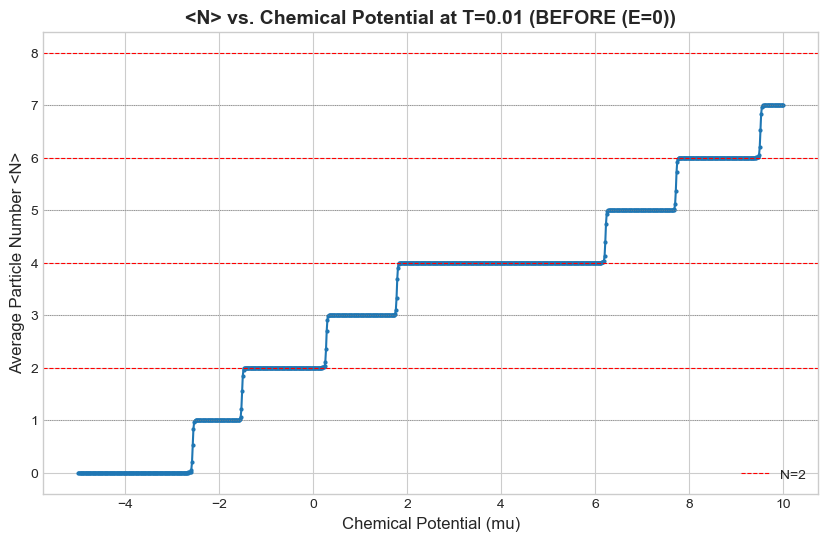


--- Enter STATIC Electric Field for 'AFTER' Analysis ---

 R U N N I N G   C H E M I C A L   P O T E N T I A L   S C A N: AFTER (E!=0)
 Analysis Temperature T = 0.01

Enter the range of chemical potentials (mu) to scan:

Scanning... please wait.
Scan completed in 18.34 seconds.


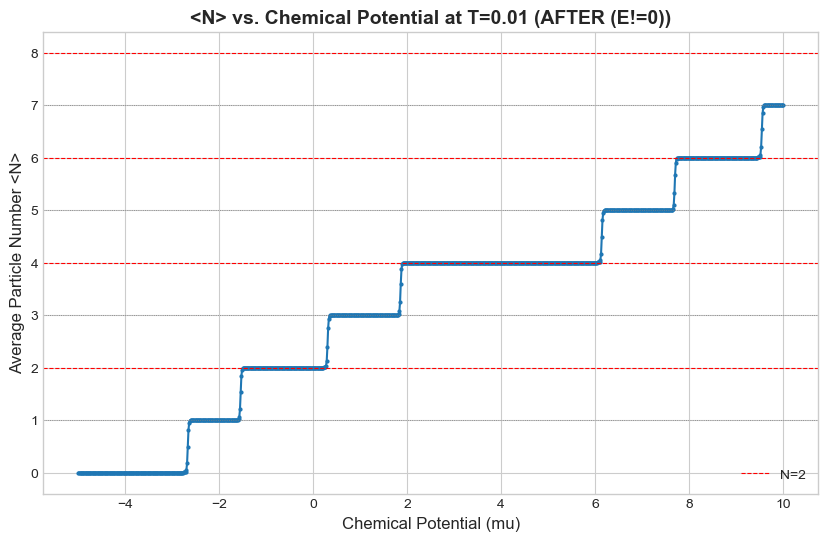


Done.


In [ ]:
# Max Orbital = 3 - Done
# How to pertube this Hamiltonian for specific targeted state ? - Done
# Green function method for including the temperature dependence - Implemented via Grand Canonical Ensemble

'''
This code is for 3D Hubbard Model analysis in thermal equilibrium.

1.  Uses the Grand Canonical Ensemble (K = H - mu*N) to study the system
    at a user-defined temperature (T).
2.  Scans a range of chemical potentials (mu) and calculates the average
    particle number <N> for each mu.
3.  Generates a plot of <N> vs. mu, allowing for the visual determination of
    the chemical potential required for any particle filling and revealing
    physical phenomena like Mott plateaus.
4.  Performs a full "BEFORE" (E=0) and "AFTER" (E!=0) analysis to show
    the effect of a STATIC electric field on the system's thermodynamics.
    
    <N> VS Mu Plot
'''
import os
import sys
import time
import math
import gc
import numpy as np
from numpy import linalg as LA
import matplotlib.pyplot as plt

# ----------------------------------------------------------------------
# Bit‐position helper
# ----------------------------------------------------------------------
def bitpos(site, orb, spin, n_orb):
    """Return bit position of (site, orbital, spin)."""
    return 2 * (site * n_orb + orb) + spin

# ----------------------------------------------------------------------
# Geometry and Coordinate definitions
# ----------------------------------------------------------------------
GEOMETRIES = {
    1: {"name":"Tetrahedron (4 sites)", "n_sites":4, "edges":[(0,1,"base"),(1,2,"base"),(2,0,"base"),(0,3,"vert"),(1,3,"vert"),(2,3,"vert")], "coords":np.array([[1,1,1],[1,-1,-1],[-1,1,-1],[-1,-1,1]])/np.sqrt(3)},
    2: {"name":"Square Pyramid (5 sites)", "n_sites":5, "edges":[(0,1,"base"),(1,2,"base"),(2,3,"base"),(3,0,"base"),(0,4,"vert"),(1,4,"vert"),(2,4,"vert"),(3,4,"vert")], "coords":np.array([[1,1,0],[-1,1,0],[-1,-1,0],[1,-1,0],[0,0,1]])},
    3: {"name":"Square Bipyramid (6 sites)", "n_sites":6, "edges":[(0,1,"base"),(1,2,"base"),(2,3,"base"),(3,0,"base"),(0,4,"vert"),(1,4,"vert"),(2,4,"vert"),(3,4,"vert"),(0,5,"vert"),(1,5,"vert"),(2,5,"vert"),(3,5,"vert")], "coords":np.array([[1,0,0],[-1,0,0],[0,1,0],[0,-1,0],[0,0,1],[0,0,-1]])}
}

# ----------------------------------------------------------------------
# Build the Hamiltonian matrix
# ----------------------------------------------------------------------
def popcount(n):
    """Counts the number of set bits (1s)."""
    return bin(n).count('1')

def build_grand_canonical_hamiltonian(params, E_field_vector, chemical_potential):
    """Builds the Grand Canonical Hamiltonian matrix K = H - mu*N."""
    n_sites, n_orb, w_orb, t_base, t_vert, U, edges, site_coords = params
    dim = 4 ** (n_sites * n_orb)
    K = np.zeros((dim, dim), dtype=np.float64)
    
    def hop_amplitude(edge_type): return t_base if edge_type == "base" else t_vert

    for state in range(dim):
        diag_energy = 0.0
        # Coulomb Term
        for s in range(n_sites):
            for o in range(n_orb):
                b_down,b_up=bitpos(s,o,0,n_orb),bitpos(s,o,1,n_orb)
                if ((state >> b_down) & 1) and ((state >> b_up) & 1): diag_energy += U
        
        # E-Field Term
        if np.linalg.norm(E_field_vector) > 1e-12:
            for s in range(n_sites):
                num_e = sum(1 for o in range(n_orb) for spin in (0,1) if (state>>bitpos(s,o,spin,n_orb))&1)
                diag_energy += num_e * np.dot(E_field_vector, site_coords[s])

        # Chemical Potential Term
        diag_energy -= chemical_potential * popcount(state)
        K[state, state] = diag_energy

        # Hopping Term
        for (i, j, e_type) in edges:
            t_hop = hop_amplitude(e_type)
            for o in range(n_orb):
                w = w_orb[o]
                for spin in (0, 1):
                    bi, bj = bitpos(i,o,spin,n_orb), bitpos(j,o,spin,n_orb)
                    if ((state >> bi) & 1) and not ((state >> bj) & 1):
                        new_state = state ^ (1 << bi) ^ (1 << bj)
                        if state < new_state: K[state, new_state] += -w * t_hop
    
    return K + K.T - np.diag(np.diag(K))

# ----------------------------------------------------------------------
# Thermal Analysis Functions
# ----------------------------------------------------------------------
def run_mu_scan(title, params, E_field, T):
    """
    Scans a range of chemical potentials, calculates <N>_T for each, and plots the result.
    """
    print("\n" + "="*80)
    print(f" R U N N I N G   C H E M I C A L   P O T E N T I A L   S C A N: {title.upper()}")
    print(f" Analysis Temperature T = {T}")
    print("="*80)

    n_sites, n_orb, _, _, _, _, _, _ = params
    dim = 4 ** (n_sites * n_orb)
    popcounts = np.array([popcount(i) for i in range(dim)])

    # Get scan range from user
    print("\nEnter the range of chemical potentials (mu) to scan:")
    mu_min = float(input("  > Mu_min (e.g., -10.0): ").strip())
    mu_max = float(input("  > Mu_max (e.g., 10.0): ").strip())
    num_steps = int(input("  > Number of mu steps (e.g., 200): ").strip())
    
    mus = np.linspace(mu_min, mu_max, num_steps)
    avg_Ns = []
    
    print("\nScanning... please wait.")
    start_time = time.time()

    # Pre-calculate the static Hamiltonian H(E) to avoid rebuilding it in the loop
    H_static = build_grand_canonical_hamiltonian(params, E_field, 0.0)

    for mu in mus:
        # Construct K = H - mu*N
        K = H_static - mu * np.diag(popcounts)
        evals, evecs = LA.eigh(K) # MUST get eigenvectors here

        # --- BUG FIX STARTS HERE ---
        # 1. Calculate the expectation value of N for EACH eigenstate of K
        # <N>_k = <psi_k | N | psi_k>
        N_k = np.einsum('jk,j->k', np.abs(evecs)**2, popcounts)
        
        # 2. Calculate the thermal weights using the eigenvalues of K
        min_E = evals[0]
        if T > 1e-6: # Finite temperature
            weights = np.exp(-(evals - min_E) / T)
        else: # T=0 limit
            weights = np.zeros_like(evals)
            ground_energy = evals[0]
            degenerate_indices = np.where(np.abs(evals - ground_energy) < 1e-9)[0]
            weights[degenerate_indices] = 1.0

        # 3. Calculate the thermal average <N>_T = (1/Z) * sum_k <N>_k * weight_k
        Z = np.sum(weights)
        N_avg = np.sum(weights * N_k) / Z if Z > 0 else 0
        # --- BUG FIX ENDS HERE ---
        
        avg_Ns.append(N_avg)
    
    end_time = time.time()
    print(f"Scan completed in {end_time - start_time:.2f} seconds.")

    # Plotting the results
    plt.style.use('seaborn-v0_8-whitegrid')
    fig, ax = plt.subplots(figsize=(10, 6))
    ax.plot(mus, avg_Ns, marker='.', linestyle='-', markersize=4)
    ax.set_xlabel('Chemical Potential (mu)', fontsize=12)
    ax.set_ylabel('Average Particle Number <N>', fontsize=12)
    ax.set_title(f'<N> vs. Chemical Potential at T={T} ({title})', fontsize=14, fontweight='bold')
    ax.grid(True)
    
    # Add horizontal lines for integer fillings
    max_N = 2 * n_sites * n_orb
    for n in range(1, max_N + 1):
        if n % 2 == 0: # Highlight even (paired) fillings
            ax.axhline(y=n, color='r', linestyle='--', linewidth=0.8, label=f'N={n}' if n==2 else "")
        else:
            ax.axhline(y=n, color='gray', linestyle=':', linewidth=0.6)
            
    ax.legend()
    plt.show()

# ----------------------------------------------------------------------
# Main driver
# ----------------------------------------------------------------------
def main():
    # --- 1) Setup System ---
    print("Choose cluster geometry:")
    for key, value in GEOMETRIES.items(): print(f"  {key}. {value['name']}")
    choice = int(input("Enter choice: ").strip())
    geom = GEOMETRIES[choice]
    n_sites, edges, site_coords = geom["n_sites"], geom["edges"], geom["coords"]

    print(f"\nYou selected: {geom['name']}")
    M = int(input("Enter number of orbitals per site (M >= 1): ").strip())
    w_orb = [float(input(f"  Enter orbital weight w_{o} = ").strip()) for o in range(M)]
    t_base = float(input("Enter base-edge hopping t_base = ").strip())
    t_vert = float(input("Enter vertical-edge hopping t_vert = ").strip())
    U = float(input("Enter on-site Coulomb repulsion U = ").strip())
    system_params = (n_sites, M, w_orb, t_base, t_vert, U, edges, site_coords)

    # --- 2) Setup Analysis Temperature ---
    print("\n--- Setup Analysis Parameters ---")
    T = float(input("Enter temperature T for analysis: ").strip())

    # --- 3) Run "BEFORE" Analysis ---
    run_mu_scan("BEFORE (E=0)", system_params, np.zeros(3), T)

    # --- 4) Run "AFTER" Analysis ---
    print("\n--- Enter STATIC Electric Field for 'AFTER' Analysis ---")
    Ex = float(input("Enter static Ex component: ").strip())
    Ey = float(input("Enter static Ey component: ").strip())
    Ez = float(input("Enter static Ez component: ").strip())
    static_E_field = np.array([Ex, Ey, Ez])
    
    run_mu_scan("AFTER (E!=0)", system_params, static_E_field, T)

    print("\nDone.")

if __name__ == "__main__":
    main()


Starting SCF for U=0.10, T=0.05, |E|=0.00, w=15.00 -> t_eff=1.0000
SCF converged in 1 iterations. n_up=0.5000, n_down=0.5000
Starting SCF for U=0.30, T=0.05, |E|=0.00, w=15.00 -> t_eff=1.0000
SCF converged in 1 iterations. n_up=0.5000, n_down=0.5000
Starting SCF for U=0.50, T=0.05, |E|=0.00, w=15.00 -> t_eff=1.0000
SCF converged in 1 iterations. n_up=0.5000, n_down=0.5000
Starting SCF for U=0.71, T=0.05, |E|=0.00, w=15.00 -> t_eff=1.0000
SCF converged in 1 iterations. n_up=0.5000, n_down=0.5000
Starting SCF for U=0.91, T=0.05, |E|=0.00, w=15.00 -> t_eff=1.0000
SCF converged in 1 iterations. n_up=0.5000, n_down=0.5000
Starting SCF for U=1.11, T=0.05, |E|=0.00, w=15.00 -> t_eff=1.0000
SCF converged in 1 iterations. n_up=0.5000, n_down=0.5000
Starting SCF for U=1.31, T=0.05, |E|=0.00, w=15.00 -> t_eff=1.0000
SCF converged in 1 iterations. n_up=0.5000, n_down=0.5000
Starting SCF for U=1.51, T=0.05, |E|=0.00, w=15.00 -> t_eff=1.0000
SCF converged in 1 iterations. n_up=0.5000, n_down=0.5000


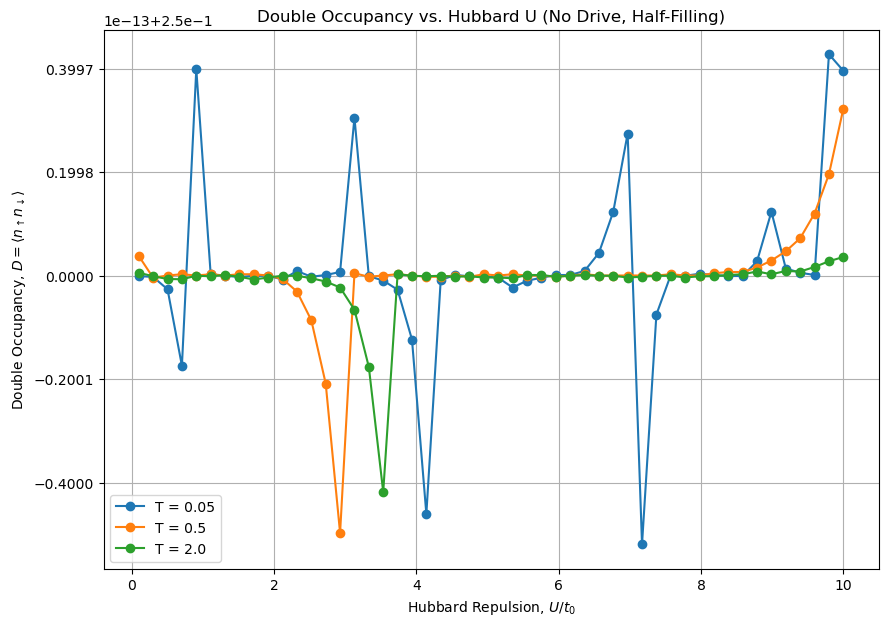

Starting SCF for U=5.00, T=0.10, |E|=0.00, w=20.00 -> t_eff=1.0000
SCF converged in 1 iterations. n_up=0.5000, n_down=0.5000
Starting SCF for U=5.00, T=0.10, |E|=0.61, w=20.00 -> t_eff=0.9999
SCF converged in 1 iterations. n_up=0.5000, n_down=0.5000
Starting SCF for U=5.00, T=0.10, |E|=1.22, w=20.00 -> t_eff=0.9997
SCF converged in 1 iterations. n_up=0.5000, n_down=0.5000
Starting SCF for U=5.00, T=0.10, |E|=1.84, w=20.00 -> t_eff=0.9993
SCF converged in 1 iterations. n_up=0.5000, n_down=0.5000
Starting SCF for U=5.00, T=0.10, |E|=2.45, w=20.00 -> t_eff=0.9988
SCF converged in 1 iterations. n_up=0.5000, n_down=0.5000
Starting SCF for U=5.00, T=0.10, |E|=3.06, w=20.00 -> t_eff=0.9980
SCF converged in 1 iterations. n_up=0.5000, n_down=0.5000
Starting SCF for U=5.00, T=0.10, |E|=3.67, w=20.00 -> t_eff=0.9972
SCF converged in 1 iterations. n_up=0.5000, n_down=0.5000
Starting SCF for U=5.00, T=0.10, |E|=4.29, w=20.00 -> t_eff=0.9962
SCF converged in 1 iterations. n_up=0.5000, n_down=0.5000


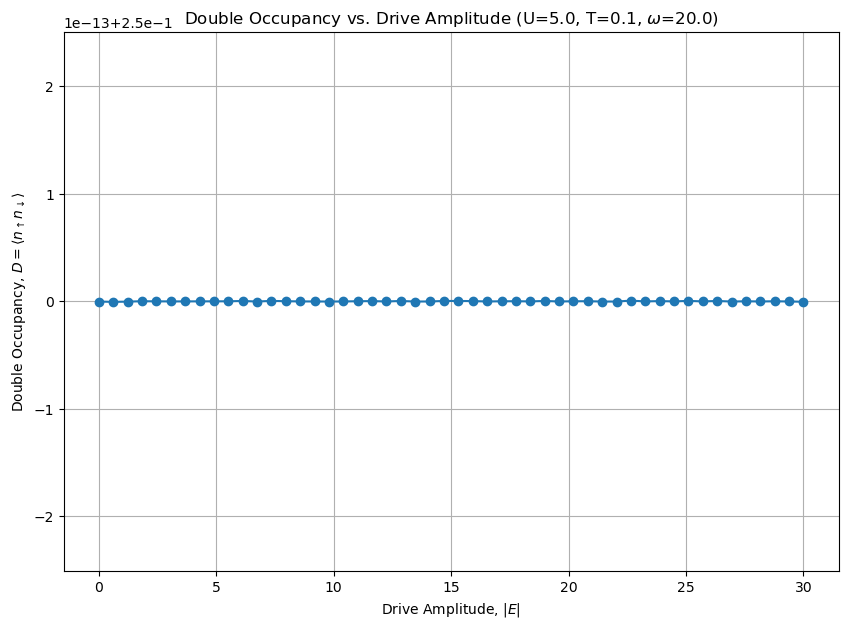

In [ ]:
import numpy as np
import matplotlib.pyplot as plt
from scipy.integrate import quad
from scipy.optimize import brentq
from scipy.special import j0 

# --- Constants ---
HBAR = 1.0      # Planck's constant / 2pi
E_CHARGE = -1.0 # Electron charge (in units where e=1)
KB = 1.0        # Boltzmann constant (in units where kB=1)

class SimulationParameters:
    """
    A container class for all simulation parameters to keep the code organized.
    """
    def __init__(self, L=10, t0=1.0, U=4.0, T=0.1, n_target=1.0,
                 E_vec=np.array([1.0, 1.0, 0.0]), omega=15.0,
                 scf_tol=1e-6, max_scf_iter=100, mixing_alpha=0.1):
        # Lattice and Model Parameters
        self.L = L          # System size (L x L x L) - not used in this DOS approach
        self.t0 = t0        # Bare hopping integral
        self.U = U          # On-site Hubbard repulsion
        self.T = T          # Temperature
        self.beta = 1.0 / (KB * T) if T > 1e-9 else np.inf
        self.n_target = n_target # Target electron filling (1.0 for half-filling)

        # Drive Parameters
        self.E_vec = np.array(E_vec, dtype=float) # Electric field vector [Ex, Ey, Ez]
        self.E_amp = np.linalg.norm(self.E_vec)
        self.omega = omega  # Drive frequency

        # SCF Solver Parameters
        self.scf_tol = scf_tol
        self.max_scf_iter = max_scf_iter
        self.mixing_alpha = mixing_alpha

def get_dos_3d_cubic(energy, t_eff):
    """
    Calculates the density of states (DOS) for a 3D simple cubic lattice
    using a standard semi-elliptic approximation.
    The bandwidth of the 3D cubic lattice is 12*t_eff.
    The DOS for each spin channel should integrate to 1.
    """
    W = 6 * t_eff # Half-bandwidth
    if np.abs(energy) >= W: # Use >= to avoid issues at the boundary
        return 0.0
    # CORRECTION: The normalization factor for a semi-elliptic DOS is 2/(pi*W^2).
    # The integral of sqrt(W^2 - E^2) from -W to W is pi*W^2/2.
    return (2.0 / (np.pi * W**2)) * np.sqrt(W**2 - energy**2)

def get_effective_hopping(params):
    """
    Calculates the effective hopping parameter t_eff under a high-frequency drive.
    This uses the leading order of the Floquet-Magnus expansion, which renormalizes
    the hopping based on the drive parameters.
    The time-averaged effect on hopping is given by t_eff = t0 * J0(K), where J0 is the
    0th Bessel function and K = |q * E_vec . (R_i - R_j) / (hbar * omega)|.
    """
    if params.E_amp < 1e-9 or params.omega < 1e-9:
        return params.t0

   
    
  
    K_x = np.abs(E_CHARGE * params.E_vec[0] * 1.0 / (HBAR * params.omega))
    K_y = np.abs(E_CHARGE * params.E_vec[1] * 1.0 / (HBAR * params.omega))
    K_z = np.abs(E_CHARGE * params.E_vec[2] * 1.0 / (HBAR * params.omega))

    # CORRECTION: The effective hopping is renormalized by the standard Bessel function j0, not i0.
    # j0(x) shows the characteristic decay and oscillation (dynamic localization).
    t_eff_x = params.t0 * j0(K_x)
    t_eff_y = params.t0 * j0(K_y)
    t_eff_z = params.t0 * j0(K_z)

    # Average effective hopping for this isotropic DOS model.
    
    t_eff = (t_eff_x + t_eff_y + t_eff_z) / 3.0
    return t_eff

def calculate_occupations(mu, t_eff, U, n_up_old, n_down_old, beta):
    """
    Calculates the new occupations for a given chemical potential mu.
    This function integrates the Fermi-Dirac distribution multiplied by the DOS.
    """
    W = 6 * t_eff # Half-bandwidth

    # Integrand for n_up
    def integrand_up(energy):
        E_k_up = energy + U * n_down_old
        fermi_factor = 1.0 / (1.0 + np.exp(beta * (E_k_up - mu)))
        return get_dos_3d_cubic(energy, t_eff) * fermi_factor

    # Integrand for n_down
    def integrand_down(energy):
        E_k_down = energy + U * n_up_old
        fermi_factor = 1.0 / (1.0 + np.exp(beta * (E_k_down - mu)))
        return get_dos_3d_cubic(energy, t_eff) * fermi_factor

    # quad can sometimes be slow; for production, one might use a grid-based integration.
    n_up_new, _ = quad(integrand_up, -W, W, epsabs=1e-7, limit=100)
    n_down_new, _ = quad(integrand_down, -W, W, epsabs=1e-7, limit=100)

    return n_up_new, n_down_new

def solve_scf_loop(params):
    """
    Executes the main self-consistent field loop to find the mean-field solution.
    """
    t_eff = get_effective_hopping(params)
    if t_eff <= 0: # If hopping collapses, system is trivial
        print(f"Hopping t_eff = {t_eff:.4f} collapsed. System is fully localized.")
        # At half-filling with no hopping, n_up=0.5, n_down=0.5, D=0.25 (for U=0)
        # For U>0, magnetism can occur, but here we can return a simple state.
        # This part depends on the physics you expect. Returning NaN is safer.
        return np.nan, np.nan, np.nan

    W = 6 * t_eff # Half-bandwidth

    n_up = params.n_target / 2.0
    n_down = params.n_target / 2.0

    print(f"Starting SCF for U={params.U:.2f}, T={params.T:.2f}, |E|={params.E_amp:.2f}, "
          f"w={params.omega:.2f} -> t_eff={t_eff:.4f}")

    for i in range(params.max_scf_iter):
        def density_error(mu):
            n_up_new, n_down_new = calculate_occupations(mu, t_eff, params.U, n_up, n_down, params.beta)
            return n_up_new + n_down_new - params.n_target

        mu_min = -W - params.U
        mu_max = W + params.U
        try:
            mu = brentq(density_error, mu_min, mu_max)
        except ValueError:
            print("Warning: Chemical potential root finding failed. Check search interval or parameters.")
            return np.nan, np.nan, np.nan

        n_up_new, n_down_new = calculate_occupations(mu, t_eff, params.U, n_up, n_down, params.beta)

        diff = max(abs(n_up_new - n_up), abs(n_down_new - n_down))
        if diff < params.scf_tol:
            print(f"SCF converged in {i+1} iterations. n_up={n_up_new:.4f}, n_down={n_down_new:.4f}")
            return n_up_new, n_down_new, mu

        n_up = (1 - params.mixing_alpha) * n_up + params.mixing_alpha * n_up_new
        n_down = (1 - params.mixing_alpha) * n_down + params.mixing_alpha * n_down_new

    print("Warning: SCF did not converge within max iterations.")
    return np.nan, np.nan, np.nan

def calculate_double_occupancy(n_up, n_down):
    """
    Calculates the double occupancy in the mean-field approximation.
    D = <n_i,up * n_i,down> approx <n_i,up> * <n_i,down>
    """
    if np.isnan(n_up) or np.isnan(n_down):
        return np.nan
    return n_up * n_down

def main():
    """
    Main driver for the simulation. Sets up parameter sweeps and generates plots.
    """
    # --- Parameter Sweep 1: D vs U at different Temperatures ---
    U_values = np.linspace(0.1, 10.0, 50)
    T_values = [0.05, 0.5, 2.0]
    
    fixed_E_vec = np.array([0.0, 0.0, 0.0]) # No drive
    fixed_omega = 15.0

    plt.figure(figsize=(10, 7))
    
    for T in T_values:
        # SYNTAX CORRECTION: Initialize the list to store results
        double_occupancies = []
        for U in U_values:
            params = SimulationParameters(U=U, T=T, E_vec=fixed_E_vec, omega=fixed_omega)
            n_up, n_down, _ = solve_scf_loop(params)
            D = calculate_double_occupancy(n_up, n_down)
            double_occupancies.append(D)
        
        plt.plot(U_values, double_occupancies, 'o-', label=f'T = {T}')

    plt.title('Double Occupancy vs. Hubbard U (No Drive, Half-Filling)')
    plt.xlabel('Hubbard Repulsion, $U/t_0$')
    plt.ylabel('Double Occupancy, $D = \\langle n_{\\uparrow} n_{\\downarrow} \\rangle$')
    plt.grid(True)
    plt.legend()
    plt.savefig('D_vs_U.png')
    plt.show()

    # --- Parameter Sweep 2: D vs Drive Amplitude at fixed U, T ---
    E_amp_values = np.linspace(0.0, 30.0, 50)
    fixed_U = 5.0
    fixed_T = 0.1
    fixed_omega = 20.0 # High frequency drive
    
    # SYNTAX CORRECTION: Initialize the list to store results
    double_occupancies_drive = []
    for E_amp in E_amp_values:
        # Drive along the (1,1,0) direction
        E_vec = E_amp * np.array([1.0, 1.0, 0.0]) / np.sqrt(2.0)
        params = SimulationParameters(U=fixed_U, T=fixed_T, E_vec=E_vec, omega=fixed_omega)
        n_up, n_down, _ = solve_scf_loop(params)
        D = calculate_double_occupancy(n_up, n_down)
        double_occupancies_drive.append(D)

    plt.figure(figsize=(10, 7))
    plt.plot(E_amp_values, double_occupancies_drive, 'o-')
    plt.title(f'Double Occupancy vs. Drive Amplitude (U={fixed_U}, T={fixed_T}, $\\omega$={fixed_omega})')
    plt.xlabel('Drive Amplitude, $|E|$')
    plt.ylabel('Double Occupancy, $D = \\langle n_{\\uparrow} n_{\\downarrow} \\rangle$')
    plt.grid(True)
    plt.savefig('D_vs_Drive.png')
    plt.show()

if __name__ == '__main__':
    main()

======== Advanced Hubbard Model Analyzer =========

1. Choose the lattice geometry:
   1. Cubic (Infinite Lattice via Mean-Field Theory)
   2. Tetrahedron (4-site cluster via Exact Diagonalization)
   3. Octahedron (6-site cluster via Exact Diagonalization)

2. Set baseline parameters for the simulation:
   Note: Half-filling for Tetrahedron means 4 electrons.
   Enter Electric Field Vector (for drive/perturbation):
   Note: For ED, omega is not used; the E-field is a static potential.

3. Choose an analysis plot to generate:
--- 1D Plots ---
   1. Double Occupancy vs. Hubbard U
   2. Double Occupancy vs. Temperature
   3. Double Occupancy vs. E-Field Amplitude
--- 2D Heatmaps ---
   5. D vs. (U, T)
   6. D vs. (|E|, omega)

   0. Exit

Generating 1D plot: D vs U...
ED Solver for Tetrahedron with 4 electrons.
Hilbert space dimension = 70
  U=0.100, D=1.07440
ED Solver for Tetrahedron with 4 electrons.
Hilbert space dimension = 70
  U=0.354, D=1.05183
ED Solver for Tetrahedron with 4 el

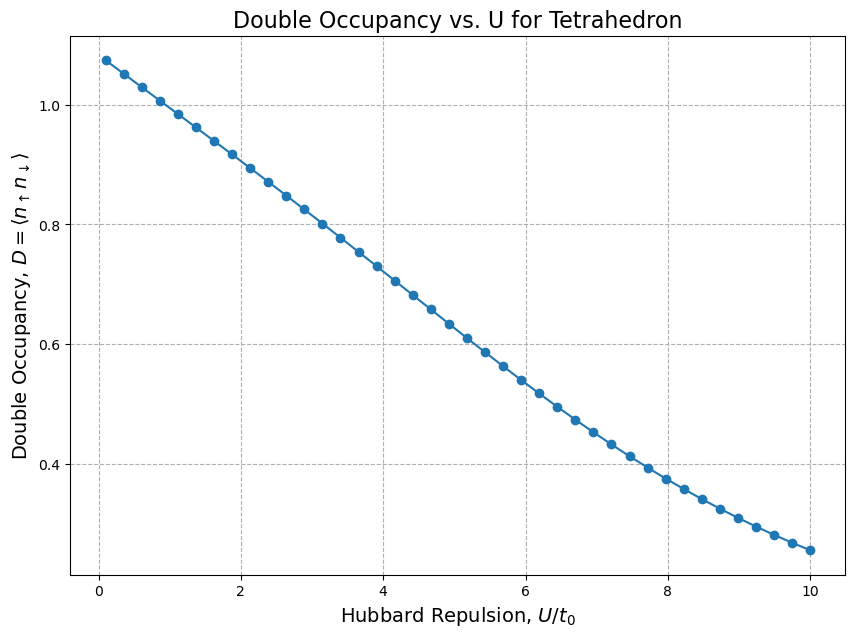


3. Choose an analysis plot to generate:
--- 1D Plots ---
   1. Double Occupancy vs. Hubbard U
   2. Double Occupancy vs. Temperature
   3. Double Occupancy vs. E-Field Amplitude
--- 2D Heatmaps ---
   5. D vs. (U, T)
   6. D vs. (|E|, omega)

   0. Exit

Generating 1D plot: D vs T...
ED Solver for Tetrahedron with 4 electrons.
Hilbert space dimension = 70
  T=0.010, D=0.72149
ED Solver for Tetrahedron with 4 electrons.
Hilbert space dimension = 70
  T=0.012, D=0.72149
ED Solver for Tetrahedron with 4 electrons.
Hilbert space dimension = 70
  T=0.014, D=0.72149
ED Solver for Tetrahedron with 4 electrons.
Hilbert space dimension = 70
  T=0.017, D=0.72149
ED Solver for Tetrahedron with 4 electrons.
Hilbert space dimension = 70
  T=0.020, D=0.72149
ED Solver for Tetrahedron with 4 electrons.
Hilbert space dimension = 70
  T=0.024, D=0.72149
ED Solver for Tetrahedron with 4 electrons.
Hilbert space dimension = 70
  T=0.029, D=0.72149
ED Solver for Tetrahedron with 4 electrons.
Hilbert spac

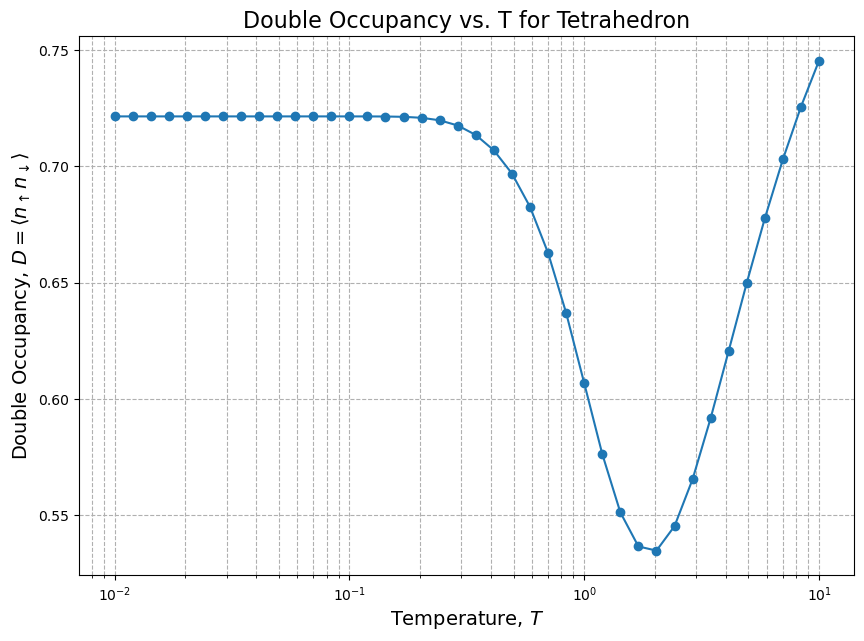


3. Choose an analysis plot to generate:
--- 1D Plots ---
   1. Double Occupancy vs. Hubbard U
   2. Double Occupancy vs. Temperature
   3. Double Occupancy vs. E-Field Amplitude
--- 2D Heatmaps ---
   5. D vs. (U, T)
   6. D vs. (|E|, omega)

   0. Exit

Generating 1D plot: D vs E_amp...
ED Solver for Tetrahedron with 4 electrons.
Hilbert space dimension = 70
  E_amp=0.000, D=0.65523
ED Solver for Tetrahedron with 4 electrons.
Hilbert space dimension = 70
  E_amp=0.513, D=0.66132
ED Solver for Tetrahedron with 4 electrons.
Hilbert space dimension = 70
  E_amp=1.026, D=0.67930
ED Solver for Tetrahedron with 4 electrons.
Hilbert space dimension = 70
  E_amp=1.538, D=0.70814
ED Solver for Tetrahedron with 4 electrons.
Hilbert space dimension = 70
  E_amp=2.051, D=0.74590
ED Solver for Tetrahedron with 4 electrons.
Hilbert space dimension = 70
  E_amp=2.564, D=0.78961
ED Solver for Tetrahedron with 4 electrons.
Hilbert space dimension = 70
  E_amp=3.077, D=0.83567
ED Solver for Tetrahedro

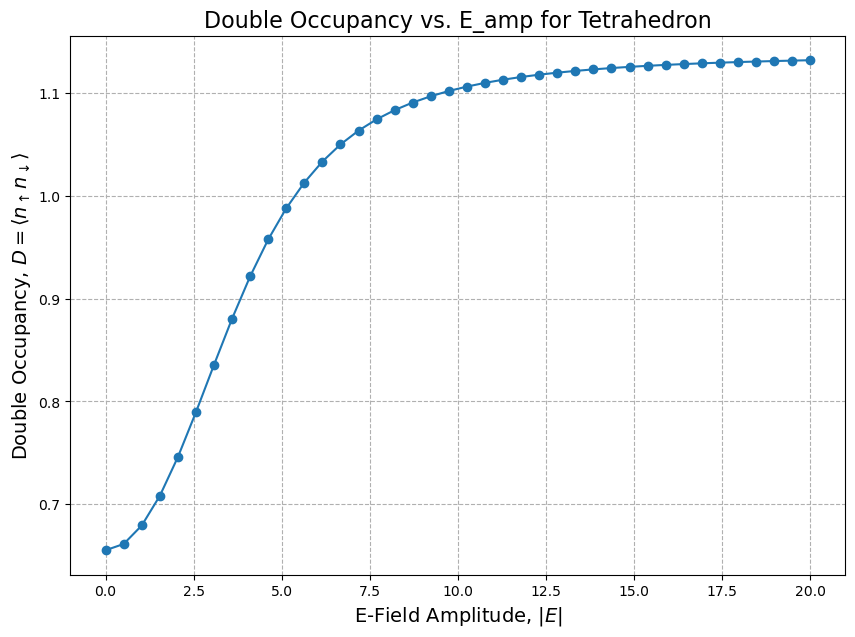


3. Choose an analysis plot to generate:
--- 1D Plots ---
   1. Double Occupancy vs. Hubbard U
   2. Double Occupancy vs. Temperature
   3. Double Occupancy vs. E-Field Amplitude
--- 2D Heatmaps ---
   5. D vs. (U, T)
   6. D vs. (|E|, omega)

   0. Exit

Generating 2D Heatmap: D vs (U, T)...
ED Solver for Tetrahedron with 4 electrons.
Hilbert space dimension = 70
  U=0.10, T=0.01, D=nan
ED Solver for Tetrahedron with 4 electrons.
Hilbert space dimension = 70
  U=0.62, T=0.01, D=nan
ED Solver for Tetrahedron with 4 electrons.
Hilbert space dimension = 70
  U=1.14, T=0.01, D=nan
ED Solver for Tetrahedron with 4 electrons.
Hilbert space dimension = 70
  U=1.66, T=0.01, D=0.93600
ED Solver for Tetrahedron with 4 electrons.
Hilbert space dimension = 70
  U=2.18, T=0.01, D=0.88942
ED Solver for Tetrahedron with 4 electrons.
Hilbert space dimension = 70
  U=2.71, T=0.01, D=0.84215
ED Solver for Tetrahedron with 4 electrons.
Hilbert space dimension = 70
  U=3.23, T=0.01, D=0.79410
ED Solver f

/var/folders/84/c1f888hj3nl61gx1s2sy_krc0000gn/T/ipykernel_11055/2656111814.py:141: RuntimeWarning: overflow encountered in exp
  boltzmann_factors = np.exp(-self.params.beta * eigenvalues)
/var/folders/84/c1f888hj3nl61gx1s2sy_krc0000gn/T/ipykernel_11055/2656111814.py:150: RuntimeWarning: invalid value encountered in scalar divide
  thermal_avg_d = np.sum(d_expect_per_state * boltzmann_factors) / partition_func


  U=7.39, T=0.01, D=0.41789
ED Solver for Tetrahedron with 4 electrons.
Hilbert space dimension = 70
  U=7.92, T=0.01, D=0.37933
ED Solver for Tetrahedron with 4 electrons.
Hilbert space dimension = 70
  U=8.44, T=0.01, D=0.34388
ED Solver for Tetrahedron with 4 electrons.
Hilbert space dimension = 70
  U=8.96, T=0.01, D=0.31157
ED Solver for Tetrahedron with 4 electrons.
Hilbert space dimension = 70
  U=9.48, T=0.01, D=0.28233
ED Solver for Tetrahedron with 4 electrons.
Hilbert space dimension = 70
  U=10.00, T=0.01, D=0.25602
ED Solver for Tetrahedron with 4 electrons.
Hilbert space dimension = 70
  U=0.10, T=0.01, D=1.07440
ED Solver for Tetrahedron with 4 electrons.
Hilbert space dimension = 70
  U=0.62, T=0.01, D=1.02816
ED Solver for Tetrahedron with 4 electrons.
Hilbert space dimension = 70
  U=1.14, T=0.01, D=0.98215
ED Solver for Tetrahedron with 4 electrons.
Hilbert space dimension = 70
  U=1.66, T=0.01, D=0.93600
ED Solver for Tetrahedron with 4 electrons.
Hilbert space dime

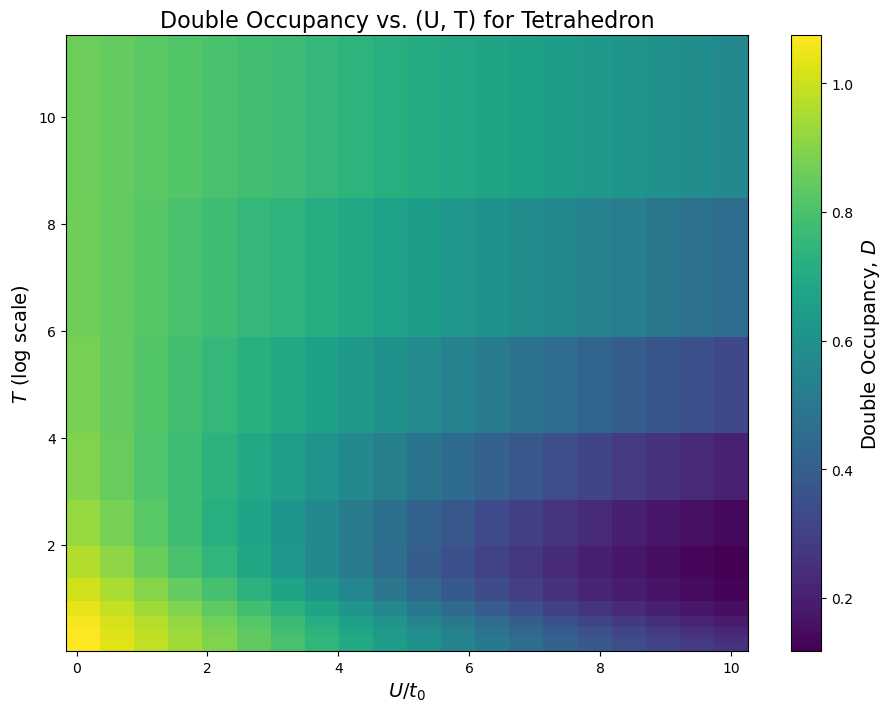


3. Choose an analysis plot to generate:
--- 1D Plots ---
   1. Double Occupancy vs. Hubbard U
   2. Double Occupancy vs. Temperature
   3. Double Occupancy vs. E-Field Amplitude
--- 2D Heatmaps ---
   5. D vs. (U, T)
   6. D vs. (|E|, omega)

   0. Exit

Generating 2D Heatmap: D vs (E_amp, omega)...
ED Solver for Tetrahedron with 4 electrons.
Hilbert space dimension = 70
  E_amp=0.00, omega=1.00, D=0.65523
ED Solver for Tetrahedron with 4 electrons.
Hilbert space dimension = 70
  E_amp=1.05, omega=1.00, D=0.68055
ED Solver for Tetrahedron with 4 electrons.
Hilbert space dimension = 70
  E_amp=2.11, omega=1.00, D=0.75028
ED Solver for Tetrahedron with 4 electrons.
Hilbert space dimension = 70
  E_amp=3.16, omega=1.00, D=0.84292
ED Solver for Tetrahedron with 4 electrons.
Hilbert space dimension = 70
  E_amp=4.21, omega=1.00, D=0.92976
ED Solver for Tetrahedron with 4 electrons.
Hilbert space dimension = 70
  E_amp=5.26, omega=1.00, D=0.99507
ED Solver for Tetrahedron with 4 electrons.


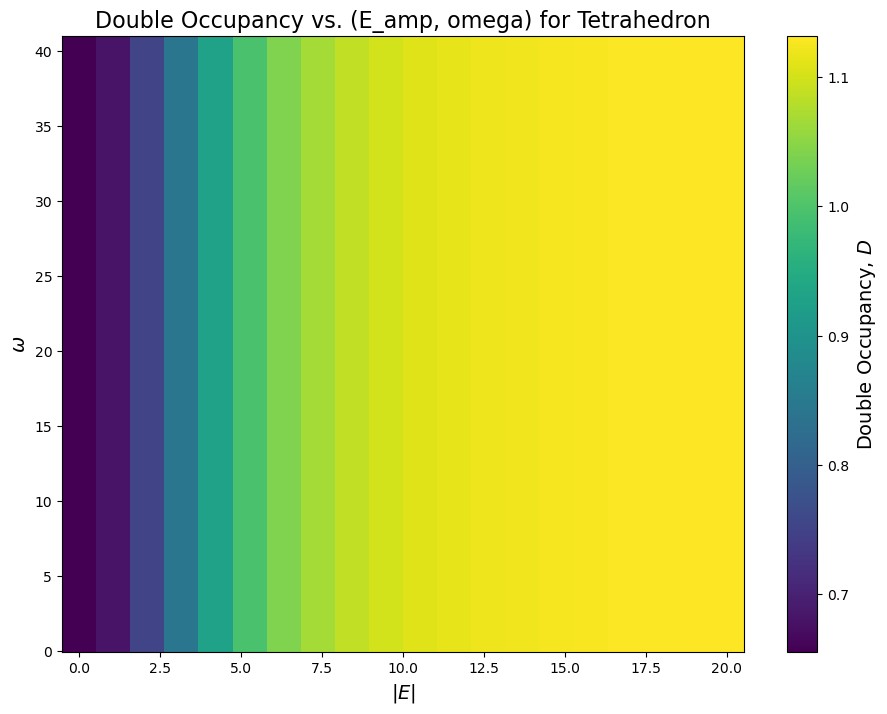


3. Choose an analysis plot to generate:
--- 1D Plots ---
   1. Double Occupancy vs. Hubbard U
   2. Double Occupancy vs. Temperature
   3. Double Occupancy vs. E-Field Amplitude
--- 2D Heatmaps ---
   5. D vs. (U, T)
   6. D vs. (|E|, omega)

   0. Exit
Exiting analysis.


In [4]:
import numpy as np
import matplotlib.pyplot as plt
from scipy.integrate import quad
from scipy.optimize import brentq
from scipy.special import j0
from scipy.linalg import eigh
import itertools
import time
import os # Import the os module to handle file paths

# --- Constants ---
HBAR = 1.0
E_CHARGE = -1.0
KB = 1.0

# --- Geometry Definitions for Exact Diagonalization ---
GEOMETRIES = {
    "Tetrahedron": {
        "n_sites": 4,
        "coords": np.array([[1, 1, 1], [1, -1, -1], [-1, 1, -1], [-1, -1, 1]]) / np.sqrt(3.0),
        "edges": [(0, 1), (0, 2), (0, 3), (1, 2), (1, 3), (2, 3)],
        "max_electrons": 8,
    },
    "Octahedron": {
        "n_sites": 6,
        "coords": np.array([[1,0,0], [-1,0,0], [0,1,0], [0,-1,0], [0,0,1], [0,0,-1]]),
        "edges": [
            (0,2), (0,3), (0,4), (0,5), (1,2), (1,3), (1,4), (1,5),
            (2,4), (2,5), (3,4), (3,5)
        ],
        "max_electrons": 12,
    }
}

# --- Helper Functions ---
def bit_is_set(n, k):
    """Checks if the k-th bit of integer n is set."""
    return (n >> k) & 1

def bitpos(site, spin, n_sites):
    """Returns bit position for a given site and spin."""
    # spin 0 = down, spin 1 = up
    # Layout: s0_d, s0_u, s1_d, s1_u, ...
    return 2 * site + spin

class SimulationParameters:
    """Container for all simulation parameters."""
    def __init__(self, geometry_name="Cubic", t0=1.0, U=4.0, T=0.1,
                 n_target=1.0, E_vec=np.array([0.,0.,0.]), omega=15.0):
        self.geometry_name = geometry_name
        self.t0 = t0
        self.U = U
        self.T = T
        self.beta = 1.0 / (KB * T) if T > 1e-9 else np.inf
        self.n_target = n_target
        self.E_vec = np.array(E_vec, dtype=float)
        self.E_amp = np.linalg.norm(self.E_vec)
        self.omega = omega

# --- EXACT DIAGONALIZATION SOLVER ---
class ExactDiagonalizationSolver:
    """
    Solves the Hubbard model for small clusters using Exact Diagonalization.
    """
    def __init__(self, params):
        self.params = params
        self.geom_info = GEOMETRIES[params.geometry_name]
        self.n_sites = self.geom_info["n_sites"]
        self.site_coords = self.geom_info["coords"]
        self.edges = self.geom_info["edges"]
        self.n_target_electrons = int(self.params.n_target * self.n_sites)

        # Build the basis states (fixed particle number)
        self.basis_states = self._create_basis()
        self.dim = len(self.basis_states)
        self.basis_map = {state: i for i, state in enumerate(self.basis_states)}
        print(f"ED Solver for {self.params.geometry_name} with {self.n_target_electrons} electrons.")
        print(f"Hilbert space dimension = {self.dim}")

    def _create_basis(self):
        """Creates the list of Fock states with a fixed number of electrons."""
        num_bits = 2 * self.n_sites
        basis = [
            i for i in range(2**num_bits)
            if bin(i).count('1') == self.n_target_electrons
        ]
        return basis

    def _build_hamiltonian(self):
        """Builds the many-body Hamiltonian matrix in the specified basis."""
        H = np.zeros((self.dim, self.dim), dtype=np.float64)

        for i, state in enumerate(self.basis_states):
            # --- 1) Diagonal Terms ---
            diag_energy = 0.0
            # a) On-site Coulomb repulsion (U)
            for s in range(self.n_sites):
                b_down = bitpos(s, 0, self.n_sites)
                b_up = bitpos(s, 1, self.n_sites)
                if bit_is_set(state, b_down) and bit_is_set(state, b_up):
                    diag_energy += self.params.U

            # b) Static Electric field potential
            if self.params.E_amp > 1e-9:
                potential_energy = 0.0
                for s in range(self.n_sites):
                    num_electrons_at_site = 0
                    if bit_is_set(state, bitpos(s, 0, self.n_sites)): num_electrons_at_site += 1
                    if bit_is_set(state, bitpos(s, 1, self.n_sites)): num_electrons_at_site += 1
                    potential_energy += E_CHARGE * num_electrons_at_site * np.dot(self.params.E_vec, self.site_coords[s])
                diag_energy += potential_energy
            H[i, i] = diag_energy

            # --- 2) Off-diagonal hopping terms (t0) ---
            for s1, s2 in self.edges:
                for spin in (0, 1): # 0 for down, 1 for up
                    b1 = bitpos(s1, spin, self.n_sites)
                    b2 = bitpos(s2, spin, self.n_sites)
                    # Hop from s1 to s2
                    if bit_is_set(state, b1) and not bit_is_set(state, b2):
                        new_state = state ^ (1 << b1) | (1 << b2)
                        if new_state in self.basis_map:
                            j = self.basis_map[new_state]
                            H[i, j] -= self.params.t0
                    # Hop from s2 to s1
                    if bit_is_set(state, b2) and not bit_is_set(state, b1):
                        new_state = state ^ (1 << b2) | (1 << b1)
                        if new_state in self.basis_map:
                            j = self.basis_map[new_state]
                            H[i, j] -= self.params.t0
        return H

    def _calculate_thermal_avg_double_occupancy(self, eigenvalues, eigenvectors):
        """Calculates the thermal average of double occupancy."""
        if self.params.beta == np.inf: # Zero temperature
            ground_state_vector = eigenvectors[:, 0]
            d_op_values = self._get_d_operator_diagonal()
            return np.sum(d_op_values * np.abs(ground_state_vector)**2)

        # Finite temperature
        boltzmann_factors = np.exp(-self.params.beta * eigenvalues)
        partition_func = np.sum(boltzmann_factors)
        if partition_func < 1e-9: return 0.0

        d_op_values = self._get_d_operator_diagonal()
        # <D>_k = <psi_k| D_op |psi_k>
        d_expect_per_state = np.einsum('ij,i,ij->j', eigenvectors.conj(), d_op_values, eigenvectors)

        # Thermal average: <D> = (1/Z) * sum_k <D>_k * exp(-beta*E_k)
        thermal_avg_d = np.sum(d_expect_per_state * boltzmann_factors) / partition_func
        return thermal_avg_d

    def _get_d_operator_diagonal(self):
        """Gets the diagonal of the Double Occupancy operator in the basis."""
        d_op = np.zeros(self.dim)
        for i, state in enumerate(self.basis_states):
            double_occupancy_count = 0
            for s in range(self.n_sites):
                if bit_is_set(state, bitpos(s, 0, self.n_sites)) and \
                   bit_is_set(state, bitpos(s, 1, self.n_sites)):
                    double_occupancy_count += 1
            d_op[i] = double_occupancy_count
        return d_op

    def solve(self):
        """Main solve method for a single set of parameters."""
        H = self._build_hamiltonian()
        evals, evecs = eigh(H)
        return self._calculate_thermal_avg_double_occupancy(evals, evecs)

# --- MEAN-FIELD THEORY SOLVER ---
class MeanFieldSolver:
    """
    Solves the Hubbard model for a 3D cubic lattice using MFT.
    """
    def __init__(self, params):
        self.params = params
        self.scf_tol = 1e-6
        self.max_scf_iter = 100
        self.mixing_alpha = 0.1

    def _get_dos_3d_cubic(self, energy, t_eff):
        """Semi-elliptic density of states for a 3D simple cubic lattice."""
        W = 6 * t_eff
        if np.abs(energy) >= W: return 0.0
        return (2.0 / (np.pi * W**2)) * np.sqrt(W**2 - energy**2)

    def _get_effective_hopping(self):
        """Calculates effective hopping t_eff under a high-frequency drive."""
        p = self.params
        if p.E_amp < 1e-9 or p.omega < 1e-9: return p.t0
        K_x = np.abs(E_CHARGE * p.E_vec[0] * 1.0 / (HBAR * p.omega))
        K_y = np.abs(E_CHARGE * p.E_vec[1] * 1.0 / (HBAR * p.omega))
        K_z = np.abs(E_CHARGE * p.E_vec[2] * 1.0 / (HBAR * p.omega))
        t_eff_x = p.t0 * j0(K_x)
        t_eff_y = p.t0 * j0(K_y)
        t_eff_z = p.t0 * j0(K_z)
        return (t_eff_x + t_eff_y + t_eff_z) / 3.0

    def _calculate_occupations(self, mu, t_eff, n_up_old, n_down_old):
        """Integrates the DOS to find spin-up and spin-down occupations."""
        W = 6 * t_eff
        def integrand_up(e):
            E_k_up = e + self.params.U * n_down_old
            fermi = 1.0 / (1.0 + np.exp(self.params.beta * (E_k_up - mu)))
            return self._get_dos_3d_cubic(e, t_eff) * fermi
        def integrand_down(e):
            E_k_down = e + self.params.U * n_up_old
            fermi = 1.0 / (1.0 + np.exp(self.params.beta * (E_k_down - mu)))
            return self._get_dos_3d_cubic(e, t_eff) * fermi
        n_up, _ = quad(integrand_up, -W, W)
        n_down, _ = quad(integrand_down, -W, W)
        return n_up, n_down

    def solve(self):
        """Main SCF solve method."""
        t_eff = self._get_effective_hopping()
        if t_eff <= 0: return np.nan
        W = 6 * t_eff
        n_up = self.params.n_target / 2.0
        n_down = self.params.n_target / 2.0

        for _ in range(self.max_scf_iter):
            def density_error(mu):
                n_up_new, n_down_new = self._calculate_occupations(mu, t_eff, n_up, n_down)
                return n_up_new + n_down_new - self.params.n_target
            try:
                mu = brentq(density_error, -W - self.params.U, W + self.params.U)
            except ValueError: return np.nan
            n_up_new, n_down_new = self._calculate_occupations(mu, t_eff, n_up, n_down)
            if max(abs(n_up_new-n_up), abs(n_down_new-n_down)) < self.scf_tol:
                return n_up_new * n_down_new # Return double occupancy
            n_up = (1-self.mixing_alpha)*n_up + self.mixing_alpha*n_up_new
            n_down = (1-self.mixing_alpha)*n_down + self.mixing_alpha*n_down_new
        return np.nan # Did not converge

# --- PLOTTING UTILITY ---
class Plotter:
    """Handles generation of all plots."""
    def __init__(self, geometry_name, output_dir="plots"):
        self.geometry_name = geometry_name
        self.output_dir = output_dir
        if not os.path.exists(self.output_dir):
            os.makedirs(self.output_dir)

    def _get_solver(self, params):
        if self.geometry_name == "Cubic":
            return MeanFieldSolver(params)
        else:
            return ExactDiagonalizationSolver(params)

    def plot_1d(self, x_param_name, x_values, baseline_params, x_label, log_scale=False):
        """Generates a 1D plot of D vs. a chosen parameter and saves it."""
        print(f"\nGenerating 1D plot: D vs {x_param_name}...")
        y_values = []
        for x_val in x_values:
            p = baseline_params
            current_params = SimulationParameters(
                geometry_name=p.geometry_name, t0=p.t0,
                U=p.U if x_param_name != 'U' else x_val,
                T=p.T if x_param_name != 'T' else x_val,
                n_target=p.n_target,
                E_vec=p.E_vec if 'E_amp' not in x_param_name else x_val * p.E_vec / (p.E_amp if p.E_amp > 0 else 1),
                omega=p.omega if x_param_name != 'omega' else x_val
            )
            solver = self._get_solver(current_params)
            y_values.append(solver.solve())
            print(f"  {x_param_name}={x_val:.3f}, D={y_values[-1]:.5f}")

        plt.figure(figsize=(10, 7))
        plt.plot(x_values, y_values, 'o-')
        if log_scale: plt.xscale('log')
        plt.xlabel(x_label, fontsize=14)
        plt.ylabel('Double Occupancy, $D = \\langle n_{\\uparrow} n_{\\downarrow} \\rangle$', fontsize=14)
        title = f'Double Occupancy vs. {x_param_name} for {self.geometry_name}'
        plt.title(title, fontsize=16)
        plt.grid(True, which="both", ls="--")

        # --- MODIFICATION: Save the plot to a file ---
        filename = f"{title.replace(' ', '_').replace('.', '')}.png"
        filepath = os.path.join(self.output_dir, filename)
        plt.savefig(filepath, dpi=300, bbox_inches='tight')
        print(f"Plot saved to: {filepath}")
        # --- End Modification ---

        plt.show()

    def plot_2d_heatmap(self, p1_name, p1_vals, p2_name, p2_vals, p, p1_label, p2_label):
        """Generates a 2D heatmap of D vs. two chosen parameters and saves it."""
        print(f"\nGenerating 2D Heatmap: D vs ({p1_name}, {p2_name})...")
        Z = np.zeros((len(p2_vals), len(p1_vals)))
        for i, p2_val in enumerate(p2_vals):
            for j, p1_val in enumerate(p1_vals):
                current_params = SimulationParameters(
                    geometry_name=p.geometry_name, t0=p.t0,
                    U=p.U if p1_name != 'U' and p2_name != 'U' else (p1_val if p1_name == 'U' else p2_val),
                    T=p.T if p1_name != 'T' and p2_name != 'T' else (p1_val if p1_name == 'T' else p2_val),
                    n_target=p.n_target,
                    E_vec=p.E_vec if 'E_amp' not in (p1_name, p2_name) else (p1_val if p1_name == 'E_amp' else p2_val) * p.E_vec / (p.E_amp if p.E_amp > 0 else 1),
                    omega=p.omega if p1_name != 'omega' and p2_name != 'omega' else (p1_val if p1_name == 'omega' else p2_val)
                )
                solver = self._get_solver(current_params)
                Z[i, j] = solver.solve()
                print(f"  {p1_name}={p1_val:.2f}, {p2_name}={p2_val:.2f}, D={Z[i, j]:.5f}")

        plt.figure(figsize=(11, 8))
        X, Y = np.meshgrid(p1_vals, p2_vals)
        plt.pcolormesh(X, Y, Z, shading='auto', cmap='viridis')
        cbar = plt.colorbar()
        cbar.set_label('Double Occupancy, $D$', fontsize=14)
        plt.xlabel(p1_label, fontsize=14)
        plt.ylabel(p2_label, fontsize=14)
        title = f'Double Occupancy vs. ({p1_name}, {p2_name}) for {self.geometry_name}'
        plt.title(title, fontsize=16)

        # --- MODIFICATION: Save the plot to a file ---
        filename = f"{title.replace(' ', '_').replace('(', '').replace(')', '').replace(',', '')}.png"
        filepath = os.path.join(self.output_dir, filename)
        plt.savefig(filepath, dpi=300, bbox_inches='tight')
        print(f"Plot saved to: {filepath}")
        # --- End Modification ---
        
        plt.show()

# --- MAIN DRIVER ---
def main():
    """Main interactive loop for the user."""
    print("="*50)
    print(" Advanced Hubbard Model Analyzer ".center(50, "="))
    print("="*50)

    # 1. Choose Geometry
    print("\n1. Choose the lattice geometry:")
    print("   1. Cubic (Infinite Lattice via Mean-Field Theory)")
    print("   2. Tetrahedron (4-site cluster via Exact Diagonalization)")
    print("   3. Octahedron (6-site cluster via Exact Diagonalization)")
    choice = input("Enter choice (1-3): ")
    if choice == '1': geom = "Cubic"
    elif choice == '2': geom = "Tetrahedron"
    elif choice == '3': geom = "Octahedron"
    else: print("Invalid choice. Exiting."); return

    # 2. Set Baseline Parameters
    print("\n2. Set baseline parameters for the simulation:")
    U = float(input("   Enter Hubbard U (e.g., 4.0): "))
    T = float(input("   Enter Temperature T (e.g., 0.1): "))
    n_target = 1.0 # Fixed at half-filling for simplicity
    if geom != "Cubic":
        n_sites = GEOMETRIES[geom]['n_sites']
        print(f"   Note: Half-filling for {geom} means {int(n_target*n_sites)} electrons.")

    print("   Enter Electric Field Vector (for drive/perturbation):")
    Ex = float(input("     Ex (e.g., 1.0): "))
    Ey = float(input("     Ey (e.g., 1.0): "))
    Ez = float(input("     Ez (e.g., 0.0): "))
    E_vec = np.array([Ex, Ey, Ez])
    
    omega = 15.0
    if geom == "Cubic":
        omega = float(input("   Enter Drive Frequency omega (MFT only, e.g., 15.0): "))
    else:
        print("   Note: For ED, omega is not used; the E-field is a static potential.")

    baseline_params = SimulationParameters(geometry_name=geom, U=U, T=T, n_target=n_target, E_vec=E_vec, omega=omega)
    plotter = Plotter(geom) # The Plotter will now create a 'plots' directory

    # 3. Choose Analysis Plot
    while True:
        print("\n3. Choose an analysis plot to generate:")
        print("--- 1D Plots ---")
        print("   1. Double Occupancy vs. Hubbard U")
        print("   2. Double Occupancy vs. Temperature")
        print("   3. Double Occupancy vs. E-Field Amplitude")
        if geom == "Cubic":
            print("   4. Double Occupancy vs. Drive Frequency (omega)")
        print("--- 2D Heatmaps ---")
        print("   5. D vs. (U, T)")
        print("   6. D vs. (|E|, omega)")
        print("\n   0. Exit")

        analysis_choice = input("Enter choice: ")

        if analysis_choice == '1':
            x_vals = np.linspace(0.1, 10.0, 40)
            plotter.plot_1d('U', x_vals, baseline_params, 'Hubbard Repulsion, $U/t_0$')
        elif analysis_choice == '2':
            x_vals = np.logspace(-2, 1, 40)
            plotter.plot_1d('T', x_vals, baseline_params, 'Temperature, $T$', log_scale=True)
        elif analysis_choice == '3':
            x_vals = np.linspace(0.0, 20.0, 40)
            plotter.plot_1d('E_amp', x_vals, baseline_params, 'E-Field Amplitude, $|E|$')
        elif analysis_choice == '4' and geom == "Cubic":
            x_vals = np.linspace(1.0, 40.0, 40)
            plotter.plot_1d('omega', x_vals, baseline_params, 'Drive Frequency, $\\omega$')
        elif analysis_choice == '5':
            p1_vals = np.linspace(0.1, 10.0, 20) # U
            p2_vals = np.logspace(-2, 1, 20)    # T
            plotter.plot_2d_heatmap('U', p1_vals, 'T', p2_vals, baseline_params,
                                    '$U/t_0$', '$T$ (log scale)')
        elif analysis_choice == '6':
            p1_vals = np.linspace(0.0, 20.0, 20) # |E|
            p2_vals = np.linspace(1.0, 40.0, 20) # omega
            if geom != "Cubic":
                print("Warning: Omega sweep is only meaningful for MFT. Treating E-field as static.")
            plotter.plot_2d_heatmap('E_amp', p1_vals, 'omega', p2_vals, baseline_params,
                                    '$|E|$', '$\\omega$')
        elif analysis_choice == '0':
            print("Exiting analysis.")
            break
        else:
            print("Invalid choice, please try again.")

if __name__ == '__main__':
    main()


====== 3D Hubbard Model: Correlation Control Analyzer ======

Setting baseline parameters for all simulations:
   Density is fixed at half-filling (n=1.0).
   Enter E-Field Vector (defines direction and baseline strength):

==================== MAIN MENU ====================
Choose an analysis to perform:

--- Single Geometry Analysis ---
   1. D vs. Temperature (for different U values)
   2. D vs. Hopping t0 (for different U values)
   3. D vs. E-Field Component (Ex, Ey, or Ez)

--- Comparative Geometry Analysis (Tetrahedron vs. Octahedron) ---
   4. D vs. Hubbard U
   5. D vs. Hopping t0
   6. D vs. E-Field Amplitude

   0. Exit

Generating plot: D vs T for different U...
ED Solver for Tetrahedron (4e). Dim = 70
ED Solver for Tetrahedron (4e). Dim = 70
ED Solver for Tetrahedron (4e). Dim = 70
ED Solver for Tetrahedron (4e). Dim = 70
ED Solver for Tetrahedron (4e). Dim = 70
ED Solver for Tetrahedron (4e). Dim = 70
ED Solver for Tetrahedron (4e). Dim = 70
ED Solver for Tetrahedron (4e)

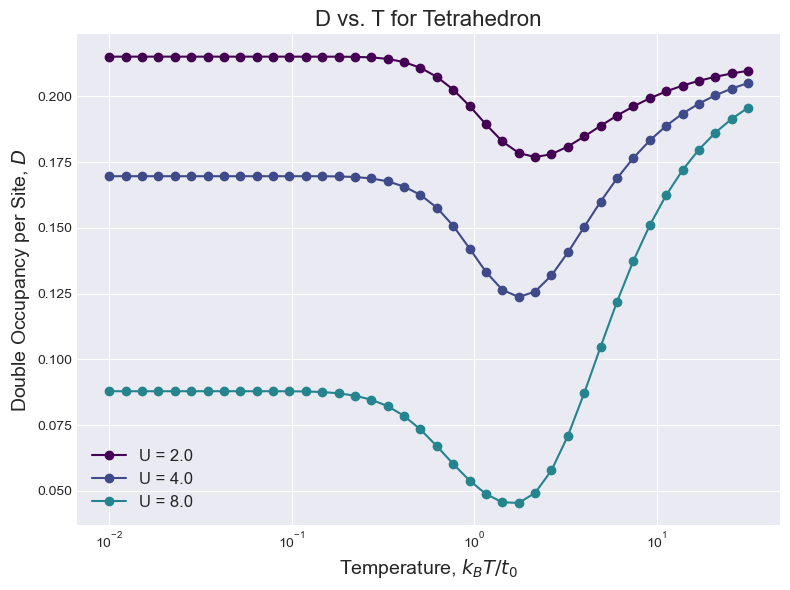


==================== MAIN MENU ====================
Choose an analysis to perform:

--- Single Geometry Analysis ---
   1. D vs. Temperature (for different U values)
   2. D vs. Hopping t0 (for different U values)
   3. D vs. E-Field Component (Ex, Ey, or Ez)

--- Comparative Geometry Analysis (Tetrahedron vs. Octahedron) ---
   4. D vs. Hubbard U
   5. D vs. Hopping t0
   6. D vs. E-Field Amplitude

   0. Exit

Generating plot: D vs T for different U...
ED Solver for Octahedron (6e). Dim = 924
ED Solver for Octahedron (6e). Dim = 924
ED Solver for Octahedron (6e). Dim = 924
ED Solver for Octahedron (6e). Dim = 924
ED Solver for Octahedron (6e). Dim = 924
ED Solver for Octahedron (6e). Dim = 924
ED Solver for Octahedron (6e). Dim = 924
ED Solver for Octahedron (6e). Dim = 924
ED Solver for Octahedron (6e). Dim = 924
ED Solver for Octahedron (6e). Dim = 924
ED Solver for Octahedron (6e). Dim = 924
ED Solver for Octahedron (6e). Dim = 924
ED Solver for Octahedron (6e). Dim = 924
ED Solv

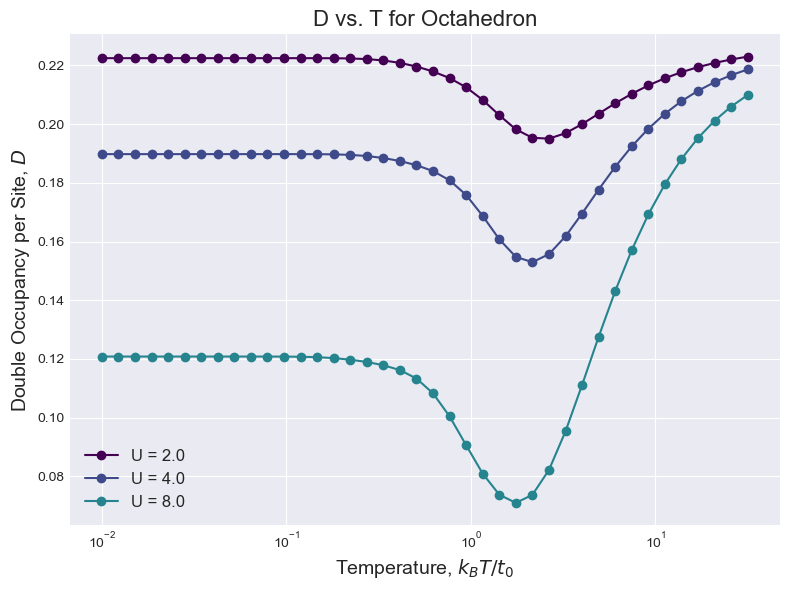


==================== MAIN MENU ====================
Choose an analysis to perform:

--- Single Geometry Analysis ---
   1. D vs. Temperature (for different U values)
   2. D vs. Hopping t0 (for different U values)
   3. D vs. E-Field Component (Ex, Ey, or Ez)

--- Comparative Geometry Analysis (Tetrahedron vs. Octahedron) ---
   4. D vs. Hubbard U
   5. D vs. Hopping t0
   6. D vs. E-Field Amplitude

   0. Exit

Generating plot: D vs t0 for different U...
ED Solver for Tetrahedron (4e). Dim = 70
ED Solver for Tetrahedron (4e). Dim = 70
ED Solver for Tetrahedron (4e). Dim = 70
ED Solver for Tetrahedron (4e). Dim = 70
ED Solver for Tetrahedron (4e). Dim = 70
ED Solver for Tetrahedron (4e). Dim = 70
ED Solver for Tetrahedron (4e). Dim = 70
ED Solver for Tetrahedron (4e). Dim = 70
ED Solver for Tetrahedron (4e). Dim = 70
ED Solver for Tetrahedron (4e). Dim = 70
ED Solver for Tetrahedron (4e). Dim = 70
ED Solver for Tetrahedron (4e). Dim = 70
ED Solver for Tetrahedron (4e). Dim = 70
ED Sol

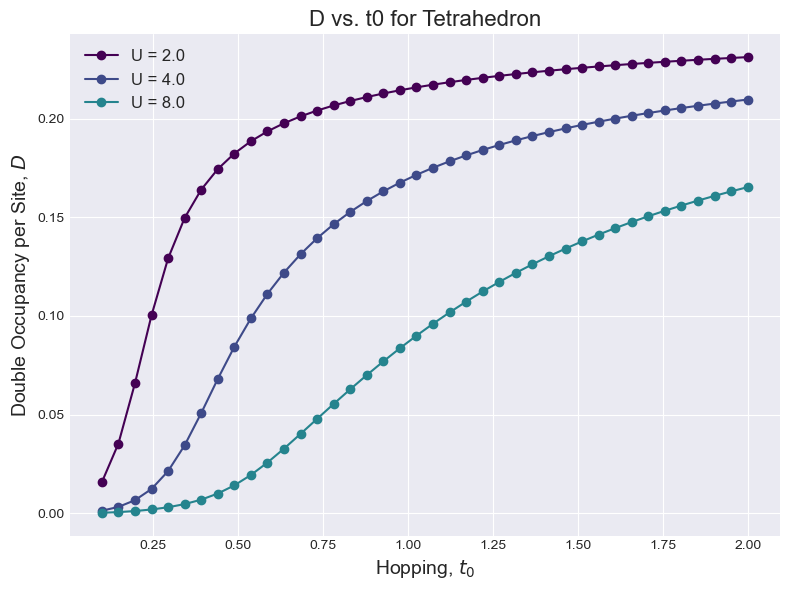


==================== MAIN MENU ====================
Choose an analysis to perform:

--- Single Geometry Analysis ---
   1. D vs. Temperature (for different U values)
   2. D vs. Hopping t0 (for different U values)
   3. D vs. E-Field Component (Ex, Ey, or Ez)

--- Comparative Geometry Analysis (Tetrahedron vs. Octahedron) ---
   4. D vs. Hubbard U
   5. D vs. Hopping t0
   6. D vs. E-Field Amplitude

   0. Exit

Generating plot: D vs t0 for different U...
ED Solver for Octahedron (6e). Dim = 924
ED Solver for Octahedron (6e). Dim = 924
ED Solver for Octahedron (6e). Dim = 924
ED Solver for Octahedron (6e). Dim = 924
ED Solver for Octahedron (6e). Dim = 924
ED Solver for Octahedron (6e). Dim = 924
ED Solver for Octahedron (6e). Dim = 924
ED Solver for Octahedron (6e). Dim = 924
ED Solver for Octahedron (6e). Dim = 924
ED Solver for Octahedron (6e). Dim = 924
ED Solver for Octahedron (6e). Dim = 924
ED Solver for Octahedron (6e). Dim = 924
ED Solver for Octahedron (6e). Dim = 924
ED Sol

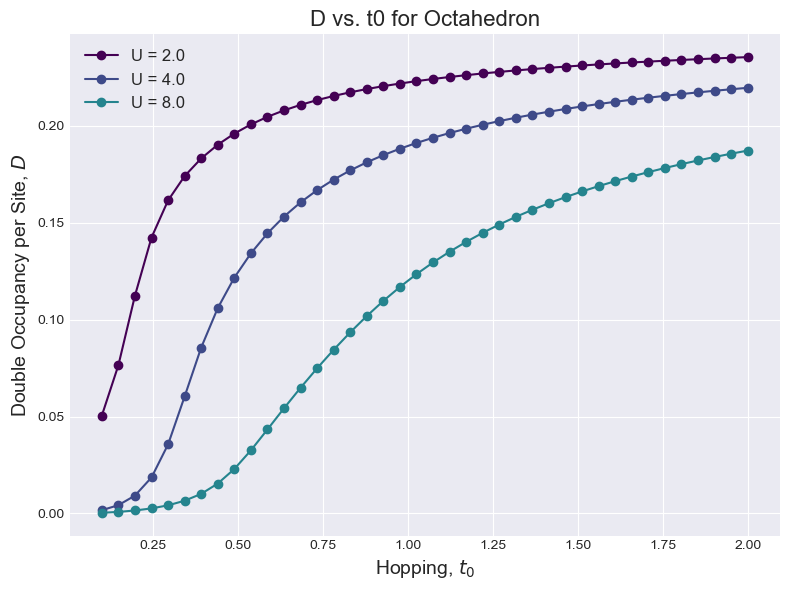


==================== MAIN MENU ====================
Choose an analysis to perform:

--- Single Geometry Analysis ---
   1. D vs. Temperature (for different U values)
   2. D vs. Hopping t0 (for different U values)
   3. D vs. E-Field Component (Ex, Ey, or Ez)

--- Comparative Geometry Analysis (Tetrahedron vs. Octahedron) ---
   4. D vs. Hubbard U
   5. D vs. Hopping t0
   6. D vs. E-Field Amplitude

   0. Exit

Generating plot: D vs Ex for different U...
ED Solver for Tetrahedron (4e). Dim = 70
ED Solver for Tetrahedron (4e). Dim = 70
ED Solver for Tetrahedron (4e). Dim = 70
ED Solver for Tetrahedron (4e). Dim = 70
ED Solver for Tetrahedron (4e). Dim = 70
ED Solver for Tetrahedron (4e). Dim = 70
ED Solver for Tetrahedron (4e). Dim = 70
ED Solver for Tetrahedron (4e). Dim = 70
ED Solver for Tetrahedron (4e). Dim = 70
ED Solver for Tetrahedron (4e). Dim = 70
ED Solver for Tetrahedron (4e). Dim = 70
ED Solver for Tetrahedron (4e). Dim = 70
ED Solver for Tetrahedron (4e). Dim = 70
ED Sol

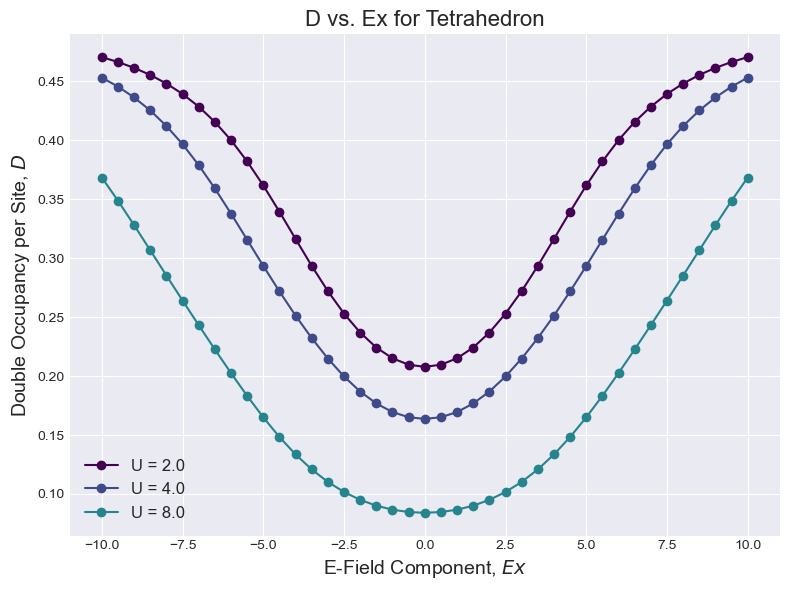


==================== MAIN MENU ====================
Choose an analysis to perform:

--- Single Geometry Analysis ---
   1. D vs. Temperature (for different U values)
   2. D vs. Hopping t0 (for different U values)
   3. D vs. E-Field Component (Ex, Ey, or Ez)

--- Comparative Geometry Analysis (Tetrahedron vs. Octahedron) ---
   4. D vs. Hubbard U
   5. D vs. Hopping t0
   6. D vs. E-Field Amplitude

   0. Exit

Generating plot: D vs Ey for different U...
ED Solver for Tetrahedron (4e). Dim = 70
ED Solver for Tetrahedron (4e). Dim = 70
ED Solver for Tetrahedron (4e). Dim = 70
ED Solver for Tetrahedron (4e). Dim = 70
ED Solver for Tetrahedron (4e). Dim = 70
ED Solver for Tetrahedron (4e). Dim = 70
ED Solver for Tetrahedron (4e). Dim = 70
ED Solver for Tetrahedron (4e). Dim = 70
ED Solver for Tetrahedron (4e). Dim = 70
ED Solver for Tetrahedron (4e). Dim = 70
ED Solver for Tetrahedron (4e). Dim = 70
ED Solver for Tetrahedron (4e). Dim = 70
ED Solver for Tetrahedron (4e). Dim = 70
ED Sol

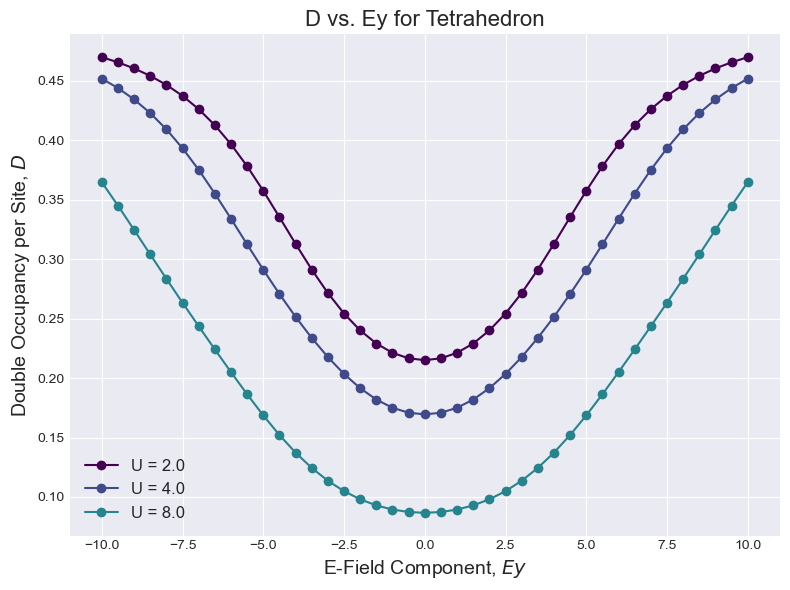


==================== MAIN MENU ====================
Choose an analysis to perform:

--- Single Geometry Analysis ---
   1. D vs. Temperature (for different U values)
   2. D vs. Hopping t0 (for different U values)
   3. D vs. E-Field Component (Ex, Ey, or Ez)

--- Comparative Geometry Analysis (Tetrahedron vs. Octahedron) ---
   4. D vs. Hubbard U
   5. D vs. Hopping t0
   6. D vs. E-Field Amplitude

   0. Exit

Generating plot: D vs Ez for different U...
ED Solver for Tetrahedron (4e). Dim = 70
ED Solver for Tetrahedron (4e). Dim = 70
ED Solver for Tetrahedron (4e). Dim = 70
ED Solver for Tetrahedron (4e). Dim = 70
ED Solver for Tetrahedron (4e). Dim = 70
ED Solver for Tetrahedron (4e). Dim = 70
ED Solver for Tetrahedron (4e). Dim = 70
ED Solver for Tetrahedron (4e). Dim = 70
ED Solver for Tetrahedron (4e). Dim = 70
ED Solver for Tetrahedron (4e). Dim = 70
ED Solver for Tetrahedron (4e). Dim = 70
ED Solver for Tetrahedron (4e). Dim = 70
ED Solver for Tetrahedron (4e). Dim = 70
ED Sol

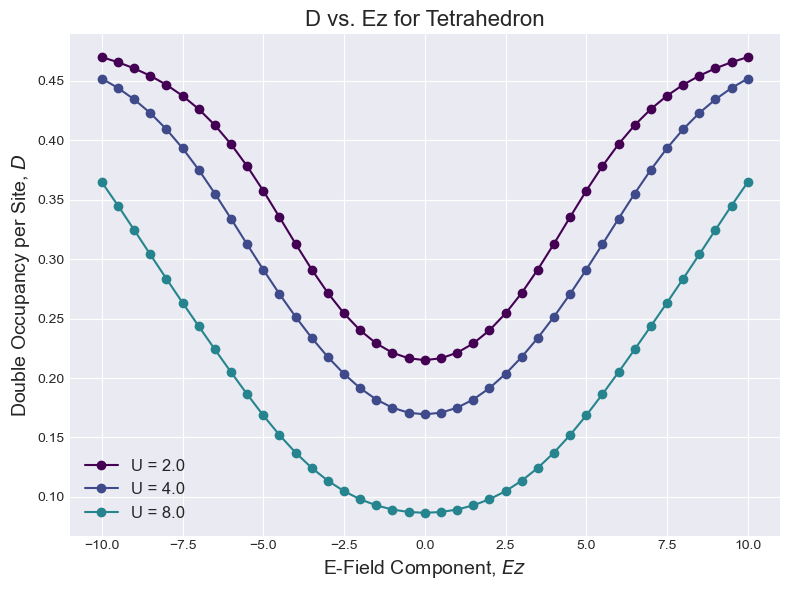


==================== MAIN MENU ====================
Choose an analysis to perform:

--- Single Geometry Analysis ---
   1. D vs. Temperature (for different U values)
   2. D vs. Hopping t0 (for different U values)
   3. D vs. E-Field Component (Ex, Ey, or Ez)

--- Comparative Geometry Analysis (Tetrahedron vs. Octahedron) ---
   4. D vs. Hubbard U
   5. D vs. Hopping t0
   6. D vs. E-Field Amplitude

   0. Exit

Generating plot: Geometry comparison for D vs U...
ED Solver for Tetrahedron (4e). Dim = 70
ED Solver for Tetrahedron (4e). Dim = 70
ED Solver for Tetrahedron (4e). Dim = 70
ED Solver for Tetrahedron (4e). Dim = 70
ED Solver for Tetrahedron (4e). Dim = 70
ED Solver for Tetrahedron (4e). Dim = 70
ED Solver for Tetrahedron (4e). Dim = 70
ED Solver for Tetrahedron (4e). Dim = 70
ED Solver for Tetrahedron (4e). Dim = 70
ED Solver for Tetrahedron (4e). Dim = 70
ED Solver for Tetrahedron (4e). Dim = 70
ED Solver for Tetrahedron (4e). Dim = 70
ED Solver for Tetrahedron (4e). Dim = 70

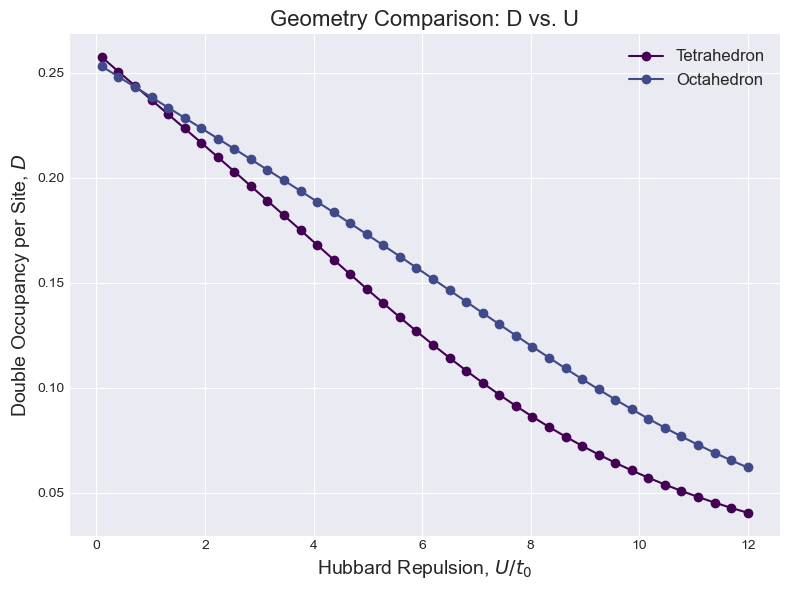


==================== MAIN MENU ====================
Choose an analysis to perform:

--- Single Geometry Analysis ---
   1. D vs. Temperature (for different U values)
   2. D vs. Hopping t0 (for different U values)
   3. D vs. E-Field Component (Ex, Ey, or Ez)

--- Comparative Geometry Analysis (Tetrahedron vs. Octahedron) ---
   4. D vs. Hubbard U
   5. D vs. Hopping t0
   6. D vs. E-Field Amplitude

   0. Exit

Generating plot: Geometry comparison for D vs t0...
ED Solver for Tetrahedron (4e). Dim = 70
ED Solver for Tetrahedron (4e). Dim = 70
ED Solver for Tetrahedron (4e). Dim = 70
ED Solver for Tetrahedron (4e). Dim = 70
ED Solver for Tetrahedron (4e). Dim = 70
ED Solver for Tetrahedron (4e). Dim = 70
ED Solver for Tetrahedron (4e). Dim = 70
ED Solver for Tetrahedron (4e). Dim = 70
ED Solver for Tetrahedron (4e). Dim = 70
ED Solver for Tetrahedron (4e). Dim = 70
ED Solver for Tetrahedron (4e). Dim = 70
ED Solver for Tetrahedron (4e). Dim = 70
ED Solver for Tetrahedron (4e). Dim = 7

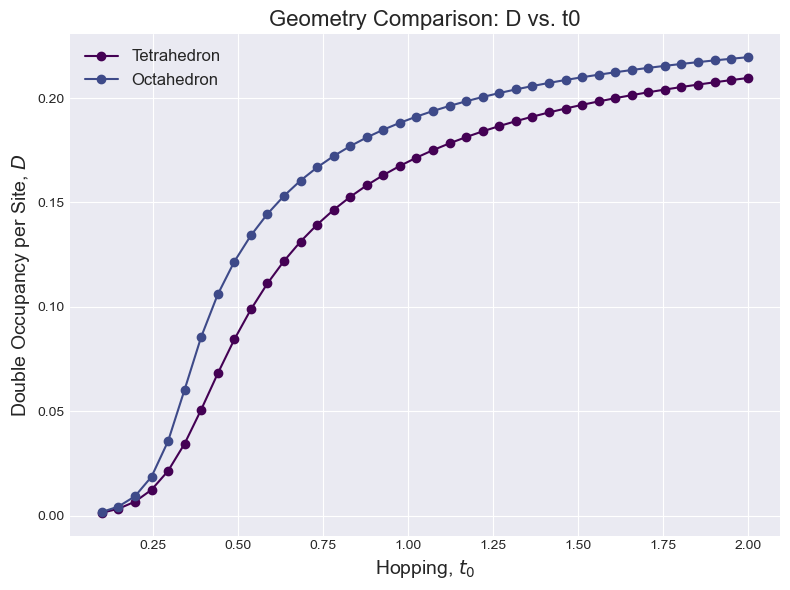


==================== MAIN MENU ====================
Choose an analysis to perform:

--- Single Geometry Analysis ---
   1. D vs. Temperature (for different U values)
   2. D vs. Hopping t0 (for different U values)
   3. D vs. E-Field Component (Ex, Ey, or Ez)

--- Comparative Geometry Analysis (Tetrahedron vs. Octahedron) ---
   4. D vs. Hubbard U
   5. D vs. Hopping t0
   6. D vs. E-Field Amplitude

   0. Exit

Generating plot: Geometry comparison for D vs E_amp...
ED Solver for Tetrahedron (4e). Dim = 70
ED Solver for Tetrahedron (4e). Dim = 70
ED Solver for Tetrahedron (4e). Dim = 70
ED Solver for Tetrahedron (4e). Dim = 70
ED Solver for Tetrahedron (4e). Dim = 70
ED Solver for Tetrahedron (4e). Dim = 70
ED Solver for Tetrahedron (4e). Dim = 70
ED Solver for Tetrahedron (4e). Dim = 70
ED Solver for Tetrahedron (4e). Dim = 70
ED Solver for Tetrahedron (4e). Dim = 70
ED Solver for Tetrahedron (4e). Dim = 70
ED Solver for Tetrahedron (4e). Dim = 70
ED Solver for Tetrahedron (4e). Dim 

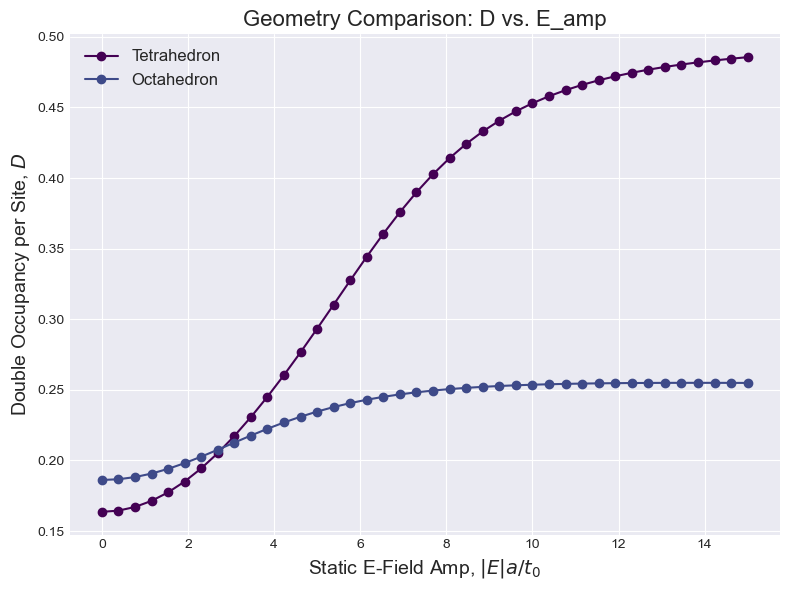


==================== MAIN MENU ====================
Choose an analysis to perform:

--- Single Geometry Analysis ---
   1. D vs. Temperature (for different U values)
   2. D vs. Hopping t0 (for different U values)
   3. D vs. E-Field Component (Ex, Ey, or Ez)

--- Comparative Geometry Analysis (Tetrahedron vs. Octahedron) ---
   4. D vs. Hubbard U
   5. D vs. Hopping t0
   6. D vs. E-Field Amplitude

   0. Exit
Exiting analysis.


In [8]:
import numpy as np
import matplotlib.pyplot as plt
from scipy.linalg import eigh
import os
from typing import List, Dict, Tuple, Any

# --- Constants ---
HBAR = 1.0
E_CHARGE = -1.0
KB = 1.0

# --- Geometry Definitions for Exact Diagonalization ---
GEOMETRIES = {
    "Tetrahedron": {
        "n_sites": 4,
        "coords": np.array([[1, 1, 1], [1, -1, -1], [-1, 1, -1], [-1, -1, 1]]) / np.sqrt(3.0),
        "edges": [(0, 1), (0, 2), (0, 3), (1, 2), (1, 3), (2, 3)],
    },
    "Octahedron": {
        "n_sites": 6,
        "coords": np.array([[1,0,0], [-1,0,0], [0,1,0], [0,-1,0], [0,0,1], [0,0,-1]]),
        "edges": [
            (0,2), (0,3), (0,4), (0,5), (1,2), (1,3), (1,4), (1,5),
            (2,4), (2,5), (3,4), (3,5)
        ],
    }
}

# --- Helper Functions ---
def bit_is_set(n: int, k: int) -> bool:
    """Checks if the k-th bit of integer n is set."""
    return (n >> k) & 1

def bitpos(site: int, spin: int, n_sites: int) -> int:
    """Returns bit position for a given site and spin (0=down, 1=up)."""
    return 2 * site + spin

class SimulationParameters:
    """Container for all simulation parameters."""
    def __init__(self, geometry_name: str, t0: float = 1.0, U: float = 4.0, T: float = 0.1,
                 n_target: float = 1.0, E_vec: np.ndarray = np.array([0.,0.,0.])):
        self.geometry_name = geometry_name
        self.t0 = t0
        self.U = U
        self.T = T
        self.beta = 1.0 / (KB * T) if T > 1e-9 else np.inf
        self.n_target = n_target
        self.E_vec = np.array(E_vec, dtype=float)
        self.E_amp = np.linalg.norm(self.E_vec)

# --- EXACT DIAGONALIZATION SOLVER ---
class ExactDiagonalizationSolver:
    """Solves the Hubbard model for small clusters using Exact Diagonalization."""
    def __init__(self, params: SimulationParameters):
        self.params = params
        self.geom_info = GEOMETRIES[params.geometry_name]
        self.n_sites = self.geom_info["n_sites"]
        self.site_coords = self.geom_info["coords"]
        self.edges = self.geom_info["edges"]
        self.n_target_electrons = int(self.params.n_target * self.n_sites)
        self.basis_states = self._create_basis()
        self.dim = len(self.basis_states)
        self.basis_map = {state: i for i, state in enumerate(self.basis_states)}
        print(f"ED Solver for {self.params.geometry_name} ({self.n_target_electrons}e). Dim = {self.dim}")

    def _create_basis(self) -> List[int]:
        """Creates the list of Fock states with a fixed number of electrons."""
        num_bits = 2 * self.n_sites
        return [i for i in range(2**num_bits) if bin(i).count('1') == self.n_target_electrons]

    def _build_hamiltonian(self) -> np.ndarray:
        """Builds the many-body Hamiltonian matrix in the specified basis."""
        H = np.zeros((self.dim, self.dim), dtype=np.float64)
        for i, state in enumerate(self.basis_states):
            diag_energy = 0.0
            # On-site Coulomb Repulsion (U)
            for s in range(self.n_sites):
                if bit_is_set(state, bitpos(s, 0, self.n_sites)) and bit_is_set(state, bitpos(s, 1, self.n_sites)):
                    diag_energy += self.params.U
            # Static Electric Field Potential
            if self.params.E_amp > 1e-9:
                n_at_site = np.array([bit_is_set(state, bitpos(s, 0, self.n_sites)) + bit_is_set(state, bitpos(s, 1, self.n_sites)) for s in range(self.n_sites)])
                potential_energy = E_CHARGE * np.dot(n_at_site, self.site_coords @ self.params.E_vec)
                diag_energy += potential_energy
            H[i, i] = diag_energy
            # Off-diagonal Hopping Term (t0)
            for s1, s2 in self.edges:
                for spin in (0, 1):
                    b1, b2 = bitpos(s1, spin, self.n_sites), bitpos(s2, spin, self.n_sites)
                    if bit_is_set(state, b1) and not bit_is_set(state, b2):
                        new_state = state ^ (1 << b1) | (1 << b2)
                        j = self.basis_map.get(new_state)
                        if j is not None: H[i, j] -= self.params.t0
                    if bit_is_set(state, b2) and not bit_is_set(state, b1):
                        new_state = state ^ (1 << b2) | (1 << b1)
                        j = self.basis_map.get(new_state)
                        if j is not None: H[i, j] -= self.params.t0
        return H

    def _get_d_operator_diagonal(self) -> np.ndarray:
        """Gets the diagonal of the total Double Occupancy operator in the Fock basis."""
        d_op = np.zeros(self.dim)
        for i, state in enumerate(self.basis_states):
            for s in range(self.n_sites):
                if bit_is_set(state, bitpos(s, 0, self.n_sites)) and bit_is_set(state, bitpos(s, 1, self.n_sites)):
                    d_op[i] += 1
        return d_op

    def solve(self) -> float:
        """Main solve method: diagonalizes H and computes thermal average of D per site."""
        H = self._build_hamiltonian()
        evals, evecs = eigh(H)
        
        evals_shifted = evals - evals[0]
        d_op_total_diag_fock = self._get_d_operator_diagonal()
        d_op_per_site_diag_fock = d_op_total_diag_fock / self.n_sites
        d_expect_per_state = np.einsum('ik,i,ik->k', evecs.conj(), d_op_per_site_diag_fock, evecs, optimize=True)
        
        if self.params.beta == np.inf:
            return d_expect_per_state[0]

        boltzmann_factors = np.exp(-self.params.beta * evals_shifted)
        partition_func = np.sum(boltzmann_factors)
        if partition_func < 1e-12: return d_expect_per_state[0]

        thermal_avg_d = np.sum(d_expect_per_state * boltzmann_factors) / partition_func
        return thermal_avg_d

# --- PLOTTING UTILITY ---
class Plotter:
    """Handles generation of all scientific plots."""
    def __init__(self, output_dir: str = "plots"):
        self.output_dir = output_dir
        if not os.path.exists(self.output_dir):
            os.makedirs(self.output_dir)
        self.color_cycle = plt.cm.viridis(np.linspace(0, 0.9, 5))

    def _get_solver(self, params: SimulationParameters) -> Any:
        """Factory method to get the correct solver based on geometry."""
        return ExactDiagonalizationSolver(params)

    def _create_params_for_sweep(self, baseline_params: SimulationParameters, sweep_vars: Dict[str, Any]) -> SimulationParameters:
        """Creates a new SimulationParameters object by updating the baseline with sweep variables."""
        # Start with a dictionary of the baseline constructor arguments
        p_dict = {
            'geometry_name': baseline_params.geometry_name,
            't0': baseline_params.t0,
            'U': baseline_params.U,
            'T': baseline_params.T,
            'n_target': baseline_params.n_target,
            'E_vec': baseline_params.E_vec.copy(), # Use a copy to avoid modifying the original
        }
        # Update the dict with any direct parameter sweeps
        for key, value in sweep_vars.items():
            if key in p_dict:
                p_dict[key] = value
        # Handle special cases that modify E_vec
        if 'E_amp' in sweep_vars:
            e_amp = sweep_vars['E_amp']
            base_vec = baseline_params.E_vec
            direction = base_vec / np.linalg.norm(base_vec) if np.linalg.norm(base_vec) > 1e-9 else np.array([1., 0., 0.])
            p_dict['E_vec'] = e_amp * direction
        elif 'Ex' in sweep_vars:
            p_dict['E_vec'][0] = sweep_vars['Ex']
        elif 'Ey' in sweep_vars:
            p_dict['E_vec'][1] = sweep_vars['Ey']
        elif 'Ez' in sweep_vars:
            p_dict['E_vec'][2] = sweep_vars['Ez']
            
        return SimulationParameters(**p_dict)

    def plot_D_vs_param_list(self, x_param_name: str, x_values: np.ndarray, x_label: str, compare_param_name: str, compare_values: List, baseline_params: SimulationParameters, log_scale: bool = False):
        """Plots D vs. a parameter, with different lines for a second comparison parameter."""
        print(f"\nGenerating plot: D vs {x_param_name} for different {compare_param_name}...")
        with plt.style.context('seaborn-v0_8-darkgrid'):
            plt.figure(figsize=(8, 6))
            for i, comp_val in enumerate(compare_values):
                y_values = []
                for x_val in x_values:
                    p = self._create_params_for_sweep(baseline_params, {x_param_name: x_val, compare_param_name: comp_val})
                    solver = self._get_solver(p)
                    y_values.append(solver.solve())
                plt.plot(x_values, y_values, 'o-', label=f'{compare_param_name} = {comp_val:.1f}', color=self.color_cycle[i])
                print(f"  Completed curve for {compare_param_name} = {comp_val}")

            if log_scale: plt.xscale('log')
            plt.xlabel(x_label, fontsize=14)
            plt.ylabel('Double Occupancy per Site, $D$', fontsize=14)
            title = f'D vs. {x_param_name} for {baseline_params.geometry_name}'
            plt.title(title, fontsize=16)
            plt.legend(fontsize=12)
            plt.tight_layout()
            
            filename = f"D_vs_{x_param_name}_compare_{compare_param_name}_for_{baseline_params.geometry_name}.png"
            filepath = os.path.join(self.output_dir, filename)
            plt.savefig(filepath, dpi=300)
            print(f"Plot saved to: {filepath}")
            plt.show()

    def plot_geometry_comparison(self, x_param_name: str, x_values: np.ndarray, x_label: str, baseline_params: SimulationParameters, log_scale: bool = False):
        """Plots D vs. a parameter on the same axes for different geometries."""
        print(f"\nGenerating plot: Geometry comparison for D vs {x_param_name}...")
        with plt.style.context('seaborn-v0_8-darkgrid'):
            plt.figure(figsize=(8, 6))
            geometries_to_compare = ["Tetrahedron", "Octahedron"]
            for i, geom in enumerate(geometries_to_compare):
                y_values = []
                geom_baseline_params = SimulationParameters(geometry_name=geom, t0=baseline_params.t0, U=baseline_params.U, T=baseline_params.T, E_vec=baseline_params.E_vec)
                for x_val in x_values:
                    p = self._create_params_for_sweep(geom_baseline_params, {x_param_name: x_val})
                    solver = self._get_solver(p)
                    y_values.append(solver.solve())
                plt.plot(x_values, y_values, 'o-', label=geom, color=self.color_cycle[i])
                print(f"  Completed curve for {geom}")

            if log_scale: plt.xscale('log')
            plt.xlabel(x_label, fontsize=14)
            plt.ylabel('Double Occupancy per Site, $D$', fontsize=14)
            title = f'Geometry Comparison: D vs. {x_param_name}'
            plt.title(title, fontsize=16)
            plt.legend(fontsize=12)
            plt.tight_layout()
            
            filename = f"Geometry_Comparison_D_vs_{x_param_name}.png"
            filepath = os.path.join(self.output_dir, filename)
            plt.savefig(filepath, dpi=300)
            print(f"Plot saved to: {filepath}")
            plt.show()

# --- MAIN DRIVER ---
def main():
    """Main interactive loop for the user."""
    print("="*60)
    print(" 3D Hubbard Model: Correlation Control Analyzer ".center(60, "="))
    print("="*60)

    print("\nSetting baseline parameters for all simulations:")
    t0 = float(input("   Enter baseline hopping t0 (e.g., 1.0): "))
    U = float(input("   Enter baseline Hubbard U (e.g., 4.0): "))
    T = float(input("   Enter baseline Temperature T (e.g., 0.1): "))
    n_target = 1.0
    print(f"   Density is fixed at half-filling (n={n_target}).")

    print("   Enter E-Field Vector (defines direction and baseline strength):")
    Ex = float(input("     Ex (e.g., 1.0): "))
    Ey = float(input("     Ey (e.g., 0.0): "))
    Ez = float(input("     Ez (e.g., 0.0): "))
    E_vec = np.array([Ex, Ey, Ez])
    
    plotter = Plotter()

    while True:
        print("\n" + "="*20 + " MAIN MENU " + "="*20)
        print("Choose an analysis to perform:")
        print("\n--- Single Geometry Analysis ---")
        print("   1. D vs. Temperature (for different U values)")
        print("   2. D vs. Hopping t0 (for different U values)")
        print("   3. D vs. E-Field Component (Ex, Ey, or Ez)")
        print("\n--- Comparative Geometry Analysis (Tetrahedron vs. Octahedron) ---")
        print("   4. D vs. Hubbard U")
        print("   5. D vs. Hopping t0")
        print("   6. D vs. E-Field Amplitude")
        print("\n   0. Exit")
        
        choice = input("Enter choice: ")

        if choice == '1' or choice == '2' or choice == '3':
            geom = input("   Choose geometry for this analysis (Tetrahedron/Octahedron): ")
            if geom not in GEOMETRIES: print("Invalid geometry."); continue
            analysis_params = SimulationParameters(geometry_name=geom, t0=t0, U=U, T=T, n_target=n_target, E_vec=E_vec)
            
            if choice == '1':
                x_vals = np.logspace(-2, 1.5, 40)
                plotter.plot_D_vs_param_list('T', x_vals, 'Temperature, $k_B T/t_0$', 'U', [2.0, 4.0, 8.0], analysis_params, log_scale=True)
            elif choice == '2':
                x_vals = np.linspace(0.1, 2.0, 40)
                plotter.plot_D_vs_param_list('t0', x_vals, 'Hopping, $t_0$', 'U', [2.0, 4.0, 8.0], analysis_params)
            elif choice == '3':
                comp = input("   Sweep which E-field component? (Ex/Ey/Ez): ").strip()
                if comp not in ['Ex', 'Ey', 'Ez']: print("Invalid component."); continue
                x_vals = np.linspace(-10.0, 10.0, 41)
                plotter.plot_D_vs_param_list(comp, x_vals, f'E-Field Component, ${comp}$', 'U', [2.0, 4.0, 8.0], analysis_params)

        elif choice == '4' or choice == '5' or choice == '6':
            base_comp_params = SimulationParameters(geometry_name="N/A", t0=t0, U=U, T=T, n_target=n_target, E_vec=E_vec)
            if choice == '4':
                x_vals = np.linspace(0.1, 12.0, 40)
                plotter.plot_geometry_comparison('U', x_vals, 'Hubbard Repulsion, $U/t_0$', base_comp_params)
            elif choice == '5':
                x_vals = np.linspace(0.1, 2.0, 40)
                plotter.plot_geometry_comparison('t0', x_vals, 'Hopping, $t_0$', base_comp_params)
            elif choice == '6':
                x_vals = np.linspace(0.0, 15.0, 40)
                plotter.plot_geometry_comparison('E_amp', x_vals, 'Static E-Field Amp, $|E|a/t_0$', base_comp_params)

        elif choice == '0':
            print("Exiting analysis.")
            break
        else:
            print("Invalid choice, please try again.")

if __name__ == '__main__':
    main()


In [ ]:
import numpy as np
import matplotlib.pyplot as plt
import matplotlib.gridspec as gridspec
from scipy.linalg import eigh
from scipy.special import comb
import os
from typing import List, Dict, Tuple, Any

# --- Constants ---
HBAR = 1.0
E_CHARGE = -1.0
KB = 1.0
MAX_BASIS_DIM = 20000 # Safety limit to prevent memory overflow

# --- Geometry Definitions ---
GEOMETRIES = {
    "Tetrahedron": {
        "n_sites": 4,
        "coords": np.array([[1, 1, 1], [1, -1, -1], [-1, 1, -1], [-1, -1, 1]]) / np.sqrt(3.0),
        "edges": [(0, 1), (0, 2), (0, 3), (1, 2), (1, 3), (2, 3)],
    },
    "Octahedron": {
        "n_sites": 6,
        "coords": np.array([[1,0,0], [-1,0,0], [0,1,0], [0,-1,0], [0,0,1], [0,0,-1]]),
        "edges": [
            (0,2), (0,3), (0,4), (0,5), (1,2), (1,3), (1,4), (1,5),
            (2,4), (2,5), (3,4), (3,5)
        ],
    }
}

# --- Helper Functions ---
def bit_is_set(n: int, k: int) -> bool:
    """Checks if the k-th bit of integer n is set."""
    return (n >> k) & 1

def bitpos(site: int, orbital: int, spin: int, n_orbitals: int) -> int:
    """
    Returns the bit position for a given site, orbital, and spin.
    Spin convention: 0=down, 1=up.
    The bits are ordered as: (site0,orb0,dn), (site0,orb0,up), (site0,orb1,dn), (site0,orb1,up), ...
    """
    return 2 * (site * n_orbitals + orbital) + spin

class SimulationParameters:
    """Container for all simulation parameters, now with multi-orbital support."""
    def __init__(self, geometry_name: str, n_orbitals: int = 1, t0: float = 1.0, 
                 t_orb: float = 0.0, U: float = 4.0, T: float = 0.1,
                 n_target_fill: float = 0.5, E_vec: np.ndarray = np.array([0.,0.,0.])):
        self.geometry_name = geometry_name
        self.n_orbitals = n_orbitals
        self.t0 = t0
        self.t_orb = t_orb # New: Hopping between orbitals on the same site
        self.U = U
        self.T = T
        self.beta = 1.0 / (KB * T) if T > 1e-9 else np.inf
        self.n_target_fill = n_target_fill # Filling per orbital-site (0.5 = half-filling)
        self.E_vec = np.array(E_vec, dtype=float)
        self.E_amp = np.linalg.norm(self.E_vec)

# --- EXACT DIAGONALIZATION SOLVER ---
class ExactDiagonalizationSolver:
    """
    Solves the multi-orbital Hubbard model for small clusters using Exact Diagonalization.
    """
    def __init__(self, params: SimulationParameters):
        self.params = params
        self.geom_info = GEOMETRIES[params.geometry_name]
        self.n_sites = self.geom_info["n_sites"]
        self.site_coords = self.geom_info["coords"]
        self.edges = self.geom_info["edges"]
        
        self.num_orbital_sites = self.n_sites * self.params.n_orbitals
        self.n_target_electrons = int(self.params.n_target_fill * 2 * self.num_orbital_sites)

        self.basis_states = self._create_basis()
        self.dim = len(self.basis_states)

        if self.dim > MAX_BASIS_DIM:
            raise ValueError(
                f"Basis dimension ({self.dim}) exceeds safety limit ({MAX_BASIS_DIM}). "
                f"The combination of {self.n_sites} sites, {self.params.n_orbitals} orbitals, "
                f"and {self.n_target_electrons} electrons is too large for exact diagonalization."
            )

        self.basis_map = {state: i for i, state in enumerate(self.basis_states)}
        print(f"ED Solver for {self.params.geometry_name} ({self.params.n_orbitals} orbitals, {self.n_target_electrons}e). Hilbert space Dim = {self.dim}")

    def _create_basis(self) -> List[int]:
        """Creates the list of Fock states with a fixed number of electrons."""
        num_bits = 2 * self.num_orbital_sites
        
        # Check if calculation is feasible before generating basis
        if self.n_target_electrons > num_bits or self.n_target_electrons < 0:
             return []
        dim_check = comb(num_bits, self.n_target_electrons, exact=True)
        if dim_check > MAX_BASIS_DIM:
            raise ValueError(
                f"Predicted basis dimension ({dim_check}) exceeds safety limit ({MAX_BASIS_DIM}). Aborting."
            )
            
        return [i for i in range(2**num_bits) if bin(i).count('1') == self.n_target_electrons]

    def _build_hamiltonian(self) -> np.ndarray:
        """Builds the many-body Hamiltonian matrix for the multi-orbital model."""
        H = np.zeros((self.dim, self.dim), dtype=np.float64)
        n_orb = self.params.n_orbitals

        for i, state in enumerate(self.basis_states):
            diag_energy = 0.0
            
            # --- DIAGONAL TERMS ---
            # 1. On-site, Intra-orbital Coulomb Repulsion (U)
            for s in range(self.n_sites):
                for o in range(n_orb):
                    pos_dn = bitpos(s, o, 0, n_orb)
                    pos_up = bitpos(s, o, 1, n_orb)
                    if bit_is_set(state, pos_dn) and bit_is_set(state, pos_up):
                        diag_energy += self.params.U

            # 2. Static Electric Field Potential
            if self.params.E_amp > 1e-9:
                potential_energy = 0.0
                for s in range(self.n_sites):
                    n_at_site = 0
                    for o in range(n_orb):
                        for spin in (0, 1):
                            if bit_is_set(state, bitpos(s, o, spin, n_orb)):
                                n_at_site += 1
                    potential_energy += E_CHARGE * np.dot(self.site_coords[s], self.params.E_vec) * n_at_site
                diag_energy += potential_energy
            
            H[i, i] = diag_energy

            # --- OFF-DIAGONAL TERMS ---
            # 1. Intra-orbital, Inter-site Hopping (t0)
            for s1, s2 in self.edges:
                for o in range(n_orb):
                    for spin in (0, 1):
                        b1, b2 = bitpos(s1, o, spin, n_orb), bitpos(s2, o, spin, n_orb)
                        # Hopping from s1 to s2
                        if bit_is_set(state, b1) and not bit_is_set(state, b2):
                            new_state = state ^ (1 << b1) | (1 << b2)
                            j = self.basis_map.get(new_state)
                            if j is not None: H[i, j] -= self.params.t0
                        # Hopping from s2 to s1
                        if bit_is_set(state, b2) and not bit_is_set(state, b1):
                            new_state = state ^ (1 << b2) | (1 << b1)
                            j = self.basis_map.get(new_state)
                            if j is not None: H[i, j] -= self.params.t0
            
            # 2. Inter-orbital, Intra-site Hopping (t_orb)
            if n_orb > 1 and abs(self.params.t_orb) > 1e-9:
                for s in range(self.n_sites):
                    for o1 in range(n_orb):
                        for o2 in range(o1 + 1, n_orb):
                            for spin in (0, 1):
                                b1, b2 = bitpos(s, o1, spin, n_orb), bitpos(s, o2, spin, n_orb)
                                # Hopping from o1 to o2
                                if bit_is_set(state, b1) and not bit_is_set(state, b2):
                                    new_state = state ^ (1 << b1) | (1 << b2)
                                    j = self.basis_map.get(new_state)
                                    if j is not None: H[i, j] -= self.params.t_orb
                                # Hopping from o2 to o1
                                if bit_is_set(state, b2) and not bit_is_set(state, b1):
                                    new_state = state ^ (1 << b2) | (1 << b1)
                                    j = self.basis_map.get(new_state)
                                    if j is not None: H[i, j] -= self.params.t_orb
        return H

    def _get_d_operator_diagonal(self, orbital_index: int) -> np.ndarray:
        """Gets the diagonal of the Double Occupancy operator for a specific orbital."""
        d_op = np.zeros(self.dim)
        for i, state in enumerate(self.basis_states):
            for s in range(self.n_sites):
                pos_dn = bitpos(s, orbital_index, 0, self.params.n_orbitals)
                pos_up = bitpos(s, orbital_index, 1, self.params.n_orbitals)
                if bit_is_set(state, pos_dn) and bit_is_set(state, pos_up):
                    d_op[i] += 1
        return d_op

    def solve(self) -> Dict[str, Any]:
        """
        Main solve method: diagonalizes H and computes thermal averages.
        Returns a dictionary with total and per-orbital double occupancy.
        """
        H = self._build_hamiltonian()
        evals, evecs = eigh(H)
        
        evals_shifted = evals - evals[0]
        
        # Calculate expectation value for each orbital's double occupancy
        d_expect_per_orbital = []
        for o in range(self.params.n_orbitals):
            d_op_diag_fock = self._get_d_operator_diagonal(o)
            d_op_per_site_diag_fock = d_op_diag_fock / self.n_sites
            d_expect_per_state = np.einsum('ik,i,ik->k', evecs.conj(), d_op_per_site_diag_fock, evecs, optimize=True)
            d_expect_per_orbital.append(d_expect_per_state)

        # Ground state result (T=0)
        if self.params.beta == np.inf:
            gs_d_per_orbital = [d[0] for d in d_expect_per_orbital]
            return {
                "total_D": np.sum(gs_d_per_orbital),
                "orbital_D": gs_d_per_orbital
            }

        # Finite temperature result
        boltzmann_factors = np.exp(-self.params.beta * evals_shifted)
        partition_func = np.sum(boltzmann_factors)
        if partition_func < 1e-12: # Avoid division by zero
            gs_d_per_orbital = [d[0] for d in d_expect_per_orbital]
            return {
                "total_D": np.sum(gs_d_per_orbital),
                "orbital_D": gs_d_per_orbital
            }

        thermal_avg_d_per_orbital = [
            np.sum(d_expect * boltzmann_factors) / partition_func for d_expect in d_expect_per_orbital
        ]
        
        return {
            "total_D": np.sum(thermal_avg_d_per_orbital),
            "orbital_D": thermal_avg_d_per_orbital
        }

# --- PLOTTING UTILITY ---
class Plotter:
    """Handles generation of all scientific plots, now with multi-orbital awareness."""
    def __init__(self, output_dir: str = "plots"):
        self.output_dir = output_dir
        if not os.path.exists(self.output_dir):
            os.makedirs(self.output_dir)
        self.color_cycle = plt.cm.viridis(np.linspace(0, 0.9, 5))
        self.color_cycle_comp = [plt.cm.plasma(0.3), plt.cm.plasma(0.7)]

    def _get_solver(self, params: SimulationParameters) -> Any:
        return ExactDiagonalizationSolver(params)

    def _create_params_for_sweep(self, baseline_params: SimulationParameters, sweep_vars: Dict[str, Any]) -> SimulationParameters:
        p_dict = {
            'geometry_name': baseline_params.geometry_name, 'n_orbitals': baseline_params.n_orbitals,
            't0': baseline_params.t0, 't_orb': baseline_params.t_orb, 'U': baseline_params.U,
            'T': baseline_params.T, 'n_target_fill': baseline_params.n_target_fill,
            'E_vec': baseline_params.E_vec.copy(),
        }
        p_dict.update(sweep_vars)
        
        if 'E_amp' in sweep_vars:
            e_amp = sweep_vars['E_amp']
            base_vec = baseline_params.E_vec
            direction = base_vec / np.linalg.norm(base_vec) if np.linalg.norm(base_vec) > 1e-9 else np.array([1., 0., 0.])
            p_dict['E_vec'] = e_amp * direction
            
        return SimulationParameters(**p_dict)

    def plot_D_vs_param_with_insets(self, x_param_name: str, x_values: np.ndarray, x_label: str, compare_param_name: str, compare_values: List, baseline_params: SimulationParameters, log_scale: bool = False):
        """
        SPECIAL PLOT: Plots D vs. a parameter for the 2-orbital Tetrahedron.
        Main plot: Total D.
        Two insets: D for orbital 1 and D for orbital 2.
        """
        print(f"\nGenerating special plot with insets: D vs {x_param_name} for different {compare_param_name}...")
        
        fig = plt.figure(figsize=(10, 10))
        gs = gridspec.GridSpec(3, 2, figure=fig, hspace=0.05, wspace=0.3)
        ax_main = fig.add_subplot(gs[0:2, :])
        ax_inset1 = fig.add_subplot(gs[2, 0])
        ax_inset2 = fig.add_subplot(gs[2, 1])

        plt.setp(ax_main.get_xticklabels(), visible=False)

        for i, comp_val in enumerate(compare_values):
            results_total_d = []
            results_orb0_d = []
            results_orb1_d = []
            for x_val in x_values:
                p = self._create_params_for_sweep(baseline_params, {x_param_name: x_val, compare_param_name: comp_val})
                solver = self._get_solver(p)
                res = solver.solve()
                results_total_d.append(res['total_D'])
                results_orb0_d.append(res['orbital_D'][0])
                results_orb1_d.append(res['orbital_D'][1])
            
            label = f'{compare_param_name} = {comp_val:.1f}'
            color = self.color_cycle[i]
            ax_main.plot(x_values, results_total_d, 'o-', label=label, color=color)
            ax_inset1.plot(x_values, results_orb0_d, '.-', label=label, color=color)
            ax_inset2.plot(x_values, results_orb1_d, '.-', label=label, color=color)
            print(f"  Completed curve for {compare_param_name} = {comp_val}")

        if log_scale:
            ax_main.set_xscale('log')
            ax_inset1.set_xscale('log')
            ax_inset2.set_xscale('log')

        ax_main.set_ylabel('Total Double Occupancy per Site, $D_{total}$', fontsize=14)
        ax_main.set_title(f'Total and Per-Orbital D vs. {x_param_name} for 2-Orbital {baseline_params.geometry_name}', fontsize=16)
        ax_main.legend(fontsize=12, loc='best')
        ax_main.grid(True)

        ax_inset1.set_xlabel(x_label, fontsize=12)
        ax_inset1.set_ylabel('$D_{orb=1}$', fontsize=12)
        ax_inset1.grid(True)
        
        ax_inset2.set_xlabel(x_label, fontsize=12)
        ax_inset2.set_ylabel('$D_{orb=2}$', fontsize=12)
        ax_inset2.grid(True)
        
        fig.tight_layout(rect=[0, 0, 1, 0.96])
        
        filename = f"Inset_D_vs_{x_param_name}_compare_{compare_param_name}_for_2Orb_{baseline_params.geometry_name}.png"
        filepath = os.path.join(self.output_dir, filename)
        plt.savefig(filepath, dpi=300)
        print(f"Plot saved to: {filepath}")
        plt.show()


    def plot_geometry_comparison(self, x_param_name: str, x_values: np.ndarray, x_label: str, baseline_params: SimulationParameters, log_scale: bool = False):
        """Plots D vs. a parameter on the same axes for different geometries."""
        print(f"\nGenerating plot: Geometry comparison for D vs {x_param_name}...")
        with plt.style.context('seaborn-v0_8-darkgrid'):
            plt.figure(figsize=(8, 6))
            geometries_to_compare = ["Tetrahedron", "Octahedron"]
            for i, geom in enumerate(geometries_to_compare):
                y_values = []
                # Use single orbital for geometry comparison to keep it comparable and fast
                geom_baseline_params = SimulationParameters(
                    geometry_name=geom, n_orbitals=1, t0=baseline_params.t0, 
                    U=baseline_params.U, T=baseline_params.T, E_vec=baseline_params.E_vec
                )
                for x_val in x_values:
                    p = self._create_params_for_sweep(geom_baseline_params, {x_param_name: x_val})
                    solver = self._get_solver(p)
                    res = solver.solve()
                    y_values.append(res['total_D'])
                plt.plot(x_values, y_values, 'o-', label=geom, color=self.color_cycle_comp[i])
                print(f"  Completed curve for {geom}")

            if log_scale: plt.xscale('log')
            plt.xlabel(x_label, fontsize=14)
            plt.ylabel('Double Occupancy per Site, $D$', fontsize=14)
            title = f'Geometry Comparison: D vs. {x_param_name} (Single Orbital)'
            plt.title(title, fontsize=16)
            plt.legend(fontsize=12)
            plt.tight_layout()
            
            filename = f"Geometry_Comparison_D_vs_{x_param_name}.png"
            filepath = os.path.join(self.output_dir, filename)
            plt.savefig(filepath, dpi=300)
            print(f"Plot saved to: {filepath}")
            plt.show()

# --- MAIN DRIVER ---
def main():
    """Main interactive loop for the user."""
    print("="*60)
    print(" Multi-Orbital 3D Hubbard Model: Analyzer ".center(60, "="))
    print("="*60)

    plotter = Plotter()

    while True:
        print("\n" + "="*23 + " MAIN MENU " + "="*24)
        print("Choose an analysis type:")
        print("   1. Single-Orbital Analysis (Fast, for both geometries)")
        print("   2. Multi-Orbital Analysis (Slow, Tetrahedron only)")
        print("\n   0. Exit")
        
        menu_choice = input("Enter choice: ")

        if menu_choice == '1':
            run_single_orbital_menu(plotter)
        elif menu_choice == '2':
            run_multi_orbital_menu(plotter)
        elif menu_choice == '0':
            print("Exiting analysis.")
            break
        else:
            print("Invalid choice, please try again.")

def run_single_orbital_menu(plotter):
    """Handles the user menu for single-orbital calculations."""
    print("\n--- Single-Orbital Analysis Menu ---")
    print("\nSetting baseline parameters for single-orbital simulations:")
    t0 = float(input("   Enter baseline hopping t0 (e.g., 1.0): "))
    U = float(input("   Enter baseline Hubbard U (e.g., 4.0): "))
    T = float(input("   Enter baseline Temperature T (e.g., 0.1): "))
    base_comp_params = SimulationParameters(geometry_name="N/A", n_orbitals=1, t0=t0, U=U, T=T)

    print("\nChoose a comparative geometry analysis:")
    print("   1. D vs. Hubbard U")
    print("   2. D vs. Hopping t0")
    print("   3. D vs. E-Field Amplitude")
    print("   0. Back to Main Menu")
    choice = input("Enter choice: ")

    try:
        if choice == '1':
            x_vals = np.linspace(0.1, 12.0, 40)
            plotter.plot_geometry_comparison('U', x_vals, 'Hubbard Repulsion, $U/t_0$', base_comp_params)
        elif choice == '2':
            x_vals = np.linspace(0.1, 2.0, 40)
            plotter.plot_geometry_comparison('t0', x_vals, 'Hopping, $t_0$', base_comp_params)
        elif choice == '3':
            x_vals = np.linspace(0.0, 15.0, 40)
            E_vec = np.array([1.0, 0.0, 0.0]) # Define a direction for the field
            params_with_efield = SimulationParameters(geometry_name="N/A", n_orbitals=1, t0=t0, U=U, T=T, E_vec=E_vec)
            plotter.plot_geometry_comparison('E_amp', x_vals, 'Static E-Field Amp, $|E|a/t_0$', params_with_efield)
        elif choice == '0':
            return
    except (ValueError, np.linalg.LinAlgError) as e:
        print(f"\n--- An error occurred during calculation: ---")
        print(e)
        print("Please check your parameters. This can happen with very large or small numbers.")


def run_multi_orbital_menu(plotter):
    """Handles the user menu for multi-orbital calculations."""
    print("\n--- Multi-Orbital Analysis Menu (Tetrahedron Only) ---")
    print("WARNING: These calculations are computationally intensive.")
    
    print("\nSetting baseline parameters for 2-orbital simulations:")
    t0 = float(input("   Enter baseline intra-orbital hopping t0 (e.g., 1.0): "))
    t_orb = float(input("   Enter baseline inter-orbital hopping t_orb (e.g., 0.2): "))
    U = float(input("   Enter baseline Hubbard U (e.g., 4.0): "))
    T = float(input("   Enter baseline Temperature T (e.g., 0.1): "))
    
    # Hard-code 2 orbitals for this menu
    analysis_params = SimulationParameters(
        geometry_name="Tetrahedron", n_orbitals=2, t0=t0, t_orb=t_orb, U=U, T=T
    )

    print("\nChoose an analysis to perform on the 2-Orbital Tetrahedron:")
    print("   1. D vs. Temperature (with orbital-resolved insets)")
    print("   0. Back to Main Menu")
    choice = input("Enter choice: ")

    try:
        if choice == '1':
            x_vals = np.logspace(-2, 1.5, 40)
            u_values_to_compare = [2.0, 4.0, 8.0]
            plotter.plot_D_vs_param_with_insets('T', x_vals, 'Temperature, $k_B T/t_0$', 'U', u_values_to_compare, analysis_params, log_scale=True)
        elif choice == '0':
            return
    except (ValueError, np.linalg.LinAlgError) as e:
        print(f"\n--- An error occurred during calculation: ---")
        print(e)
        print("Please check your parameters.")

if __name__ == '__main__':
    main()


========= Multi-Orbital 3D Hubbard Model: Analyzer =========

======================= MAIN MENU ========================
Choose an analysis type:
   1. Single-Orbital Analysis (Fast, for both geometries)
   2. Multi-Orbital Analysis (Slow, Tetrahedron only)

   0. Exit

--- Multi-Orbital Analysis Menu (Tetrahedron Only) ---

Setting baseline parameters for 2-orbital simulations:

Choose an analysis to perform on the 2-Orbital Tetrahedron:
   1. D vs. Temperature (with orbital-resolved insets)
   0. Back to Main Menu

Generating special plot with insets: D vs T for different U...
ED Solver for Tetrahedron (2 orbitals, 8e). Hilbert space Dim = 12870
ED Solver for Tetrahedron (2 orbitals, 8e). Hilbert space Dim = 12870


==== High-Performance Multi-Orbital 3D Hubbard Analyzer ====

======================= MAIN MENU ========================
Choose an analysis type:
   1. 2-Orbital Comparative Analysis (Fast Calculation)

   0. Exit

--- 2-Orbital Comparative Analysis ---
This mode uses a fast, approximate solver for all calculations.

Setting baseline parameters for 2-orbital simulations:

Choose an analysis to perform:
   1. D vs. Hubbard U
   2. D vs. Inter-Orbital Hopping (t_orb)
   3. D vs. Intra-Orbital Hopping (t0)
   0. Back to Main Menu

Generating 2-Orbital Comparison Plot: D vs U...
Calculating for Tetrahedron...
  -> Using Mean-Field Theory for Tetrahedron (2 orb, 8e).
  -> Using Mean-Field Theory for Tetrahedron (2 orb, 8e).
  -> Using Mean-Field Theory for Tetrahedron (2 orb, 8e).
  -> Using Mean-Field Theory for Tetrahedron (2 orb, 8e).
  -> Using Mean-Field Theory for Tetrahedron (2 orb, 8e).
  -> Using Mean-Field Theory for Tetrahedron (2 orb, 8e).
  -> Using Mean-Field Theory for Tetrah

/var/folders/84/c1f888hj3nl61gx1s2sy_krc0000gn/T/ipykernel_78786/462777599.py:198: RuntimeWarning: overflow encountered in exp
  return np.sum(1.0 / (1.0 + np.exp(p.beta * (evals - mu))))


  -> Using Mean-Field Theory for Tetrahedron (2 orb, 8e).
  -> Using Mean-Field Theory for Tetrahedron (2 orb, 8e).
  -> Using Mean-Field Theory for Tetrahedron (2 orb, 8e).
  -> Using Mean-Field Theory for Tetrahedron (2 orb, 8e).
  -> Using Mean-Field Theory for Tetrahedron (2 orb, 8e).
  -> Using Mean-Field Theory for Tetrahedron (2 orb, 8e).
  -> Using Mean-Field Theory for Tetrahedron (2 orb, 8e).
  -> Using Mean-Field Theory for Tetrahedron (2 orb, 8e).
  -> Using Mean-Field Theory for Tetrahedron (2 orb, 8e).
  -> Using Mean-Field Theory for Tetrahedron (2 orb, 8e).
  -> Using Mean-Field Theory for Tetrahedron (2 orb, 8e).
Calculating for Octahedron...
  -> Using Mean-Field Theory for Octahedron (2 orb, 12e).
  -> Using Mean-Field Theory for Octahedron (2 orb, 12e).
  -> Using Mean-Field Theory for Octahedron (2 orb, 12e).
  -> Using Mean-Field Theory for Octahedron (2 orb, 12e).
  -> Using Mean-Field Theory for Octahedron (2 orb, 12e).
  -> Using Mean-Field Theory for Octahedro

/var/folders/84/c1f888hj3nl61gx1s2sy_krc0000gn/T/ipykernel_78786/462777599.py:316: UserWarning: This figure includes Axes that are not compatible with tight_layout, so results might be incorrect.
  plt.tight_layout(rect=[0, 0.03, 1, 0.95])


Plot saved to: plots/2Orb_Compare_Hubbard_D_vs_U.png


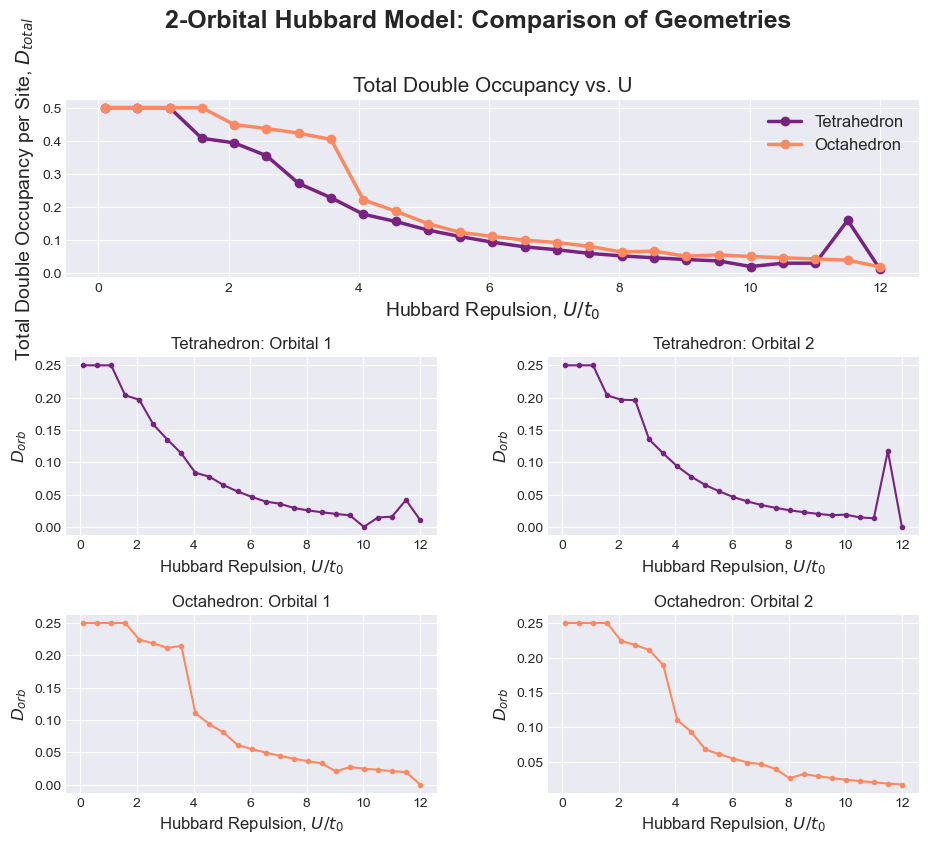


Analysis completed in 1.85 seconds.

======================= MAIN MENU ========================
Choose an analysis type:
   1. 2-Orbital Comparative Analysis (Fast Calculation)

   0. Exit

--- 2-Orbital Comparative Analysis ---
This mode uses a fast, approximate solver for all calculations.

Setting baseline parameters for 2-orbital simulations:

Choose an analysis to perform:
   1. D vs. Hubbard U
   2. D vs. Inter-Orbital Hopping (t_orb)
   3. D vs. Intra-Orbital Hopping (t0)
   0. Back to Main Menu

Generating 2-Orbital Comparison Plot: D vs t_orb...
Calculating for Tetrahedron...
  -> Using Mean-Field Theory for Tetrahedron (2 orb, 8e).
  -> Using Mean-Field Theory for Tetrahedron (2 orb, 8e).
  -> Using Mean-Field Theory for Tetrahedron (2 orb, 8e).
  -> Using Mean-Field Theory for Tetrahedron (2 orb, 8e).
  -> Using Mean-Field Theory for Tetrahedron (2 orb, 8e).
  -> Using Mean-Field Theory for Tetrahedron (2 orb, 8e).
  -> Using Mean-Field Theory for Tetrahedron (2 orb, 8e).
 

/var/folders/84/c1f888hj3nl61gx1s2sy_krc0000gn/T/ipykernel_78786/462777599.py:316: UserWarning: This figure includes Axes that are not compatible with tight_layout, so results might be incorrect.
  plt.tight_layout(rect=[0, 0.03, 1, 0.95])


Plot saved to: plots/2Orb_Compare_Hubbard_D_vs_t_orb.png


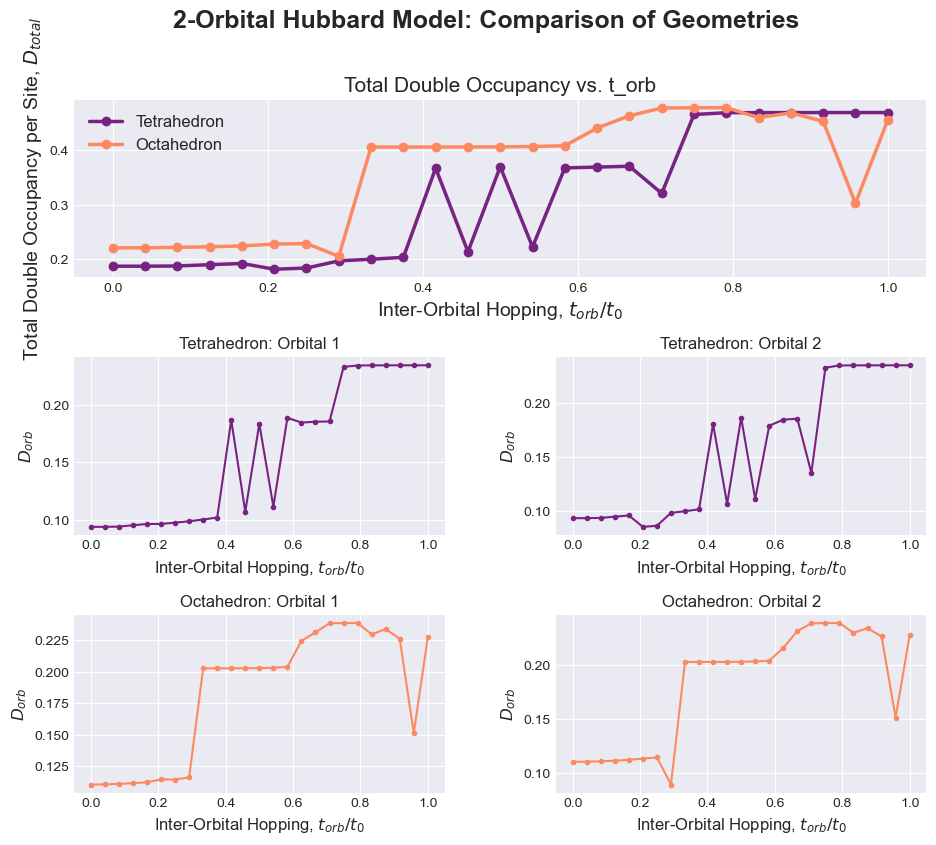


Analysis completed in 2.44 seconds.

======================= MAIN MENU ========================
Choose an analysis type:
   1. 2-Orbital Comparative Analysis (Fast Calculation)

   0. Exit

--- 2-Orbital Comparative Analysis ---
This mode uses a fast, approximate solver for all calculations.

Setting baseline parameters for 2-orbital simulations:

Choose an analysis to perform:
   1. D vs. Hubbard U
   2. D vs. Inter-Orbital Hopping (t_orb)
   3. D vs. Intra-Orbital Hopping (t0)
   0. Back to Main Menu

Generating 2-Orbital Comparison Plot: D vs t0...
Calculating for Tetrahedron...
  -> Using Mean-Field Theory for Tetrahedron (2 orb, 8e).
  -> Using Mean-Field Theory for Tetrahedron (2 orb, 8e).
  -> Using Mean-Field Theory for Tetrahedron (2 orb, 8e).
  -> Using Mean-Field Theory for Tetrahedron (2 orb, 8e).
  -> Using Mean-Field Theory for Tetrahedron (2 orb, 8e).
  -> Using Mean-Field Theory for Tetrahedron (2 orb, 8e).
  -> Using Mean-Field Theory for Tetrahedron (2 orb, 8e).
  ->

/var/folders/84/c1f888hj3nl61gx1s2sy_krc0000gn/T/ipykernel_78786/462777599.py:316: UserWarning: This figure includes Axes that are not compatible with tight_layout, so results might be incorrect.
  plt.tight_layout(rect=[0, 0.03, 1, 0.95])


Plot saved to: plots/2Orb_Compare_Hubbard_D_vs_t0.png


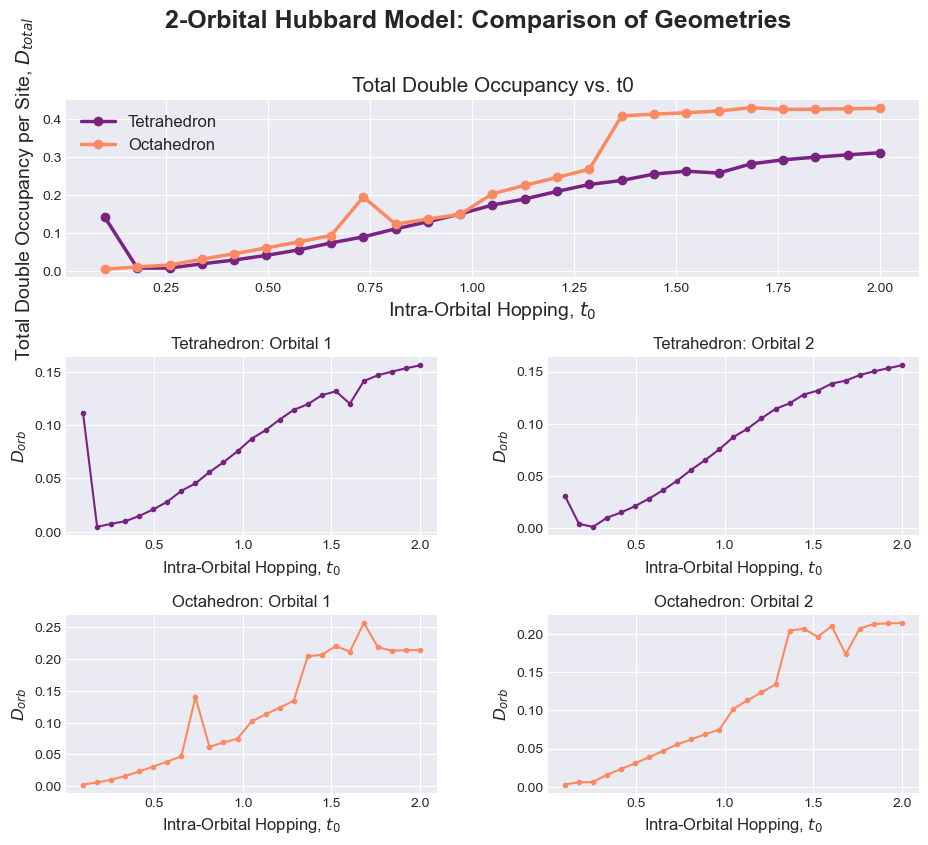


Analysis completed in 1.90 seconds.

======================= MAIN MENU ========================
Choose an analysis type:
   1. 2-Orbital Comparative Analysis (Fast Calculation)

   0. Exit
Exiting analysis.


In [4]:
import numpy as np
import matplotlib.pyplot as plt
import matplotlib.gridspec as gridspec
from scipy.linalg import eigh
from scipy.special import comb
from scipy.optimize import bisect
import os
import time
from typing import List, Dict, Tuple, Any

# --- Constants ---
HBAR = 1.0
E_CHARGE = -1.0
KB = 1.0
MAX_BASIS_DIM_ED = 10000 # Reduced ED limit for speed

# --- Geometry Definitions ---
GEOMETRIES = {
    "Tetrahedron": {
        "n_sites": 4,
        "coords": np.array([[1, 1, 1], [1, -1, -1], [-1, 1, -1], [-1, -1, 1]]) / np.sqrt(3.0),
        "edges": [(0, 1), (0, 2), (0, 3), (1, 2), (1, 3), (2, 3)],
    },
    "Octahedron": {
        "n_sites": 6,
        "coords": np.array([[1,0,0], [-1,0,0], [0,1,0], [0,-1,0], [0,0,1], [0,0,-1]]),
        "edges": [
            (0,2), (0,3), (0,4), (0,5), (1,2), (1,3), (1,4), (1,5),
            (2,4), (2,5), (3,4), (3,5)
        ],
    }
}

# --- Helper Functions ---
def bit_is_set(n: int, k: int) -> bool:
    return (n >> k) & 1

def ed_bitpos(site: int, orbital: int, spin: int, n_orbitals: int) -> int:
    return 2 * (site * n_orbitals + orbital) + spin

class SimulationParameters:
    """Container for all simulation parameters, now with multi-orbital support."""
    def __init__(self, geometry_name: str, n_orbitals: int = 1, t0: float = 1.0, 
                 t_orb: float = 0.0, U: float = 4.0, T: float = 0.1,
                 n_target_fill: float = 0.5, E_vec: np.ndarray = np.array([0.,0.,0.])):
        self.geometry_name = geometry_name
        self.n_orbitals = n_orbitals
        self.t0 = t0
        self.t_orb = t_orb
        self.U = U
        self.T = T
        self.beta = 1.0 / (KB * T) if T > 1e-9 else np.inf
        self.n_target_fill = n_target_fill
        self.E_vec = np.array(E_vec, dtype=float)
        self.E_amp = np.linalg.norm(self.E_vec)

# --- SOLVER: EXACT DIAGONALIZATION (Accurate but Slow) ---
class ExactDiagonalizationSolver:
    def __init__(self, params: SimulationParameters):
        self.params = params
        self.geom_info = GEOMETRIES[params.geometry_name]
        self.n_sites = self.geom_info["n_sites"]
        self.num_orbital_sites = self.n_sites * self.params.n_orbitals
        self.n_target_electrons = int(self.params.n_target_fill * 2 * self.num_orbital_sites)
        
        num_bits = 2 * self.num_orbital_sites
        if self.n_target_electrons > num_bits or self.n_target_electrons < 0:
            self.dim = 0
        else:
            self.dim = comb(num_bits, self.n_target_electrons, exact=True)

        if self.dim > MAX_BASIS_DIM_ED:
            raise ValueError(f"ED: Basis dim ({self.dim}) > {MAX_BASIS_DIM_ED}. Use MeanFieldSolver.")

        self.basis_states = self._create_basis()
        self.basis_map = {state: i for i, state in enumerate(self.basis_states)}
        print(f"  -> Using Exact Diagonalization for {params.geometry_name} ({params.n_orbitals} orb, {self.n_target_electrons}e). Dim={self.dim}")

    def _create_basis(self) -> List[int]:
        num_bits = 2 * self.num_orbital_sites
        if self.dim == 0: return []
        return [i for i in range(2**num_bits) if bin(i).count('1') == self.n_target_electrons]

    def _build_hamiltonian(self) -> np.ndarray:
        H = np.zeros((self.dim, self.dim), dtype=np.float64)
        p = self.params
        n_orb = p.n_orbitals
        for i, state in enumerate(self.basis_states):
            diag_energy = 0.0
            for s in range(self.n_sites):
                for o in range(n_orb):
                    if bit_is_set(state, ed_bitpos(s,o,0,n_orb)) and bit_is_set(state, ed_bitpos(s,o,1,n_orb)):
                        diag_energy += p.U
            H[i, i] = diag_energy
            for s1, s2 in self.geom_info["edges"]:
                for o in range(n_orb):
                    for spin in (0, 1):
                        b1, b2 = ed_bitpos(s1,o,spin,n_orb), ed_bitpos(s2,o,spin,n_orb)
                        if bit_is_set(state, b1) and not bit_is_set(state, b2):
                            j = self.basis_map.get(state ^ (1 << b1) | (1 << b2))
                            if j is not None: H[i, j] -= p.t0
                        if bit_is_set(state, b2) and not bit_is_set(state, b1):
                            j = self.basis_map.get(state ^ (1 << b2) | (1 << b1))
                            if j is not None: H[i, j] -= p.t0
            if n_orb > 1 and abs(p.t_orb) > 1e-9:
                for s in range(self.n_sites):
                    for o1 in range(n_orb):
                        for o2 in range(o1 + 1, n_orb):
                            for spin in (0, 1):
                                b1, b2 = ed_bitpos(s,o1,spin,n_orb), ed_bitpos(s,o2,spin,n_orb)
                                if bit_is_set(state, b1) and not bit_is_set(state, b2):
                                    j = self.basis_map.get(state ^ (1 << b1) | (1 << b2))
                                    if j is not None: H[i, j] -= p.t_orb
                                if bit_is_set(state, b2) and not bit_is_set(state, b1):
                                    j = self.basis_map.get(state ^ (1 << b2) | (1 << b1))
                                    if j is not None: H[i, j] -= p.t_orb
        return H

    def _get_d_operator_diagonal(self, orbital_index: int) -> np.ndarray:
        d_op = np.zeros(self.dim)
        for i, state in enumerate(self.basis_states):
            for s in range(self.n_sites):
                if bit_is_set(state, ed_bitpos(s,orbital_index,0,self.params.n_orbitals)) and bit_is_set(state, ed_bitpos(s,orbital_index,1,self.params.n_orbitals)):
                    d_op[i] += 1
        return d_op

    def solve(self) -> Dict[str, Any]:
        H = self._build_hamiltonian()
        evals, evecs = eigh(H)
        evals_shifted = evals - evals[0]
        d_expect_per_orbital = []
        for o in range(self.params.n_orbitals):
            d_op_diag_fock = self._get_d_operator_diagonal(o) / self.n_sites
            d_expect_per_state = np.einsum('ik,i,ik->k', evecs.conj(), d_op_diag_fock, evecs, optimize=True)
            d_expect_per_orbital.append(d_expect_per_state)
        if self.params.beta == np.inf:
            gs_d = [d[0] for d in d_expect_per_orbital]
            return {"total_D": np.sum(gs_d), "orbital_D": gs_d}
        boltzmann = np.exp(-self.params.beta * evals_shifted)
        Z = np.sum(boltzmann)
        if Z < 1e-12: return {"total_D": 0, "orbital_D": [0]*self.params.n_orbitals}
        thermal_avg_d = [np.sum(d * boltzmann) / Z for d in d_expect_per_orbital]
        return {"total_D": np.sum(thermal_avg_d), "orbital_D": thermal_avg_d}

# --- SOLVER: MEAN-FIELD THEORY (Fast but Approximate) ---
class MeanFieldSolver:
    def __init__(self, params: SimulationParameters, max_iter=100, tol=1e-5, mix=0.5):
        self.params = params
        self.geom_info = GEOMETRIES[params.geometry_name]
        self.n_sites = self.geom_info["n_sites"]
        self.n_orbitals = self.params.n_orbitals
        self.n_states = 2 * self.n_sites * self.n_orbitals
        self.n_target_electrons = int(self.params.n_target_fill * self.n_states)
        self.max_iter, self.tol, self.mix = max_iter, tol, mix
        print(f"  -> Using Mean-Field Theory for {params.geometry_name} ({params.n_orbitals} orb, {self.n_target_electrons}e).")

    def _idx(self, s, o, spin):
        return 2 * (s * self.n_orbitals + o) + spin

    def solve(self) -> Dict[str, Any]:
        p = self.params
        
        # Initial guess for occupations with a small random noise to break symmetry
        # and find the physically correct correlated ground state.
        n = np.full((self.n_sites, self.n_orbitals, 2), self.params.n_target_fill)
        n += 1e-4 * (np.random.rand(self.n_sites, self.n_orbitals, 2) - 0.5)

        for i in range(self.max_iter):
            H_mf = np.zeros((self.n_states, self.n_states), dtype=np.float64)
            # Build MF Hamiltonian
            for s in range(self.n_sites):
                for o in range(self.n_orbitals):
                    for spin in (0, 1):
                        idx = self._idx(s, o, spin)
                        H_mf[idx, idx] += p.U * n[s, o, 1 - spin]
            # Hopping terms
            for s1, s2 in self.geom_info["edges"]:
                for o in range(self.n_orbitals):
                    for spin in (0, 1):
                        idx1, idx2 = self._idx(s1, o, spin), self._idx(s2, o, spin)
                        H_mf[idx1, idx2] -= p.t0
                        H_mf[idx2, idx1] -= p.t0
            if self.n_orbitals > 1 and abs(p.t_orb) > 1e-9:
                for s in range(self.n_sites):
                    for o1 in range(self.n_orbitals):
                        for o2 in range(o1 + 1, self.n_orbitals):
                            for spin in (0, 1):
                                idx1, idx2 = self._idx(s, o1, spin), self._idx(s, o2, spin)
                                H_mf[idx1, idx2] -= p.t_orb
                                H_mf[idx2, idx1] -= p.t_orb

            # Diagonalize and find chemical potential
            evals, evecs = eigh(H_mf)
            
            def electron_sum(mu):
                if p.beta == np.inf: # T=0 case
                    return np.sum(evals < mu)
                return np.sum(1.0 / (1.0 + np.exp(p.beta * (evals - mu))))

            mu_bounds = [evals[0] - 10*p.U, evals[-1] + 10*p.U]
            if mu_bounds[0] >= mu_bounds[1]: mu_bounds[0] = mu_bounds[1] -1
            
            try:
                mu = bisect(lambda mu: electron_sum(mu) - self.n_target_electrons, *mu_bounds, xtol=1e-6)
            except ValueError:
                if electron_sum(mu_bounds[0]) > self.n_target_electrons: mu = mu_bounds[0]
                else: mu = mu_bounds[1]

            # Calculate new occupations
            if p.beta == np.inf:
                fermi_factors = (evals < mu).astype(float)
            else:
                fermi_factors = 1.0 / (1.0 + np.exp(p.beta * (evals - mu)))
            
            n_new = np.zeros_like(n)
            for s in range(self.n_sites):
                for o in range(self.n_orbitals):
                    for spin in (0, 1):
                        idx = self._idx(s, o, spin)
                        n_new[s, o, spin] = np.sum(np.abs(evecs[idx, :])**2 * fermi_factors)
            
            if np.max(np.abs(n - n_new)) < self.tol:
                break
            n = self.mix * n_new + (1 - self.mix) * n

        # Calculate double occupancy from converged occupations
        d_per_orbital = [np.mean(n[:, o, 0] * n[:, o, 1]) for o in range(self.n_orbitals)]
        return {"total_D": np.sum(d_per_orbital), "orbital_D": d_per_orbital}

# --- PLOTTING UTILITY ---
class Plotter:
    def __init__(self, output_dir: str = "plots"):
        self.output_dir = output_dir
        os.makedirs(output_dir, exist_ok=True)
        # Using a professional color palette
        self.color_cycle_comp = [plt.cm.magma(0.35), plt.cm.magma(0.75)]

    def _get_solver(self, params: SimulationParameters, solver_type: str):
        if solver_type == 'exact':
            return ExactDiagonalizationSolver(params)
        elif solver_type == 'mean_field':
            return MeanFieldSolver(params)
        raise ValueError(f"Unknown solver type: {solver_type}")

    def _create_params(self, base: SimulationParameters, sweep_vars: Dict[str, Any]) -> SimulationParameters:
        p_dict = {
            'geometry_name': base.geometry_name, 'n_orbitals': base.n_orbitals,
            't0': base.t0, 't_orb': base.t_orb, 'U': base.U, 'T': base.T,
            'n_target_fill': base.n_target_fill, 'E_vec': base.E_vec,
        }
        p_dict.update(sweep_vars)
        return SimulationParameters(**p_dict)

    def run_and_plot_2orbital_comparison(self, x_param_name, x_values, x_label, baseline_params, log_scale=False):
        print(f"\nGenerating 2-Orbital Comparison Plot: D vs {x_param_name}...")
        
        # Apply the seaborn style for better aesthetics
        with plt.style.context('seaborn-v0_8-darkgrid'):
            fig = plt.figure(figsize=(11, 9))
            gs = gridspec.GridSpec(3, 2, figure=fig, hspace=0.45, wspace=0.3)
            ax_main = fig.add_subplot(gs[0, :])
            ax_t_orb1 = fig.add_subplot(gs[1, 0])
            ax_t_orb2 = fig.add_subplot(gs[1, 1])
            ax_o_orb1 = fig.add_subplot(gs[2, 0])
            ax_o_orb2 = fig.add_subplot(gs[2, 1])

            geometries = ["Tetrahedron", "Octahedron"]
            solvers = ['mean_field', 'mean_field'] 

            for i, (geom, solver_str) in enumerate(zip(geometries, solvers)):
                total_d, orb1_d, orb2_d = [], [], []
                geom_base = self._create_params(baseline_params, {'geometry_name': geom})
                
                print(f"Calculating for {geom}...")
                for x_val in x_values:
                    p = self._create_params(geom_base, {x_param_name: x_val})
                    try:
                        solver = self._get_solver(p, solver_str)
                        res = solver.solve()
                        total_d.append(res['total_D'])
                        orb1_d.append(res['orbital_D'][0])
                        orb2_d.append(res['orbital_D'][1])
                    except Exception as e:
                        print(f"Error during {geom} calc at {x_param_name}={x_val}: {e}")
                        total_d.append(np.nan); orb1_d.append(np.nan); orb2_d.append(np.nan)
                
                # Removed "(MFT)" from the label for a cleaner look
                label = f"{geom}"
                color = self.color_cycle_comp[i]
                ax_main.plot(x_values, total_d, 'o-', label=label, color=color, lw=2.5, markersize=6)
                if geom == "Tetrahedron":
                    ax_t_orb1.plot(x_values, orb1_d, '.-', color=color, lw=1.5)
                    ax_t_orb2.plot(x_values, orb2_d, '.-', color=color, lw=1.5)
                else: # Octahedron
                    ax_o_orb1.plot(x_values, orb1_d, '.-', color=color, lw=1.5)
                    ax_o_orb2.plot(x_values, orb2_d, '.-', color=color, lw=1.5)
            
            if log_scale: ax_main.set_xscale('log')
            ax_main.set_xlabel(x_label, fontsize=14)
            ax_main.set_ylabel('Total Double Occupancy per Site, $D_{total}$', fontsize=14)
            
            # Updated title to be more general
            fig.suptitle(f'2-Orbital Hubbard Model: Comparison of Geometries', fontsize=18, weight='bold')
            ax_main.set_title(f'Total Double Occupancy vs. {x_param_name}', fontsize=15)
            ax_main.legend(fontsize=12)
            
            # Updated inset titles
            ax_t_orb1.set_title("Tetrahedron: Orbital 1", fontsize=12); ax_t_orb1.set_ylabel("$D_{orb}$", fontsize=12)
            ax_t_orb2.set_title("Tetrahedron: Orbital 2", fontsize=12); ax_t_orb2.set_ylabel("$D_{orb}$", fontsize=12)
            ax_o_orb1.set_title("Octahedron: Orbital 1", fontsize=12); ax_o_orb1.set_ylabel("$D_{orb}$", fontsize=12)
            ax_o_orb2.set_title("Octahedron: Orbital 2", fontsize=12); ax_o_orb2.set_ylabel("$D_{orb}$", fontsize=12)
            for ax in [ax_t_orb1, ax_t_orb2, ax_o_orb1, ax_o_orb2]:
                if log_scale: ax.set_xscale('log')
                ax.set_xlabel(x_label, fontsize=12)
            
            plt.tight_layout(rect=[0, 0.03, 1, 0.95])
            filename = f"2Orb_Compare_Hubbard_D_vs_{x_param_name}.png"
            filepath = os.path.join(self.output_dir, filename)
            plt.savefig(filepath, dpi=300, bbox_inches='tight')
            print(f"Plot saved to: {filepath}")
            plt.show()

# --- MAIN DRIVER ---
def main():
    print("="*60)
    print(" High-Performance Multi-Orbital 3D Hubbard Analyzer ".center(60, "="))
    print("="*60)
    plotter = Plotter()

    while True:
        print("\n" + "="*23 + " MAIN MENU " + "="*24)
        print("Choose an analysis type:")
        print("   1. 2-Orbital Comparative Analysis (Fast Calculation)")
        print("\n   0. Exit")
        
        choice = input("Enter choice: ")
        if choice == '1':
            run_2orbital_comparative_menu(plotter)
        elif choice == '0':
            print("Exiting analysis.")
            break
        else:
            print("Invalid choice, please try again.")

def run_2orbital_comparative_menu(plotter):
    print("\n--- 2-Orbital Comparative Analysis ---")
    print("This mode uses a fast, approximate solver for all calculations.")
    
    print("\nSetting baseline parameters for 2-orbital simulations:")
    t0 = float(input("   Enter baseline intra-orbital hopping t0 (e.g., 1.0): "))
    t_orb = float(input("   Enter baseline inter-orbital hopping t_orb (e.g., 0.2): "))
    U = float(input("   Enter baseline Hubbard U (e.g., 4.0): "))
    T = float(input("   Enter baseline Temperature T (e.g., 0.1): "))
    
    base_params = SimulationParameters(
        geometry_name="N/A", n_orbitals=2, t0=t0, t_orb=t_orb, U=U, T=T
    )

    print("\nChoose an analysis to perform:")
    print("   1. D vs. Hubbard U")
    print("   2. D vs. Inter-Orbital Hopping (t_orb)")
    print("   3. D vs. Intra-Orbital Hopping (t0)")
    print("   0. Back to Main Menu")
    
    choice = input("Enter choice: ")
    start_time = time.time()
    try:
        if choice == '1':
            x_vals = np.linspace(0.1, 12.0, 25)
            plotter.run_and_plot_2orbital_comparison('U', x_vals, 'Hubbard Repulsion, $U/t_0$', base_params)
        elif choice == '2':
            x_vals = np.linspace(0, 1.0, 25)
            plotter.run_and_plot_2orbital_comparison('t_orb', x_vals, 'Inter-Orbital Hopping, $t_{orb}/t_0$', base_params)
        elif choice == '3':
            x_vals = np.linspace(0.1, 2.0, 25)
            plotter.run_and_plot_2orbital_comparison('t0', x_vals, 'Intra-Orbital Hopping, $t_0$', base_params)
        elif choice == '0':
            return
    except (ValueError, np.linalg.LinAlgError) as e:
        print(f"\n--- An error occurred during calculation: ---")
        print(e)
    
    end_time = time.time()
    print(f"\nAnalysis completed in {end_time - start_time:.2f} seconds.")


if __name__ == '__main__':
    main()


In [3]:
import numpy as np
import matplotlib.pyplot as plt
import matplotlib.gridspec as gridspec
from scipy.linalg import eigh
from scipy.optimize import bisect
import os
import time
from typing import List, Dict, Any, Union

# --- Constants ---
KB = 1.0

# --- Pre-calculate coordinates to avoid self-reference in dictionary ---
sc_coords = np.array([[i,j,k] for i in [0,1] for j in [0,1] for k in [0,1]])
bcc_coords = np.array([[0,0,0], [1,0,0], [0,1,0], [0,0,1], [1,1,0], [1,0,1], [0,1,1], [1,1,1]]) - 0.5
fcc_coords = np.array([
    [0,0,0], [0.5,0.5,0], [0.5,0,0.5], [0,0.5,0.5], # Center and face-centers
    [1,0,0], [0,1,0], [0,0,1], [1,1,0], [1,0,1], [0,1,1],
    [0.5,1,0.5], [1,0.5,0.5], [1,1,1], [0.5, 0.5, 1]
])

# --- Geometry Definitions (Now including SC, BCC, FCC) ---
GEOMETRIES = {
    "Tetrahedron": {
        "n_sites": 4,
        "coordination": 3,
        "coords": np.array([[1, 1, 1], [1, -1, -1], [-1, 1, -1], [-1, -1, 1]]) / np.sqrt(3.0),
        "edges": [(0, 1), (0, 2), (0, 3), (1, 2), (1, 3), (2, 3)],
    },
    "Octahedron": {
        "n_sites": 6,
        "coordination": 4,
        "coords": np.array([[1,0,0], [-1,0,0], [0,1,0], [0,-1,0], [0,0,1], [0,0,-1]]),
        "edges": [
            (0,2), (0,3), (0,4), (0,5), (1,2), (1,3), (1,4), (1,5),
            (2,4), (2,5), (3,4), (3,5)
        ],
    },
    "SC": {
        "n_sites": 8, "coordination": 6, "coords": sc_coords,
        "edges": [(i,j) for i in range(8) for j in range(i+1, 8) if np.linalg.norm(sc_coords[i] - sc_coords[j]) < 1.1],
    },
    "BCC": {
        "n_sites": 8, "coordination": 8, "coords": bcc_coords,
        "edges": [(i,j) for i in range(8) for j in range(i+1, 8) if np.linalg.norm(bcc_coords[i] - bcc_coords[j]) < 1.0],
    },
    "FCC": {
        "n_sites": 14, "coordination": 12, "coords": fcc_coords,
        "edges": [(i,j) for i in range(14) for j in range(i+1, 14) if abs(np.linalg.norm(fcc_coords[i] - fcc_coords[j]) - 1/np.sqrt(2)) < 0.1],
    }
}

class SimulationParameters:
    """Container for all simulation parameters."""
    def __init__(self, geometry_name: str, n_orbitals: int = 1, t0: float = 1.0,
                 t_orb: float = 0.0, U: float = 4.0, T: float = 0.1,
                 n_target_fill: float = 0.5, E_vec: np.ndarray = np.array([0.,0.,0.])):
        self.geometry_name = geometry_name
        self.n_orbitals = n_orbitals
        self.t0 = t0
        self.t_orb = t_orb
        self.U = U
        self.T = T
        self.beta = 1.0 / (KB * T) if T > 1e-9 else np.inf
        self.n_target_fill = n_target_fill
        self.E_vec = np.array(E_vec, dtype=float)
        self.E_amp = np.linalg.norm(self.E_vec)

# --- SOLVER: MEAN-FIELD THEORY (Fast and Effective for these systems) ---
class MeanFieldSolver:
    """
    A fast, self-consistent mean-field solver for the multi-orbital Hubbard model.
    """
    def __init__(self, params: SimulationParameters, max_iter=150, tol=1e-6, mix=0.4):
        self.params = params
        self.geom_info = GEOMETRIES[params.geometry_name]
        self.n_sites = self.geom_info["n_sites"]
        self.n_orbitals = self.params.n_orbitals
        self.n_states = 2 * self.n_sites * self.n_orbitals
        self.n_target_electrons = int(round(self.params.n_target_fill * self.n_states))
        self.max_iter, self.tol, self.mix = max_iter, tol, mix

    def _idx(self, s, o, spin):
        return 2 * (s * self.n_orbitals + o) + spin

    def solve(self) -> Dict[str, Any]:
        p = self.params
        n = np.full((self.n_sites, self.n_orbitals, 2), p.n_target_fill)
        n += 1e-4 * (np.random.rand(self.n_sites, self.n_orbitals, 2) - 0.5)

        for i in range(self.max_iter):
            H_mf = np.zeros((self.n_states, self.n_states), dtype=np.float64)
            
            for s in range(self.n_sites):
                for o in range(self.n_orbitals):
                    H_mf[self._idx(s,o,0), self._idx(s,o,0)] += p.U * n[s, o, 1]
                    H_mf[self._idx(s,o,1), self._idx(s,o,1)] += p.U * n[s, o, 0]
            
            if p.E_amp > 1e-9:
                for s in range(self.n_sites):
                    potential = -np.dot(self.geom_info["coords"][s], p.E_vec)
                    for o in range(self.n_orbitals):
                        for spin in (0,1):
                            H_mf[self._idx(s,o,spin), self._idx(s,o,spin)] += potential

            for s1, s2 in self.geom_info["edges"]:
                for o in range(self.n_orbitals):
                    for spin in (0, 1):
                        idx1, idx2 = self._idx(s1, o, spin), self._idx(s2, o, spin)
                        H_mf[idx1, idx2] -= p.t0
                        H_mf[idx2, idx1] -= p.t0
            
            if self.n_orbitals > 1 and abs(p.t_orb) > 1e-9:
                for s in range(self.n_sites):
                    for o1 in range(self.n_orbitals):
                        for o2 in range(o1 + 1, self.n_orbitals):
                            for spin in (0, 1):
                                idx1, idx2 = self._idx(s, o1, spin), self._idx(s, o2, spin)
                                H_mf[idx1, idx2] -= p.t_orb
                                H_mf[idx2, idx1] -= p.t_orb

            evals, evecs = eigh(H_mf)
            
            def electron_sum(mu):
                if p.beta == np.inf: return np.sum(evals < mu)
                return np.sum(1.0 / (1.0 + np.exp(p.beta * (evals - mu))))

            mu_bounds = [evals[0] - 2*p.U, evals[-1] + 2*p.U]
            try:
                mu = bisect(lambda mu: electron_sum(mu) - self.n_target_electrons, *mu_bounds, xtol=1e-7)
            except ValueError:
                mu = mu_bounds[0] if electron_sum(mu_bounds[0]) > self.n_target_electrons else mu_bounds[1]

            fermi_factors = 1.0 / (1.0 + np.exp(p.beta * (evals - mu))) if p.beta != np.inf else (evals < mu).astype(float)
            
            n_new = np.zeros_like(n)
            for s in range(self.n_sites):
                for o in range(self.n_orbitals):
                    for spin in (0, 1):
                        idx = self._idx(s, o, spin)
                        n_new[s, o, spin] = np.sum(np.abs(evecs[idx, :])**2 * fermi_factors)
            
            if np.max(np.abs(n - n_new)) < self.tol: break
            n = self.mix * n_new + (1 - self.mix) * n

        d_per_site = np.sum([n[:, o, 0] * n[:, o, 1] for o in range(self.n_orbitals)], axis=0)
        return {"total_D": np.mean(d_per_site), "final_n": n}

# --- PLOTTING ENGINE ---
class PlottingEngine:
    def __init__(self, output_dir: str = "plots1"):
        self.output_dir = output_dir
        os.makedirs(output_dir, exist_ok=True)
        plt.style.use('seaborn-v0_8-whitegrid')
        self.color_map = plt.cm.viridis
        self.geometries_to_plot = ["Tetrahedron", "Octahedron", "SC", "BCC", "FCC"]

    def _get_solver(self, params: SimulationParameters):
        return MeanFieldSolver(params)
        
    def _get_doped_fill(self, geom_name: str, n_orbitals: int) -> float:
        """Calculates the filling fraction for N_electrons = N_half - 1."""
        n_states = 2 * GEOMETRIES[geom_name]["n_sites"] * n_orbitals
        return 0.5 - (1.0 / n_states)

    def _create_params(self, base_params_dict: Dict[str, Any], sweep_vars: Dict[str, Any]) -> SimulationParameters:
        p_dict = base_params_dict.copy()
        p_dict.update(sweep_vars)
        
        if 'E_amp' in sweep_vars:
             e_amp = p_dict.pop('E_amp')
             direction = np.array(p_dict['E_vec'])
             norm = np.linalg.norm(direction)
             direction = direction / norm if norm > 1e-9 else np.array([1.,0.,0.])
             p_dict['E_vec'] = e_amp * direction
             
        return SimulationParameters(**p_dict)

    def _run_and_plot_sweep(self, ax, sweep_param_name: str, sweep_values: np.ndarray, base_p_dict: Dict[str, Any], filling_type: Union[float, str]):
        """Helper function to run a parameter sweep and plot the results."""
        colors = self.color_map(np.linspace(0, 0.9, len(self.geometries_to_plot)))
        for i, geom_name in enumerate(self.geometries_to_plot):
            y_values = []
            geom_base_dict = {**base_p_dict, 'geometry_name': geom_name}
            
            if filling_type == 'doped':
                n_fill = self._get_doped_fill(geom_name, geom_base_dict['n_orbitals'])
                geom_base_dict['n_target_fill'] = n_fill
            
            for val in sweep_values:
                p = self._create_params(geom_base_dict, {sweep_param_name: val})
                solver = self._get_solver(p)
                res = solver.solve()
                y_values.append(res['total_D'])
            
            label = f"{geom_name} (Z={GEOMETRIES[geom_name]['coordination']})"
            marker = '^-' if sweep_param_name == 'E_amp' else 'o-'
            ax.plot(sweep_values, y_values, marker, label=label, color=colors[i], lw=2)

    def plot_figure_1_geom_vs_U(self, u_values: np.ndarray, base_params: SimulationParameters):
        print("Generating Figure 1 (Comparison): Geometric control (D vs U)...")
        # Removed sharey=True to allow independent y-axis ticks and labels
        fig, axes = plt.subplots(1, 2, figsize=(17, 6))
        fig.suptitle('Figure 1: Geometric Control of Pairing vs. Hubbard U', fontsize=18, weight='bold')
        
        base_p_dict = {'n_orbitals': 1, 't0': base_params.t0, 'T': base_params.T, 'E_vec': [0,0,0]}

        # (a) Half-Filling
        self._run_and_plot_sweep(axes[0], 'U', u_values, {**base_p_dict, 'n_target_fill': 0.5}, 0.5)
        axes[0].set_title('(a) Half-Filling', fontsize=14)
        axes[0].legend(fontsize=11, title="Lattice (Coordination Z)")

        # (b) Doped (1-off)
        self._run_and_plot_sweep(axes[1], 'U', u_values, base_p_dict, 'doped')
        axes[1].set_title('(b) Doped (1-off Half-Filling)', fontsize=14)

        # Set labels for BOTH subplots
        for ax in axes:
            ax.set_xlabel('Hubbard Repulsion, $U/t_0$', fontsize=14)
            ax.set_ylabel('Double Occupancy per Site, $D$', fontsize=14)
            ax.grid(True, which='both', linestyle='--', linewidth=0.5)

        plt.tight_layout(rect=[0, 0.03, 1, 0.95])
        filepath = os.path.join(self.output_dir, "figure1_geom_vs_U_comparison.png")
        plt.savefig(filepath, dpi=300)
        print(f"  -> Saved: {filepath}")
        plt.close()

    def plot_figure_2_orbital_control(self, torb_values: np.ndarray, base_params: SimulationParameters, filling_type: Union[float, str]):
        """Generates Figure 2 for a specific filling with full labels on all subplots."""
        filling_str = "Half-Filling" if filling_type == 0.5 else "Doped (1-off)"
        print(f"Generating Figure 2 ({filling_str}): Universal orbital control...")
        
        # Removed sharex and sharey to ensure all subplots get their own labels and ticks.
        fig, axes = plt.subplots(2, 3, figsize=(19, 11))
        title = f'Figure 2: Universal Suppression of Pairing by $t_{{orb}}$ — {filling_str}'
        fig.suptitle(title, fontsize=20, weight='bold')
        axes = axes.flatten()

        colors = self.color_map(np.linspace(0.1, 0.9, 3))
        base_p_dict = {'n_orbitals': 2, 't0': base_params.t0, 'T': base_params.T, 'E_vec': [0,0,0]}

        for i, geom_name in enumerate(self.geometries_to_plot):
            ax = axes[i]
            geom_base_dict = {**base_p_dict, 'geometry_name': geom_name}
            
            if filling_type == 'doped':
                geom_base_dict['n_target_fill'] = self._get_doped_fill(geom_name, 2)

            for j, u_val in enumerate([4.0, 8.0, 12.0]):
                y_values = []
                for t_orb_val in torb_values:
                    p = self._create_params({**geom_base_dict, 'U': u_val}, {'t_orb': t_orb_val})
                    solver = self._get_solver(p)
                    res = solver.solve()
                    y_values.append(res['total_D'])
                ax.plot(torb_values, y_values, 's-', label=f'$U={u_val:.0f}t_0$', color=colors[j], lw=2)
            
            ax.set_title(f'{geom_name}', fontsize=16)
            # Set labels for EVERY subplot
            ax.set_xlabel('Inter-Orbital Hopping, $t_{orb}/t_0$', fontsize=14)
            ax.set_ylabel('Total Double Occupancy, $D_{total}$', fontsize=14)
            ax.grid(True, which='both', linestyle='--', linewidth=0.5)
            ax.legend()

        for k in range(len(self.geometries_to_plot), len(axes)): axes[k].set_visible(False)
        plt.tight_layout(rect=[0, 0.03, 1, 0.95])
        
        filename = f"figure2_orbital_control_{'half_filling' if filling_type==0.5 else 'doped'}.png"
        filepath = os.path.join(self.output_dir, filename)
        plt.savefig(filepath, dpi=300)
        print(f"  -> Saved: {filepath}")
        plt.close()

    def plot_figure_3_thermal_effects(self, temp_values: np.ndarray, base_params: SimulationParameters):
        print("Generating Figure 3 (Comparison): Thermal effects on pairing...")
        fig, axes = plt.subplots(1, 2, figsize=(17, 6))
        fig.suptitle('Figure 3: Thermal Effects on Pairing ($U=8t_0$)', fontsize=18, weight='bold')

        base_p_dict = {'n_orbitals': 1, 't0': base_params.t0, 'U': 8.0, 'E_vec': [0,0,0]}

        # (a) Half-Filling
        self._run_and_plot_sweep(axes[0], 'T', temp_values, {**base_p_dict, 'n_target_fill': 0.5}, 0.5)
        axes[0].set_title('(a) Half-Filling', fontsize=14)
        axes[0].legend(fontsize=12)

        # (b) Doped (1-off)
        self._run_and_plot_sweep(axes[1], 'T', temp_values, base_p_dict, 'doped')
        axes[1].set_title('(b) Doped (1-off Half-Filling)', fontsize=14)
        
        y_max = 0
        for ax in axes:
            ax.set_xscale('log')
            ax.set_xlabel('Temperature, $k_B T/t_0$', fontsize=14)
            ax.set_ylabel('Double Occupancy per Site, $D$', fontsize=14)
            ax.grid(True, which='both', linestyle='--', linewidth=0.5)
            if ax.get_ylim()[1] > y_max:
                y_max = ax.get_ylim()[1]
        
        # Set a common y-limit to better compare saturation points
        for ax in axes:
            ax.set_ylim(0, y_max * 1.05)

        plt.tight_layout(rect=[0, 0.03, 1, 0.95])
        filepath = os.path.join(self.output_dir, "figure3_thermal_effects_comparison.png")
        plt.savefig(filepath, dpi=300)
        print(f"  -> Saved: {filepath}")
        plt.close()

    def plot_figure_4_efield_effects(self, efield_values: np.ndarray, base_params: SimulationParameters):
        print("Generating Figure 4 (Comparison): Electric field induced pairing...")
        fig, axes = plt.subplots(1, 2, figsize=(17, 6))
        fig.suptitle('Figure 4: Electric Field Induced Pairing ($U=4t_0$)', fontsize=18, weight='bold')

        base_p_dict = {'n_orbitals': 1, 't0': base_params.t0, 'U': 4.0, 'T': base_params.T, 'E_vec': [1.0, 0.5, 0.25]}

        # (a) Half-Filling
        self._run_and_plot_sweep(axes[0], 'E_amp', efield_values, {**base_p_dict, 'n_target_fill': 0.5}, 0.5)
        axes[0].set_title('(a) Half-Filling', fontsize=14)
        axes[0].legend(fontsize=12)

        # (b) Doped (1-off)
        self._run_and_plot_sweep(axes[1], 'E_amp', efield_values, base_p_dict, 'doped')
        axes[1].set_title('(b) Doped (1-off Half-Filling)', fontsize=14)
        
        for ax in axes:
            ax.set_xlabel('E-Field Amplitude, $|E|a/t_0$', fontsize=14)
            ax.set_ylabel('Double Occupancy per Site, $D$', fontsize=14)
            ax.grid(True, which='both', linestyle='--', linewidth=0.5)

        plt.tight_layout(rect=[0, 0.03, 1, 0.95])
        filepath = os.path.join(self.output_dir, "figure4_efield_effects_comparison.png")
        plt.savefig(filepath, dpi=300)
        print(f"  -> Saved: {filepath}")
        plt.close()

    def plot_figure_5_phase_diagram(self, u_values: np.ndarray, torb_values: np.ndarray, base_params: SimulationParameters):
        print("Generating Figure 5 (Comparison): D(U, t_orb) phase diagram...")
        fig, axes = plt.subplots(1, 2, figsize=(19, 7))
        geom_name = "Octahedron"
        fig.suptitle(f'Figure 5: Pairing Phase Diagram for {geom_name}', fontsize=18, weight='bold')

        base_p_dict = {'n_orbitals': 2, 't0': base_params.t0, 'T': base_params.T, 'E_vec': [0,0,0], 'geometry_name': geom_name}
        
        fillings = [0.5, 'doped']
        titles = ['(a) Half-Filling', '(b) Doped (1-off Half-Filling)']
        
        all_D_values = []
        for filling_type in fillings:
            D_values = np.zeros((len(torb_values), len(u_values)))
            p_dict = base_p_dict.copy()
            if filling_type == 'doped':
                p_dict['n_target_fill'] = self._get_doped_fill(geom_name, 2)
            
            for i, t_orb in enumerate(torb_values):
                for j, u in enumerate(u_values):
                    p = self._create_params(p_dict, {'U': u, 't_orb': t_orb})
                    solver = self._get_solver(p)
                    res = solver.solve()
                    D_values[i, j] = res['total_D']
            all_D_values.append(D_values)

        X, Y = np.meshgrid(u_values, torb_values)
        vmin = min(np.min(d) for d in all_D_values)
        vmax = max(np.max(d) for d in all_D_values)

        for i, ax in enumerate(axes):
            contour = ax.contourf(X, Y, all_D_values[i], levels=20, cmap='magma', vmin=vmin, vmax=vmax)
            ax.set_title(titles[i], fontsize=14)
            ax.set_xlabel('Hubbard Repulsion, $U/t_0$', fontsize=14)
            ax.set_ylabel('Inter-Orbital Hopping, $t_{orb}/t_0$', fontsize=14)

        fig.subplots_adjust(right=0.85)
        cbar_ax = fig.add_axes([0.88, 0.15, 0.03, 0.7])
        cbar = fig.colorbar(contour, cax=cbar_ax)
        cbar.set_label('Total Double Occupancy, $D_{total}$', fontsize=14)
        
        filepath = os.path.join(self.output_dir, "figure5_phase_diagram_comparison.png")
        plt.savefig(filepath, dpi=300)
        print(f"  -> Saved: {filepath}")
        plt.close()

# --- MAIN DRIVER SCRIPT ---
def main():
    print("="*65)
    print(" Automated Plot Generator for Multi-Orbital Hubbard Paper ".center(65))
    print(" (Including Half-Filling and Doped Case Comparisons) ".center(65))
    print("="*65)
    
    start_time = time.time()
    
    engine = PlottingEngine(output_dir="plots1")
    base_params = SimulationParameters(geometry_name="N/A", t0=1.0, T=0.01)

    # --- Generate Figure 1 (Comparison Plot) ---
    u_vals_fig1 = np.linspace(0.1, 15.0, 30)
    engine.plot_figure_1_geom_vs_U(u_vals_fig1, base_params)

    # --- Generate Figure 2 (Two separate plots for clarity) ---
    torb_vals_fig2 = np.linspace(0, 2.0, 25)
    engine.plot_figure_2_orbital_control(torb_vals_fig2, base_params, filling_type=0.5)
    engine.plot_figure_2_orbital_control(torb_vals_fig2, base_params, filling_type='doped')

    # --- Generate Figure 3 (Comparison Plot) ---
    temp_vals_fig3 = np.logspace(-2, 1.5, 40)
    engine.plot_figure_3_thermal_effects(temp_vals_fig3, base_params)
    
    # --- Generate Figure 4 (Comparison Plot) ---
    efield_vals_fig4 = np.linspace(0, 6.0, 30)
    engine.plot_figure_4_efield_effects(efield_vals_fig4, base_params)

    # --- Generate Figure 5 (Comparison Plot) ---
    u_vals_fig5 = np.linspace(0.1, 15.0, 25)
    torb_vals_fig5 = np.linspace(0, 2.0, 25)
    engine.plot_figure_5_phase_diagram(u_vals_fig5, torb_vals_fig5, base_params)

    end_time = time.time()
    print("\n" + "-"*65)
    print(f"All figures generated successfully in {end_time - start_time:.2f} seconds.")
    print(f"Output saved to directory: '{engine.output_dir}/'")
    print("-"*65)

if __name__ == '__main__':
    main()

     Automated Plot Generator for Multi-Orbital Hubbard Paper    
       (Including Half-Filling and Doped Case Comparisons)       
Generating Figure 1 (Comparison): Geometric control (D vs U)...


/var/folders/84/c1f888hj3nl61gx1s2sy_krc0000gn/T/ipykernel_34025/2446949173.py:126: RuntimeWarning: overflow encountered in exp
  return np.sum(1.0 / (1.0 + np.exp(p.beta * (evals - mu))))
/var/folders/84/c1f888hj3nl61gx1s2sy_krc0000gn/T/ipykernel_34025/2446949173.py:134: RuntimeWarning: overflow encountered in exp
  fermi_factors = 1.0 / (1.0 + np.exp(p.beta * (evals - mu))) if p.beta != np.inf else (evals < mu).astype(float)


  -> Saved: plots1/figure1_geom_vs_U_comparison.png
Generating Figure 2 (Half-Filling): Universal orbital control...
  -> Saved: plots1/figure2_orbital_control_half_filling.png
Generating Figure 2 (Doped (1-off)): Universal orbital control...
  -> Saved: plots1/figure2_orbital_control_doped.png
Generating Figure 3 (Comparison): Thermal effects on pairing...
  -> Saved: plots1/figure3_thermal_effects_comparison.png
Generating Figure 4 (Comparison): Electric field induced pairing...
  -> Saved: plots1/figure4_efield_effects_comparison.png
Generating Figure 5 (Comparison): D(U, t_orb) phase diagram...
  -> Saved: plots1/figure5_phase_diagram_comparison.png

-----------------------------------------------------------------
All figures generated successfully in 88.87 seconds.
Output saved to directory: 'plots1/'
-----------------------------------------------------------------
